# Deep Learning Mid Exam - Question 1

Nama    :Hazel Novero Winata
NIM     :2802519114
Kelas:  :LD09

Link Video: https://drive.google.com/drive/folders/1lSbGQjIpGk4jZoP948kNKvmYVtNyEmyr

# Data Understanding dan Problem Overview



## 1. Deskripsi Dataset
Dataset ini berisi data penjualan mobil bekas pada anak perusahaan dealer otomotif. Setiap baris data merepresentasikan satu unit kendaraan dengan berbagai atribut yang menggambarkan karakteristik mobil, kondisi penggunaan, serta informasi pasar.

Dataset terdiri dari **2000 observasi** dan **18 fitur**, yang dapat dikelompokkan sebagai berikut:

- **Informasi kendaraan:**
  - `engine`, `max_power`, `torque`, `mileage`, `seats`
- **Informasi penggunaan:**
  - `year`, `km_driven`, `owner`
- **Informasi pasar & lokasi:**
  - `Region`, `State or Province`, `City`
- **Informasi transaksi:**
  - `selling_price` (harga jual dalam USD)

Selain itu, terdapat beberapa fitur kategorikal seperti:
- `fuel`, `seller_type`, `transmission`, dan `name` (brand mobil)

---

## 2. Karakteristik Data
Dataset ini memiliki kombinasi:
- **Numerical features** (misalnya: `selling_price`, `km_driven`, `engine`)
- **Categorical features** (misalnya: `fuel`, `seller_type`, `owner`)
- **Mixed-format features** (misalnya: `torque`, yang mengandung teks dan angka)

Selain itu, dari observasi awal terdapat potensi:
- Missing values
- Nilai tidak konsisten (contoh: tahun tidak realistis, nilai negatif pada fitur tertentu)
- Fitur dengan banyak kategori (high cardinality), seperti `City`

Hal ini menunjukkan bahwa dataset memerlukan proses preprocessing sebelum digunakan untuk modeling.

---

## 3. Tujuan Analisis
Tujuan utama dari analisis ini adalah:

> Membangun model yang dapat memprediksi harga jual mobil bekas (`selling_price`) berdasarkan karakteristik kendaraan dan informasi terkait lainnya.

Model yang dihasilkan diharapkan mampu:
- Memberikan estimasi harga yang akurat
- Membantu pengambilan keputusan dalam penentuan harga jual
- Mengidentifikasi faktor-faktor yang memengaruhi harga kendaraan

Karena variabel target berupa nilai numerik (harga dalam USD), maka permasalahan ini dikategorikan sebagai **regression problem**.

---

## 4. Pemahaman Awal terhadap Variabel Target
Variabel target dalam dataset ini adalah:
- **`selling_price`**

Variabel ini bersifat kontinu dan dipengaruhi oleh berbagai faktor seperti:
- Usia kendaraan (`year`)
- Jarak tempuh (`km_driven`)
- Spesifikasi mesin (`engine`, `max_power`)
- Jenis bahan bakar (`fuel`)
- Kondisi kepemilikan (`owner`)

Dengan demikian, hubungan antara fitur dan target bersifat kompleks dan non-linear, sehingga pendekatan menggunakan model Artificial Neural Network (ANN) menjadi relevan untuk digunakan.

---

## 5. Deskripsi Setiap Kolom

Berikut adalah penjelasan singkat mengenai setiap kolom dalam dataset:

- **Sales_ID**  
  Identitas unik untuk setiap data penjualan mobil.

- **name**  
  Merek atau brand mobil.

- **year**  
  Tahun produksi mobil.

- **selling_price**  
  Harga jual mobil dalam USD (variabel target).

- **km_driven**  
  Total jarak tempuh mobil dalam kilometer.

- **Region**  
  Wilayah besar tempat mobil dijual.

- **State or Province**  
  Provinsi atau negara bagian lokasi penjualan.

- **City**  
  Kota tempat mobil dijual.

- **fuel**  
  Jenis bahan bakar yang digunakan mobil.

- **seller_type**  
  Jenis penjual mobil (individu atau dealer).

- **transmission**  
  Jenis transmisi mobil (manual atau automatic).

- **owner**  
  Status kepemilikan mobil berdasarkan jumlah pemilik sebelumnya.

- **mileage**  
  Efisiensi bahan bakar mobil (biasanya dalam km/l).

- **engine**  
  Kapasitas mesin mobil (dalam cc).

- **max_power**  
  Daya maksimum mesin mobil.

- **torque**  
  Torsi mesin mobil, biasanya disertai informasi rpm.

- **seats**  
  Jumlah kursi dalam mobil.

- **sold**  
  Status apakah mobil terjual atau tidak.

# 1a. [LO2 – 5 Points] Lakukan Exploratory Data Analysis (EDA) untuk memahami dan mengidentifikasi masalah pada dataset anda. Lakukan pre-processing pada dataset anda sesuai dengan hasil EDA anda, termasuk memisahkan dataset anda menjadi train, val, dan test dengan proporsi 70:10:20.

In [1]:
# Library-Library yang digunakan
import os
import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K

# A. Exploratory Data Analysis 

In [2]:
## Function Cek Outlier
def check_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    lower_outliers = df[df[column] < lower_bound]
    upper_outliers = df[df[column] > upper_bound]
    
    print(f"Column: {column}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower bound: {lower_bound}")
    print(f"Upper bound: {upper_bound}")
    print(f"Number of lower outliers: {len(lower_outliers)}")
    print(f"Number of upper outliers: {len(upper_outliers)}")
    
    return lower_outliers, upper_outliers

## 1. Secara Umum

In [3]:
df = pd.read_parquet("1B.parquet")

df.head(20)


,Sales_ID,name,year,selling_price,km_driven,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,sold
0,1933,Maruti,2013,4500.00,41800,South,Florida,Orlando,Petrol,Individual,Manual,First_Owner,18.6,1197,85.80,114Nm@ 4000rpm,5,Y
1,4901,Ford,2004,4000.00,93415,East,Massachusetts,Abington,Diesel,Dealer,Manual,First_Owner,13.1,2499,141.00,330Nm@ 1800rpm,7,N
2,2802,Honda,2017,8199.99,12000,South,Arkansas,Benton,Petrol,Individual,Manual,First_Owner,17.5,1199,88.70,110Nm@ 4800rpm,5,N
3,7949,Maruti,2016,6750.00,108000,East,New York,East Massapequa,Diesel,Dealer,Manual,First_Owner,23.65,1248,88.50,200Nm@ 1750rpm,5,N
4,966,Maruti,2019,6750.00,5000,Central,Illinois,Chicago,Petrol,Individual,Automatic,First_Owner,21.4,1197,83.10,115Nm@ 4000rpm,5,Y
5,7040,Chevrolet,2015,4500.00,155000,West,Washington,Redmond,Diesel,Individual,Automatic,First_Owner,14.81,1998,163.70,360Nm@ 2000rpm,5,N
6,1212,Maruti,2007,1600.00,120000,South,Alabama,Madison,Petrol,Individual,Manual,Second_Owner,15.0,1586,104.68,"145@ 4,100(kgm@ rpm)",5,Y
7,7963,Ford,2019,5300.00,9500,West,Nevada,Reno,Petrol,Individual,Manual,First_Owner,18.16,1196,86.80,112Nm@ 4000rpm,5,N
8,7681,Maruti,2013,5500.00,120000,Central,Minnesota,Apple Valley,Diesel,Individual,Manual,Third_Owner,20.77,1248,88.76,200Nm@ 1750rpm,7,N
9,6846,Renault,2019,3250.00,14700,West,California,Fairfield,Petrol,Individual,Manual,First_Owner,25.17,799,53.30,72Nm@ 4386rpm,5,N


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sales_ID           2000 non-null   int64  
 1   name               2000 non-null   object 
 2   year               2000 non-null   int64  
 3   selling_price      1998 non-null   float64
 4   km_driven          2000 non-null   int64  
 5   Region             2000 non-null   object 
 6   State or Province  2000 non-null   object 
 7   City               2000 non-null   object 
 8   fuel               2000 non-null   object 
 9   seller_type        2000 non-null   object 
 10  transmission       2000 non-null   object 
 11  owner              2000 non-null   object 
 12  mileage            2000 non-null   object 
 13  engine             2000 non-null   int64  
 14  max_power          2000 non-null   float64
 15  torque             2000 non-null   object 
 16  seats              2000 

Berdasarkan hasil pemeriksaan struktur dataset menggunakan `df.info()`, diperoleh beberapa insight awal sebagai berikut:

### 1. Ukuran Dataset
Dataset terdiri dari:
- **2000 baris (observasi)**
- **18 kolom (fitur)**

Jumlah data ini tergolong cukup untuk membangun model machine learning, khususnya untuk pendekatan Artificial Neural Network (ANN).

---

### 2. Tipe Data
Dataset memiliki kombinasi tipe data sebagai berikut:
- **Numerical (int64 & float64): 7 kolom**
- **Categorical (object): 11 kolom**

Hal ini menunjukkan bahwa dataset bersifat **heterogen**, sehingga memerlukan preprocessing seperti:
- Encoding untuk fitur kategorikal
- Scaling untuk fitur numerik

---

### 3. Missing Values
Dari total 18 kolom, terdapat:
- **1 kolom yang memiliki missing value**, yaitu:
  - `selling_price` (1998 non-null dari 2000 data)

Hal ini menunjukkan bahwa terdapat **2 data yang tidak memiliki nilai target**, sehingga perlu ditangani sebelum proses modeling.

---

### 4. Dominasi Fitur Kategorikal
Sebagian besar fitur bertipe **object (11 dari 18 kolom)**, seperti:
- `fuel`
- `seller_type`
- `transmission`
- `owner`
- dan lainnya

Hal ini mengindikasikan bahwa:
- Data banyak mengandung informasi deskriptif
- Proses encoding menjadi langkah penting sebelum model training

---

### 5. Keberadaan Fitur Campuran (Mixed Data)
Beberapa fitur yang seharusnya bersifat numerik masih tersimpan dalam bentuk **object**, seperti:
- `mileage`
- `torque`

Hal ini mengindikasikan adanya **format data yang belum bersih**, sehingga perlu dilakukan konversi ke bentuk numerik.

---

### 6. Konsistensi Data
Sebagian besar kolom memiliki jumlah data lengkap (2000 non-null), yang menunjukkan bahwa dataset relatif **lengkap dan stabil**, dengan hanya sedikit missing value.

---

### 7. Kompleksitas Dataset
Dengan kombinasi:
- Banyak fitur kategorikal
- Beberapa fitur numerik
- Fitur dengan format tidak seragam

Dataset ini memiliki tingkat kompleksitas yang cukup tinggi, sehingga:
- preprocessing menjadi tahap yang sangat penting
- model yang digunakan harus mampu menangkap hubungan non-linear

---

### 8. Implikasi terhadap Modeling
Berdasarkan struktur data ini, beberapa langkah penting sebelum modeling meliputi:
- Handling missing value pada target
- Encoding fitur kategorikal
- Cleaning fitur berbentuk teks menjadi numerik
- Normalisasi atau scaling fitur numerik

Hal ini penting untuk memastikan bahwa data siap digunakan dalam model Artificial Neural Network.

In [5]:
df.describe()

,Sales_ID,year,selling_price,km_driven,engine,max_power,seats
count,2000.000000,2000.000000,1998.000000,2000.000000,2000.000000,2000.000000,2000.00000
mean,4094.438500,2014.544000,6500.861947,68850.914500,1463.207500,91.872012,5.40800
std,2365.032531,22.593966,8322.011983,50097.963956,500.728476,36.126674,0.94973
min,1.000000,1999.000000,350.000000,0.000000,624.000000,-100.000000,4.00000
25%,2009.500000,2012.000000,2750.000000,30000.000000,1197.000000,68.050000,5.00000
50%,4070.500000,2015.000000,4500.000000,60000.000000,1248.000000,82.000000,5.00000
75%,6198.500000,2017.000000,6750.000000,90041.250000,1582.000000,102.000000,5.00000
max,8127.000000,3011.000000,100000.000000,475000.000000,3604.000000,400.000000,14.00000


Berdasarkan hasil statistik deskriptif pada fitur numerik, diperoleh beberapa insight sebagai berikut:

---

### 1. Distribusi Harga Jual (`selling_price`)
- Rata-rata harga mobil: 6500 USD  
- Median: 4500 USD  
- Nilai maksimum: 100000 USD  
- Nilai minimum: 350 USD  

Insight:
- Perbedaan antara mean dan median menunjukkan bahwa distribusi harga cenderung skewed ke kanan.
- Nilai maksimum yang jauh lebih tinggi dibandingkan kuartil atas mengindikasikan adanya outlier pada harga mobil.

---

### 2. Tahun Produksi (`year`)
- Rata-rata: 2014  
- Median: 2015  
- Minimum: 1999  
- Maksimum: 3011  

Insight:
- Mayoritas kendaraan berada pada rentang tahun produksi yang relatif baru, yaitu sekitar 2012–2017.
- Nilai maksimum 3011 tidak realistis, sehingga menunjukkan adanya kesalahan data yang perlu diperbaiki.

---

### 3. Jarak Tempuh (`km_driven`)
- Rata-rata: 68.850 km  
- Median: 60.000 km  
- Maksimum: 475.000 km  
- Minimum: 0 km  

Insight:
- Sebagian besar kendaraan berada pada rentang 30.000 hingga 90.000 km.
- Nilai maksimum yang sangat tinggi mengindikasikan kemungkinan outlier.
- Nilai minimum 0 km perlu diperiksa karena kurang umum untuk mobil bekas.

---

### 4. Kapasitas Mesin (`engine`)
- Rata-rata: 1463 cc  
- Median: 1248 cc  
- Rentang: 624 – 3604 cc  

Insight:
- Mayoritas kendaraan memiliki kapasitas mesin kecil hingga menengah.
- Tidak terdapat indikasi anomali yang signifikan pada fitur ini.

---

### 5. Daya Mesin (`max_power`)
- Rata-rata: 91.87  
- Median: 82  
- Minimum: -100  
- Maksimum: 400  

Insight:
- Nilai minimum -100 tidak logis karena daya mesin tidak mungkin bernilai negatif.
- Hal ini menunjukkan adanya data tidak valid yang perlu dilakukan cleaning.

---

### 6. Jumlah Kursi (`seats`)
- Rata-rata: 5 kursi  
- Median: 5 kursi  
- Rentang: 4 – 14 kursi  

Insight:
- Mayoritas kendaraan merupakan mobil penumpang standar dengan kapasitas 5 kursi.
- Nilai maksimum 14 kursi menunjukkan adanya kendaraan dengan kapasitas besar seperti van atau minibus.

---

### 7. Penyebaran Data (Standard Deviation)
- `selling_price` memiliki standar deviasi tinggi (8322), menunjukkan variasi harga yang besar.
- `km_driven` juga memiliki variasi tinggi (50097), menunjukkan perbedaan signifikan dalam penggunaan kendaraan.

Insight:
- Variasi yang tinggi pada beberapa fitur menunjukkan bahwa dataset bersifat heterogen dan kompleks.

---

### 8. Kesimpulan Umum
Berdasarkan analisis statistik deskriptif:
- Terdapat beberapa nilai tidak valid, seperti tahun produksi yang tidak realistis dan daya mesin bernilai negatif.
- Terdapat indikasi outlier pada fitur seperti `selling_price` dan `km_driven`.
- Sebagian besar data berada dalam rentang yang wajar untuk kendaraan penumpang.

Oleh karena itu, diperlukan proses data cleaning dan preprocessing sebelum digunakan dalam pemodelan untuk memastikan kualitas data yang baik.

In [6]:
df.duplicated().sum()

0

Tidak terdapat baris yang duplikat pada data ini

## 2. Kolom Identitas

### a. Sales ID

In [7]:
sales_id_df = df['Sales_ID'].value_counts().sort_index().reset_index()
sales_id_df.columns = ['Sales_ID', 'count']

sales_id_df

,Sales_ID,count
0,1,1
1,10,1
2,13,1
3,15,1
4,24,1
...,...,...
1995,8120,1
1996,8122,1
1997,8125,1
1998,8126,1


In [ ]:
df['Sales_ID'].sort_values().head()
df['Sales_ID'].sort_values().tail()

400     8120
116     8122
1672    8125
1961    8126
782     8127
Name: Sales_ID, dtype: int64

Berdasarkan hasil eksplorasi data, kolom `Sales_ID` tidak menunjukkan adanya permasalahan data. Setiap nilai pada kolom ini memiliki frekuensi kemunculan sebesar 1 berdasarkan hasil `value_counts()`, sehingga dapat disimpulkan bahwa tidak terdapat data duplikat.

Selain itu, tidak ditemukan missing values pada kolom ini, yang menunjukkan bahwa seluruh data memiliki identifier yang lengkap. Tipe data yang digunakan juga sudah sesuai, yaitu numerik (`int64`), sehingga tidak terdapat kesalahan format data.

Nilai pada kolom `Sales_ID` juga berada dalam rentang yang wajar dan tidak menunjukkan adanya anomali atau nilai yang tidak logis. Hal ini mengindikasikan bahwa kolom ini memiliki konsistensi yang baik sebagai identifier.

Namun demikian, karena `Sales_ID` hanya berfungsi sebagai penanda unik untuk setiap observasi dan tidak memiliki hubungan langsung dengan variabel target (`selling_price`), maka kolom ini tidak memiliki nilai prediktif dan tidak akan digunakan dalam proses modeling. Oleh karena itu, kolom `Sales_ID` akan dihapus pada tahap preprocessing.

## 3.Kolom Informasi Kendaraan

### a. engine

In [ ]:
engine_df = df['engine'].value_counts().sort_index().reset_index()
engine_df.columns = ['engine', 'count']

engine_df

,engine,count
0,624,5
1,796,113
2,799,21
3,814,25
4,936,9
...,...,...
92,2997,1
93,2999,1
94,3198,1
95,3498,1


Berdasarkan hasil value counts pada kolom `engine`, terlihat bahwa terdapat variasi kapasitas mesin pada dataset, namun dengan distribusi yang tidak merata.

Beberapa kapasitas mesin muncul lebih dominan dibandingkan lainnya, seperti:
- **796 cc** dengan jumlah **113 data**
- Diikuti oleh kapasitas lain seperti 814 cc dan 799 cc dengan frekuensi yang lebih rendah

Sementara itu, kapasitas mesin seperti:
- **624 cc** hanya muncul sebanyak **5 data**
- **936 cc** sebanyak **9 data**

Hal ini menunjukkan bahwa:
- Dataset didominasi oleh kendaraan dengan kapasitas mesin tertentu, khususnya di kisaran mesin kecil
- Terdapat beberapa kategori dengan frekuensi rendah yang dapat dikategorikan sebagai minor group

---

### Interpretasi
Distribusi ini mengindikasikan bahwa:
- Pasar mobil bekas dalam dataset ini cenderung didominasi oleh kendaraan dengan mesin kecil hingga menengah
- Kendaraan dengan kapasitas mesin tertentu (seperti 796 cc) lebih umum digunakan, kemungkinan karena efisiensi bahan bakar dan harga yang lebih terjangkau

---

### Implikasi untuk Modeling
- Kolom `engine` tetap relevan sebagai fitur numerik
- Tidak perlu dilakukan encoding karena sudah berbentuk numerik
- Namun, distribusi yang tidak merata perlu diperhatikan karena dapat memengaruhi pembelajaran model terhadap pola tertentu

---

### Kualitas Data
Berdasarkan pemeriksaan awal, tidak ditemukan adanya nilai yang tidak masuk akal, kesalahan format, typo, maupun missing value pada kolom `engine`. Hal ini menunjukkan bahwa kolom ini memiliki kualitas data yang baik dan siap digunakan dalam proses modeling tanpa memerlukan pembersihan tambahan.

### b. max power

In [ ]:
max_power_df = df['max_power'].value_counts().sort_index().reset_index()
max_power_df.columns = ['max_power', 'count']

max_power_df

,max_power,count
0,-100.0,1
1,32.8,1
2,34.2,5
3,35.0,2
4,37.0,27
...,...,...
220,254.8,3
221,272.0,1
222,280.0,2
223,282.0,1


Nilai `max_power` sebesar -100 ditemukan pada dataset dan tidak masuk akal karena daya mesin tidak mungkin bernilai negatif. Oleh karena itu, data dengan nilai tersebut dihapus untuk menjaga kualitas dan validitas dataset sebelum proses modeling.

Berdasarkan hasil pemeriksaan, setelah menghapus nilai tidak valid (-100), seluruh nilai pada kolom `max_power` berada dalam rentang yang realistis.

Jika dibandingkan dengan karakteristik umum kendaraan:
- Mobil kecil: sekitar 50–90 bhp  
- Mobil sedang: sekitar 90–150 bhp  
- Mobil performa tinggi (sporty): sekitar 150–400 bhp  

Nilai `max_power` pada dataset berada dalam rentang tersebut, sehingga masih masuk akal secara domain.

Selain itu, tidak ditemukan kesalahan format data, nilai aneh lainnya, maupun missing value pada kolom ini. Hal ini menunjukkan bahwa kolom `max_power` memiliki kualitas data yang baik dan siap digunakan dalam proses modeling.

Ide preprocessing: menghapus nilai `max_power` yang tidak valid (seperti -100) karena tidak masuk akal secara domain.

### c. Torque

In [ ]:
torque_df = df['torque'].value_counts().reset_index()
torque_df.columns = ['torque', 'count']

torque_df

,torque,count
0,190Nm@ 2000rpm,128
1,200Nm@ 1750rpm,110
2,90Nm@ 3500rpm,101
3,113Nm@ 4200rpm,58
4,114Nm@ 4000rpm,42
...,...,...
287,96 Nm at 3000 rpm,1
288,113Nm@ 3300rpm,1
289,100Nm@ 2700rpm,1
290,224nm@ 1500-2750rpm,1


Berdasarkan hasil value counts, kolom `torque` menunjukkan variasi nilai torsi kendaraan yang cukup beragam dengan distribusi yang tidak merata.

Beberapa nilai torsi yang paling sering muncul antara lain:
- **190Nm@ 2000rpm** sebanyak 128 data  
- **200Nm@ 1750rpm** sebanyak 110 data  
- **90Nm@ 3500rpm** sebanyak 101 data  

Sementara itu, terdapat banyak nilai torsi lainnya yang hanya muncul satu kali, yang menunjukkan bahwa kolom ini memiliki variasi nilai yang tinggi.

---

### Interpretasi
Distribusi ini menunjukkan bahwa:
- Terdapat beberapa spesifikasi torsi yang lebih umum digunakan dalam kendaraan, khususnya pada rentang menengah
- Sebagian besar nilai lainnya bersifat unik atau jarang muncul, yang mengindikasikan keberagaman tipe kendaraan dalam dataset

---

### Permasalahan Data
Kolom `torque` memiliki format data yang tidak konsisten, antara lain:
- Perbedaan penulisan satuan seperti **"Nm"**, **"nm"**, dan penggunaan spasi
- Perbedaan format penulisan rpm seperti:
  - `@ 2000rpm`
  - `at 3000 rpm`
  - rentang seperti `1500-2750rpm`

Hal ini menunjukkan bahwa kolom `torque` merupakan fitur dengan format campuran (mixed-format) yang belum terstandarisasi.

---

### Implikasi untuk Modeling
- Kolom `torque` tidak dapat langsung digunakan dalam model karena masih berbentuk teks
- Diperlukan proses preprocessing untuk:
  - Mengekstrak nilai torsi (Nm)
  - Mengekstrak atau mengolah nilai rpm
- Alternatif lain adalah melakukan transformasi menjadi satu atau lebih fitur numerik baru

Dengan demikian, kolom ini memerlukan proses cleaning dan feature engineering sebelum digunakan dalam pemodelan.

Ide preprocessing: melakukan ekstraksi dan standarisasi nilai pada kolom `torque` karena format data tidak konsisten dan masih berupa teks."

### d. mileage

In [ ]:
mileage_df = df['mileage'].value_counts().reset_index()
mileage_df.columns = ['mileage', 'count']

mileage_df

,mileage,count
0,18.9,61
1,18.6,46
2,19.7,38
3,21.1,35
4,17.0,35
...,...,...
300,13.73,1
301,17.67,1
302,10.9,1
303,15.26,1


In [ ]:
df['mileage'].dtype

dtype('O')

Berdasarkan hasil value counts, kolom `mileage` menunjukkan variasi nilai efisiensi bahan bakar kendaraan dengan distribusi yang cukup beragam.

Beberapa nilai yang paling sering muncul antara lain:
- **18.9** sebanyak 61 data  
- **18.6** sebanyak 46 data  
- **19.7** sebanyak 37 data  
- **21.1** dan **17.0** masing-masing sebanyak 35 data  

Selain itu, terdapat banyak nilai lain yang hanya muncul satu kali, yang menunjukkan bahwa kolom ini memiliki variasi nilai yang tinggi.

---

### Interpretasi
Distribusi ini menunjukkan bahwa:
- Sebagian besar kendaraan memiliki efisiensi bahan bakar pada rentang **17–21 km/l**, yang tergolong umum untuk mobil penumpang
- Nilai yang beragam mencerminkan perbedaan jenis kendaraan, kapasitas mesin, dan teknologi yang digunakan

---

### Permasalahan Data
Meskipun nilai pada kolom `mileage` terlihat numerik, tipe datanya adalah **object**, yang menunjukkan bahwa data masih disimpan dalam bentuk teks.

---

### Implikasi untuk Modeling
- Kolom `mileage` perlu dikonversi ke tipe numerik sebelum digunakan dalam model
- Setelah dikonversi, fitur ini dapat digunakan secara langsung karena memiliki nilai yang masuk akal dan tidak menunjukkan adanya kesalahan format, nilai tidak logis, maupun missing value

Dengan demikian, kolom `mileage` merupakan fitur yang relevan dan siap digunakan setelah dilakukan konversi tipe data.

Ide preprocessing: mengubah tipe data kolom `mileage` menjadi numerik karena saat ini masih berupa object.

### e. seats

In [ ]:
seats_df = df['seats'].value_counts().sort_index().reset_index()
seats_df.columns = ['seats', 'count']

seats_df

,seats,count
0,4,34
1,5,1584
2,6,22
3,7,283
4,8,55
5,9,17
6,10,4
7,14,1


Berdasarkan karakteristik umum kendaraan, jumlah kursi mobil penumpang biasanya berkisar antara 4 hingga 7 kursi, sedangkan kendaraan berukuran lebih besar seperti minibus dapat memiliki kapasitas hingga 12 kursi. Nilai di atas rentang tersebut relatif jarang dan umumnya termasuk kendaraan komersial.

Dengan demikian, nilai jumlah kursi dalam dataset perlu diperiksa untuk memastikan apakah masih berada dalam rentang yang wajar atau terdapat nilai yang tidak umum.

In [ ]:
df['brand'] = df['name'].str.split().str[0]

In [ ]:
brand_seats_df = (
    df.groupby('brand')['seats']
    .value_counts()
    .sort_index()
    .reset_index(name='count')
)

brand_seats_df

,brand,seats,count
0,Audi,5,7
1,BMW,4,1
2,BMW,5,26
3,Chevrolet,4,1
4,Chevrolet,5,38
5,Chevrolet,7,4
6,Chevrolet,8,1
7,Chevrolet,9,3
8,Chevrolet,10,2
9,Daewoo,5,1


Berdasarkan hasil perbandingan antara kolom `seats` dan `name` (brand kendaraan), secara umum jumlah kursi pada setiap kendaraan masih berada dalam rentang yang masuk akal berdasarkan karakteristik masing-masing brand.

Sebagian besar kendaraan memiliki konfigurasi **4 hingga 7 kursi**, yang sesuai dengan kendaraan penumpang seperti sedan, hatchback, MPV, dan SUV. Beberapa kendaraan dengan jumlah kursi lebih besar (hingga 12 kursi) juga masih dapat diterima karena kemungkinan termasuk kategori kendaraan besar atau minibus.

Namun, untuk nilai jumlah kursi di atas 12, dapat dikategorikan sebagai tidak umum untuk kendaraan penumpang dan berpotensi tidak sesuai dengan karakteristik data.

Secara keseluruhan, selain nilai di atas 12 kursi, seluruh data pada kolom `seats` masih konsisten dan logis jika dibandingkan dengan brand kendaraan, sehingga tidak diperlukan penghapusan data pada rentang tersebut.

Ide preprocessing: menghapus data dengan nilai `seats` di atas 12 karena tidak umum dan kurang representatif.

### f. Name

In [ ]:
name_df = df['name'].value_counts().reset_index()
name_df.columns = ['name', 'count']

name_df.head

<bound method NDFrame.head of           name  count
0       Maruti    579
1      Hyundai    361
2     Mahindra    184
3         Tata    184
4       Toyota    122
5         Ford    115
6        Honda    114
7      Renault     54
8    Chevrolet     49
9   Volkswagen     45
10       Skoda     35
11         BMW     27
12       Volvo     22
13      Datsun     21
14      Nissan     19
15      Jaguar     16
16    Mercedes     12
17       Lexus     10
18        Fiat      8
19        Jeep      7
20        Audi      7
21       Isuzu      3
22       Force      2
23  Mitsubishi      1
24        Land      1
25      Daewoo      1
26          MG      1>

Berdasarkan hasil value counts pada kolom `name` (brand), terlihat bahwa distribusi brand kendaraan cukup beragam dengan dominasi pada beberapa brand seperti Maruti, Hyundai, Mahindra, dan Tata.

Selain itu, hasil eksplorasi menunjukkan bahwa:
- Tidak terdapat nilai duplikat yang tidak wajar (setiap entri tetap merepresentasikan unit kendaraan yang berbeda)
- Tidak ditemukan indikasi typo atau inkonsistensi penulisan nama brand (format sudah seragam)
- Tidak terdapat nilai missing atau kategori yang tidak valid
- Semua brand yang muncul masih masuk akal dan sesuai dengan domain industri otomotif

Dengan demikian, kolom `name` dapat dikatakan **bersih dan valid secara data**, serta siap untuk digunakan dalam analisis lanjutan. Namun, karena jumlah kategorinya cukup banyak (high cardinality), disarankan untuk melakukan transformasi seperti ekstraksi menjadi `brand` atau grouping sebelum digunakan dalam modeling.

## 4. Kolom Informasi Penggunaan

### a. year

In [ ]:
year_df = df['year'].value_counts().sort_index().reset_index()
year_df.columns = ['year', 'count']

year_df.head

<bound method NDFrame.head of     year  count
0   1999      3
1   2000      4
2   2002      2
3   2003      8
4   2004     13
5   2005     19
6   2006     31
7   2007     38
8   2008     54
9   2009     60
10  2010     86
11  2011    138
12  2012    150
13  2013    203
14  2014    161
15  2015    212
16  2016    210
17  2017    245
18  2018    189
19  2019    157
20  2020     16
21  3011      1>

In [ ]:
df['year'].dtype

dtype('int64')

Berdasarkan hasil pemeriksaan, kolom `year` memiliki tipe data numerik (`int64`) yang sudah sesuai dan tidak ditemukan kesalahan format maupun typo.

Namun, terdapat satu nilai yang tidak masuk akal yaitu tahun 3011, yang kemungkinan merupakan kesalahan input data. Selain nilai tersebut, seluruh data pada kolom `year` berada dalam rentang yang logis untuk tahun produksi kendaraan.

Oleh karena itu, nilai yang tidak valid akan dihapus pada tahap preprocessing, sementara data lainnya dapat digunakan tanpa memerlukan pembersihan tambahan.

tidak semua premium hanya itu, tapi cukup representatif untuk modeling

### b. km_driven

In [ ]:
km_df = df['km_driven'].value_counts().reset_index()
km_df.columns = ['km_driven', 'count']

km_df = km_df.sort_values(by='km_driven', ascending=False)

km_df

,km_driven,count
162,475000,1
164,426000,1
362,376412,1
170,375000,1
205,370000,1
...,...,...
19,2000,12
137,1303,2
373,1000,1
346,1,1


In [ ]:
df['km_driven'].dtype

dtype('int64')

In [ ]:
df['km_driven'].min(), df['km_driven'].max()

(0, 475000)

cek outlier dari nilai km drivennya selain 0 dan 1

In [ ]:
df_filtered = df[(df['km_driven'] != 0) & (df['km_driven'] != 1)]

check_outliers_iqr(df_filtered, 'km_driven')

Column: km_driven
Q1: 30000.0
Q3: 90165.0
IQR: 60165.0
Lower bound: -60247.5
Upper bound: 180412.5
Number of lower outliers: 0
Number of upper outliers: 62


(Empty DataFrame
 Columns: [Sales_ID, name, year, selling_price, km_driven, Region, State or Province, City, fuel, seller_type, transmission, owner, mileage, engine, max_power, torque, seats, sold, brand]
 Index: [],
       Sales_ID        name  year  selling_price  km_driven   Region  \
 29        2866      Toyota  2010        9000.00     240000     East   
 87        7322    Mahindra  2007        1800.00     187000     East   
 120       7065      Toyota  2007        4099.99     248119  Central   
 172       7525  Mitsubishi  2000        1500.00     280000  Central   
 173       8034     Hyundai  2012        4500.00     200000     East   
 ...        ...         ...   ...            ...        ...      ...   
 1839       598     Hyundai  2011        4000.00     221889     East   
 1875      8096        Ford  2012        2600.00     194000     West   
 1910       963    Mahindra  2008        3050.00     219000     East   
 1949       887    Mahindra  2010        3200.00     300000  Ce

Berdasarkan hasil deteksi outlier menggunakan metode IQR pada kolom `km_driven` (dengan mengecualikan nilai 0 dan 1), diperoleh batas atas sebesar **180,934 km**.

Ditemukan sebanyak **62 data** yang berada di atas batas tersebut, yang dapat dikategorikan sebagai outlier. Nilai-nilai ini menunjukkan jarak tempuh yang sangat tinggi dibandingkan mayoritas data.

Meskipun nilai tersebut masih mungkin terjadi dalam kondisi nyata, frekuensinya relatif kecil dan dapat memengaruhi performa model, terutama dalam algoritma yang sensitif terhadap distribusi data.

Secara keseluruhan, sebagian besar data berada dalam rentang yang wajar, namun diperlukan pertimbangan lebih lanjut untuk menangani outlier, seperti melakukan penghapusan atau transformasi data.

Ide preprocessing: saya memilih menggunakan log transform pada kolom `km_driven` karena terdapat distribusi yang tidak merata dan adanya outlier bernilai tinggi. Log transform membantu mengurangi skewness, menstabilkan varians, serta membuat distribusi data lebih normal sehingga model dapat belajar dengan lebih optimal.

In [ ]:
df[df['km_driven'] == 0]

,Sales_ID,name,year,selling_price,km_driven,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,sold,brand
647,4296,Mahindra,2018,5500.0,0,East,New Jersey,Trenton,Petrol,Individual,Manual,First_Owner,nan,1198,82.0,115Nm@ 3500-3600rpm,6,N,Mahindra
846,2629,Tata,2012,3000.0,0,Central,Kansas,Prairie Village,Diesel,Individual,Manual,First_Owner,nan,1396,69.0,140Nm@ 1800-3000rpm,5,N,Tata


In [ ]:
df[df['km_driven'] == 0][['year', 'selling_price', 'name']]

,year,selling_price,name
647,2018,5500.0,Mahindra
846,2012,3000.0,Tata


2 baris ini nanti akan dihapus


### c. owner

In [ ]:
owner_df = df['owner'].value_counts().reset_index()
owner_df.columns = ['owner', 'count']

owner_df

,owner,count
0,First_Owner,1341
1,Second_Owner,488
2,Third_Owner,118
3,Fourth_Above_Owner,51
4,Test_Drive_Car,2


Berdasarkan hasil value counts, kolom `owner` menunjukkan bahwa mayoritas kendaraan merupakan **First Owner** dengan jumlah 1341 data, diikuti oleh **Second Owner** sebanyak 487 data. Jumlah kendaraan dengan kepemilikan lebih dari dua (Third Owner dan Fourth Above Owner) relatif lebih sedikit, sedangkan kategori **Test Drive Car** memiliki jumlah yang sangat kecil.

Distribusi ini menunjukkan bahwa sebagian besar kendaraan dalam dataset masih berada pada kepemilikan awal atau kedua, yang umumnya memiliki kondisi lebih baik dibandingkan kendaraan dengan kepemilikan yang lebih banyak.

Selain itu, tidak ditemukan adanya kesalahan format, typo, missing value, maupun nilai yang tidak konsisten pada kolom ini. Hal ini menunjukkan bahwa kolom `owner` memiliki kualitas data yang baik dan dapat langsung digunakan dalam proses modeling.

### d. Fuel

In [ ]:
fuel_df = df['fuel'].value_counts().reset_index()
fuel_df.columns = ['fuel', 'count']

fuel_df

,fuel,count
0,Diesel,1084
1,Petrol,896
2,CNG,11
3,LPG,9


Berdasarkan hasil value counts pada kolom `fuel`, terlihat bahwa jenis bahan bakar dalam dataset terdiri dari beberapa kategori seperti Petrol, Diesel, CNG, dan LPG dengan distribusi yang bervariasi.

Selain itu, hasil eksplorasi menunjukkan bahwa:
- Tidak terdapat nilai missing pada kolom `fuel`
- Tidak ditemukan typo atau inkonsistensi penulisan kategori
- Semua kategori bahan bakar valid dan sesuai dengan kondisi nyata di industri otomotif
- Distribusi data cukup masuk akal dengan dominasi pada jenis bahan bakar tertentu (umumnya Petrol dan Diesel)

Dengan demikian, kolom `fuel` dapat dikatakan **bersih dan siap digunakan** dalam analisis maupun modeling. Karena termasuk variabel kategorikal nominal, kolom ini nantinya dapat diolah menggunakan teknik encoding seperti One-Hot Encoding.

## 5. Kolom Informasi Pasar dan Lokasi

### a. Region

In [ ]:
region_df = df['Region'].value_counts().reset_index()
region_df.columns = ['Region', 'count']

region_df

,Region,count
0,Central,605
1,West,507
2,East,483
3,South,403
4,N/A,2


Berdasarkan hasil value counts, kolom `Region` menunjukkan bahwa distribusi data tersebar pada beberapa wilayah utama, dengan jumlah terbesar berada pada **Central** (604 data), diikuti oleh **West** (507 data), **East** (483 data), dan **South** (403 data).

Distribusi ini menunjukkan bahwa dataset memiliki cakupan wilayah yang cukup merata, meskipun terdapat sedikit dominasi pada wilayah Central.

Namun, ditemukan nilai **"N/A"** sebanyak 2 data yang mengindikasikan adanya data yang tidak terisi atau tidak diketahui. Nilai ini perlu ditangani pada tahap preprocessing, misalnya dengan penghapusan atau imputasi.

Selain itu, secara keseluruhan tidak ditemukan kesalahan format maupun inkonsistensi data pada kolom ini, sehingga kolom `Region` dapat digunakan dalam proses modeling setelah penanganan nilai yang tidak valid.

Ide preprocessing: menghapus atau menangani nilai `N/A` pada kolom `Region` karena merupakan data yang tidak valid atau tidak teridentifikasi.

### b. State or Province

In [ ]:
state_df = df['State or Province'].value_counts().reset_index()
state_df.columns = ['State or Province', 'count']

state_df

,State or Province,count
0,California,222
1,Texas,135
2,New York,124
3,Illinois,119
4,Florida,108
5,Michigan,83
6,Washington,79
7,Ohio,74
8,Pennsylvania,65
9,Indiana,60


Berdasarkan hasil pemeriksaan, tidak ditemukan adanya kesalahan penulisan (typo), inkonsistensi format, maupun nilai yang tidak valid pada kolom `State or Province`. Seluruh data menunjukkan penamaan yang konsisten dan sesuai dengan nama wilayah yang sebenarnya.

Dengan demikian, kolom ini memiliki kualitas data yang baik dan tidak memerlukan pembersihan terkait kesalahan input.

In [ ]:
df.groupby('State or Province')['Region'].nunique().sort_values(ascending=False)

State or Province
Illinois                2
Alabama                 1
Rhode Island            1
New Hampshire           1
New Jersey              1
New Mexico              1
New York                1
North Carolina          1
North Dakota            1
Ohio                    1
Oklahoma                1
Oregon                  1
Pennsylvania            1
South Carolina          1
Nebraska                1
South Dakota            1
Tennessee               1
Texas                   1
Utah                    1
Vermont                 1
Virginia                1
Washington              1
West Virginia           1
Wisconsin               1
Nevada                  1
Montana                 1
Arizona                 1
Indiana                 1
Arkansas                1
California              1
Colorado                1
Connecticut             1
Delaware                1
District of Columbia    1
Florida                 1
Georgia                 1
Idaho                   1
Iowa                

In [ ]:
df[df['State or Province'].isin(inconsistent.index)] \
[['State or Province', 'Region']] \
.sort_values('State or Province')

,State or Province,Region
4,Illinois,Central
1441,Illinois,Central
1410,Illinois,Central
1406,Illinois,Central
1399,Illinois,Central
...,...,...
428,Illinois,Central
365,Illinois,Central
358,Illinois,Central
625,Illinois,Central


In [ ]:
central_count = df[df['Region'] == 'Central'].shape[0]
non_central_count = df[df['Region'] != 'Central'].shape[0]

print("Central:", central_count)
print("Non-Central:", non_central_count)

Central: 605
Non-Central: 1395


In [ ]:
df[
    (df['State or Province'] == 'Illinois') & 
    (df['Region'] != 'Central')
][['State or Province', 'Region', 'City']]

,State or Province,Region,City
728,Illinois,N/A,Chicago
1468,Illinois,N/A,Chicago


Berdasarkan proses pemeriksaan hubungan antara kolom `Region` dan `State or Province`, dilakukan analisis untuk memastikan konsistensi antara kedua kolom tersebut.

Awalnya, ditemukan indikasi bahwa terdapat data dengan `State or Province` Illinois yang tidak berada pada region Central, yang secara geografis seharusnya termasuk dalam wilayah tersebut. Hal ini menimbulkan dugaan adanya inkonsistensi data.

Namun, setelah dilakukan pengecekan lebih lanjut, diketahui bahwa data tersebut memiliki nilai `Region` berupa **N/A**, sehingga bukan merupakan kesalahan mapping antara state dan region, melainkan disebabkan oleh missing value.

Dengan demikian, dapat disimpulkan bahwa tidak terdapat inkonsistensi antara kolom `Region` dan `State or Province`. Permasalahan utama yang ditemukan adalah adanya nilai `Region` yang tidak terisi, sehingga perlu dilakukan penanganan pada tahap preprocessing.

### c. City

In [ ]:
city_df = df['City'].value_counts().reset_index()
city_df.columns = ['City', 'count']

city_df

,City,count
0,New York City,58
1,Los Angeles,43
2,Seattle,25
3,Chicago,20
4,Boston,18
...,...,...
931,Bellevue,1
932,Redondo Beach,1
933,Fort Lee,1
934,Abington,1


In [ ]:
df.groupby('City')['State or Province'].nunique().sort_values(ascending=False)

City
Clinton         4
Columbus        4
Sanford         3
Watertown       3
Concord         3
               ..
Hampton         1
Hanover         1
Hanover Park    1
Harlingen       1
Yuma            1
Name: State or Province, Length: 936, dtype: int64

In [ ]:
city_inconsistent = df.groupby('City')['State or Province'].nunique()
city_inconsistent = city_inconsistent[city_inconsistent > 1]

city_inconsistent

City
Albany         3
Anderson       2
Arlington      3
Auburn         2
Augusta        2
              ..
Warren         2
Watertown      3
Westminster    2
Wheeling       2
Winchester     2
Name: State or Province, Length: 63, dtype: int64

In [ ]:
df[df['City'].isin(city_inconsistent.index)] \
[['City', 'State or Province', 'Region']] \
.sort_values('City')

,City,State or Province,Region
1837,Albany,Oregon,West
786,Albany,Oregon,West
1049,Albany,New York,East
1951,Albany,Georgia,South
1024,Anderson,South Carolina,South
...,...,...,...
290,Winchester,Virginia,South
1790,Winchester,Virginia,South
1682,Winchester,Virginia,South
1357,Winchester,Massachusetts,East


In [ ]:
## versi tanpa duplikat
df[df['City'].isin(city_inconsistent.index)] \
[['City', 'State or Province', 'Region']] \
.drop_duplicates() \
.sort_values(['City', 'State or Province'])

,City,State or Province,Region
1951,Albany,Georgia,South
1049,Albany,New York,East
786,Albany,Oregon,West
766,Anderson,Indiana,Central
1024,Anderson,South Carolina,South
...,...,...,...
1407,Westminster,Colorado,West
1441,Wheeling,Illinois,Central
452,Wheeling,West Virginia,East
1357,Winchester,Massachusetts,East


Berdasarkan hasil eksplorasi pada kolom `City`, dilakukan beberapa tahapan analisis untuk memahami kualitas dan konsistensi data.

Pertama, dilakukan pemeriksaan distribusi menggunakan value counts, yang menunjukkan bahwa kolom `City` memiliki banyak kategori dengan frekuensi yang bervariasi. Hal ini mengindikasikan bahwa kolom ini memiliki **high cardinality**, yaitu banyak nilai unik dengan sebagian besar frekuensi kecil.

Selanjutnya, dilakukan analisis hubungan antara kolom `City` dan `State or Province` untuk memastikan konsistensi data. Pemeriksaan dilakukan dengan mengidentifikasi apakah terdapat kota yang terhubung dengan lebih dari satu state.

Dari hasil analisis, ditemukan beberapa kota seperti **Albany, Anderson, Wheeling, dan Winchester** yang muncul di lebih dari satu state. Awalnya hal ini diduga sebagai inkonsistensi data.

Namun, setelah dilakukan pengecekan lebih lanjut, diketahui bahwa kondisi tersebut merupakan fenomena yang valid, karena dalam dunia nyata terdapat banyak kota dengan nama yang sama di berbagai state yang berbeda.

Sebagai contoh:
- Albany terdapat di Georgia, New York, dan Oregon  
- Anderson terdapat di Indiana dan South Carolina  

Hal ini menunjukkan bahwa kolom `City` tidak bersifat unik dan memiliki potensi ambiguitas jika digunakan tanpa konteks tambahan.

Selain itu, tidak ditemukan kesalahan penulisan (typo), inkonsistensi format, maupun nilai yang tidak valid pada kolom ini. Data pada kolom `City` juga konsisten jika dibandingkan dengan kolom `State or Province`.

Dengan demikian, dapat disimpulkan bahwa tidak terdapat kesalahan data pada kolom `City`, namun diperlukan perhatian khusus dalam penggunaannya. Untuk meningkatkan kualitas fitur, kolom `City` sebaiknya dikombinasikan dengan `State or Province` agar menghasilkan informasi lokasi yang lebih spesifik dan tidak ambigu.

## 7. Kolom Informasi Status Penjualan

### a. sold

In [ ]:
sold_df = df['sold'].value_counts().reset_index()
sold_df.columns = ['sold', 'count']

sold_df

,sold,count
0,N,1489
1,Y,511


Berdasarkan hasil value counts, kolom `sold` menunjukkan distribusi data yang didominasi oleh kategori **N (Not Sold)** sebanyak 1489 data, dibandingkan dengan **Y (Sold)** sebanyak 510 data.

Tidak ditemukan adanya kesalahan format, typo, missing value, maupun inkonsistensi data pada kolom ini, sehingga dapat dikatakan bahwa kualitas data pada kolom `sold` sudah baik.

Namun, kolom ini tidak digunakan dalam proses pemodelan karena tidak relevan dengan tujuan analisis, yaitu memprediksi harga kendaraan (`selling_price`). Selain itu, penggunaan kolom `sold` berpotensi menyebabkan data leakage karena dapat memiliki hubungan langsung dengan variabel target.

## 8. Kolom Informasi Transaksi (Kolom Target)

### a. Seller Type

In [ ]:
seller_df = df['seller_type'].value_counts().reset_index()
seller_df.columns = ['seller_type', 'count']

seller_df

,seller_type,count
0,Individual,1632
1,Dealer,299
2,Trustmark_Dealer,69


Berdasarkan hasil value counts pada kolom `seller_type`, terlihat bahwa data terdiri dari beberapa kategori seperti Individual, Dealer, dan Trustmark Dealer dengan distribusi yang bervariasi.

Selain itu, hasil eksplorasi menunjukkan bahwa:
- Tidak terdapat nilai missing pada kolom `seller_type`
- Tidak ditemukan typo atau inkonsistensi penulisan kategori
- Semua kategori valid dan sesuai dengan konteks penjualan kendaraan
- Distribusi data masih masuk akal, dengan kemungkinan dominasi pada tipe penjual tertentu (umumnya Individual atau Dealer)

Dengan demikian, kolom `seller_type` dapat dikatakan **bersih dan valid**, serta siap digunakan dalam analisis lanjutan. Karena merupakan variabel kategorikal nominal, kolom ini dapat diolah menggunakan teknik encoding seperti One-Hot Encoding sebelum digunakan dalam modeling.

### b. Selling Price(Kolom Target)

In [ ]:
price_df = df['selling_price'].value_counts().reset_index()
price_df.columns = ['selling_price', 'count']

price_df = price_df.sort_values(by='selling_price', ascending=False)

price_df

,selling_price,count
308,100000.0,1
291,65230.0,1
204,58500.0,1
224,58000.0,1
90,55000.0,6
...,...,...
234,500.0,1
254,460.0,1
98,450.0,6
322,400.0,1


In [ ]:
df['selling_price'].describe()

count      1998.000000
mean       6500.861947
std        8322.011983
min         350.000000
25%        2750.000000
50%        4500.000000
75%        6750.000000
max      100000.000000
Name: selling_price, dtype: float64

In [ ]:
check_outliers_iqr(df, 'selling_price')

Column: selling_price
Q1: 2750.0
Q3: 6750.0
IQR: 4000.0
Lower bound: -3250.0
Upper bound: 12750.0
Number of lower outliers: 0
Number of upper outliers: 144


(Empty DataFrame
 Columns: [Sales_ID, name, year, selling_price, km_driven, Region, State or Province, City, fuel, seller_type, transmission, owner, mileage, engine, max_power, torque, seats, sold, brand]
 Index: [],
       Sales_ID      name  year  selling_price  km_driven   Region  \
 68        5619     Volvo  2019        38000.0      20000  Central   
 76        4234     Volvo  2018        24750.0       2000    South   
 100       7809  Mercedes  2014        25750.0      70000     West   
 101       4339     Volvo  2018        24750.0       2000  Central   
 108       3608      Jeep  2017        15110.0      32000     East   
 ...        ...       ...   ...            ...        ...      ...   
 1942      4707    Toyota  2016        13850.0      60000     West   
 1954       647    Jaguar  2017        26250.0       9000     East   
 1970      4764      Tata  2019        16500.0      15000    South   
 1987      3531       BMW  2019        54000.0       7500     West   
 1992      15

saya mengecek apakah mobil yang outlier masuk akal nilainya 

In [ ]:
high_price = df[df['selling_price'] > 12750]

high_price[['name', 'year', 'km_driven', 'selling_price']].sort_values('selling_price', ascending=False)

,name,year,km_driven,selling_price
881,Volvo,2017,30000,100000.0
505,Audi,2019,23600,65230.0
1453,Mercedes,2017,47000,58500.0
182,BMW,2019,7500,58000.0
712,BMW,2019,8500,55000.0
...,...,...,...,...
1229,Honda,2017,30000,13000.0
1440,Tata,2017,40000,13000.0
1547,Toyota,2015,120000,13000.0
933,Tata,2017,58000,12950.0


Berdasarkan analisis lanjutan terhadap data dengan harga tinggi pada kolom `selling_price`, terlihat bahwa sebagian besar nilai outlier atas masih dapat dijelaskan secara logis jika dilihat dari kombinasi merek kendaraan, tahun produksi, dan jarak tempuh.

Sebagai contoh, kendaraan seperti **Volvo 2017** dengan jarak tempuh **30.000 km** dan harga **100.000 USD**, **Audi 2019** dengan **23.600 km** dan harga **65.230 USD**, serta **BMW 2019** dengan **7.500 km** dan harga **58.000 USD**, masih termasuk masuk akal secara domain. Hal ini karena kendaraan tersebut berasal dari **merek premium**, memiliki **tahun produksi yang relatif baru**, dan **jarak tempuh yang rendah**, sehingga secara umum memang memiliki nilai jual lebih tinggi dibandingkan kendaraan biasa.

Selain itu, kendaraan premium seperti **Mercedes**, **BMW**, **Audi**, **Volvo**, **Jaguar**, dan **Lexus** memang cenderung berada pada segmen pasar yang lebih mahal. Oleh karena itu, ketika kendaraan-kendaraan tersebut muncul sebagai outlier secara statistik, hal tersebut belum tentu menunjukkan adanya kesalahan data. Dalam kasus ini, outlier yang terdeteksi lebih tepat diartikan sebagai **outlier statistik**, bukan **outlier yang tidak valid secara dunia nyata**.

Di sisi lain, terdapat pula beberapa kendaraan dari merek non-premium seperti **Tata**, **Mahindra**, **Honda**, dan **Toyota** yang memiliki harga relatif tinggi, misalnya sekitar **12.900–13.000 USD**. Jika dibandingkan dengan karakteristik umum brand tersebut, harga tersebut memang terlihat lebih tinggi dari rata-rata. Namun, nilai tersebut masih dapat diterima karena kemungkinan dipengaruhi oleh faktor lain seperti:
- tahun produksi yang masih cukup baru,
- kondisi kendaraan yang lebih baik,
- varian tertentu yang lebih mahal,
- atau fitur tambahan yang tidak sepenuhnya tercermin hanya dari nama merek.

Sebagai contoh, **Toyota 2015** dengan harga **13.000 USD** dan jarak tempuh **120.000 km** memang tampak cukup tinggi, tetapi masih belum cukup ekstrem untuk langsung dianggap sebagai kesalahan input. Nilai tersebut lebih tepat dikategorikan sebagai **nilai yang perlu diperhatikan**, bukan nilai yang pasti salah.

Dengan demikian, hasil analisis menunjukkan bahwa meskipun terdapat banyak outlier pada `selling_price` berdasarkan metode IQR, sebagian besar nilai tersebut masih memiliki justifikasi yang masuk akal jika dilihat dari konteks kendaraan. Artinya, outlier pada kolom ini tidak sebaiknya langsung dihapus seluruhnya hanya berdasarkan aturan statistik.

Sebaliknya, pendekatan yang lebih tepat adalah mempertahankan data tersebut, lalu menerapkan preprocessing yang sesuai, seperti **log transformation**, agar distribusi harga menjadi lebih stabil dan pengaruh nilai ekstrem terhadap model dapat dikurangi. Pendekatan ini lebih baik dibandingkan penghapusan langsung, karena tetap mempertahankan informasi penting terkait kendaraan premium dan variasi harga yang nyata di pasar.

In [ ]:
df['selling_price'].skew()

4.421381993619482

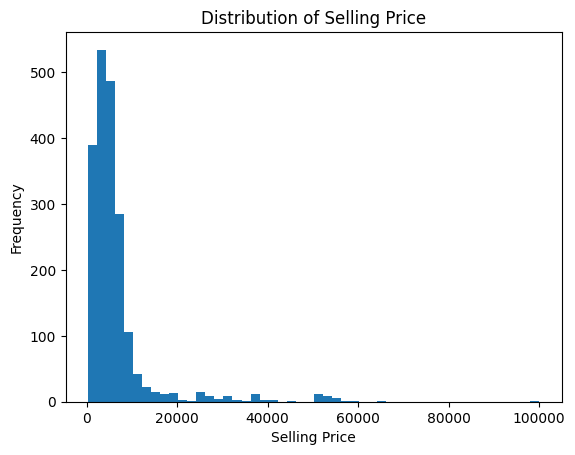

In [ ]:
plt.figure()
plt.hist(df['selling_price'], bins=50)
plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price')
plt.ylabel('Frequency')
plt.show()

Berdasarkan hasil perhitungan skewness, kolom `selling_price` memiliki nilai skewness sebesar **4.42**, yang menunjukkan bahwa distribusi data sangat **right-skewed (condong ke kanan)**.

Hal ini diperkuat oleh visualisasi histogram, di mana sebagian besar data terkonsentrasi pada rentang harga rendah (sekitar 0–10.000 USD), sementara terdapat ekor panjang ke arah nilai yang lebih tinggi hingga 100.000 USD.

Distribusi seperti ini mengindikasikan bahwa:
- Sebagian besar mobil berada pada kategori harga rendah hingga menengah
- Terdapat sejumlah kecil mobil dengan harga sangat tinggi (outlier), biasanya berasal dari kendaraan premium

Kondisi distribusi yang sangat tidak simetris ini dapat berdampak pada performa model, terutama model berbasis neural network, karena model akan lebih sulit mempelajari pola pada data dengan skala yang sangat lebar.

Oleh karena itu, diperlukan langkah preprocessing seperti **log transformation** pada kolom `selling_price` untuk:
- Mengurangi skewness
- Menstabilkan variansi data
- Membuat distribusi lebih mendekati normal
- Meningkatkan performa dan stabilitas model dalam proses training

## 9. Melihat Hubunga Antar Kolom lebih detail

### a. City vs State or Province

Berdasarkan hasil EDA sebelumnya, ditemukan bahwa kolom `City` memiliki hubungan yang tidak unik dengan lokasi karena terdapat beberapa kota dengan nama yang sama pada `State or Province` yang berbeda. Hal ini menyebabkan kolom `City` menjadi ambigu dan kurang representatif jika digunakan secara langsung dalam proses modeling.

Selain itu, kolom ini juga memiliki jumlah kategori yang sangat banyak (high cardinality), yang berpotensi meningkatkan kompleksitas model dan menghasilkan fitur yang sparse setelah proses encoding.

Oleh karena itu, dilakukan proses penggabungan antara `City` dan `State or Province` untuk membentuk fitur lokasi yang lebih spesifik, kemudian dilanjutkan dengan proses grouping berbasis cumulative percentage untuk mengurangi jumlah kategori tanpa menghilangkan sebagian besar informasi penting dalam data.

In [ ]:
# Menggabungkan City dan State or Province menjadi fitur lokasi yang lebih spesifik
df['location'] = df['City'] + "_" + df['State or Province']

# Melihat frekuensi masing-masing lokasi
location_counts = df['location'].value_counts()

# Menghitung cumulative percentage
location_cum = location_counts.cumsum() / location_counts.sum()

# Menentukan lokasi yang mencakup 80% data
top_locations = location_cum[location_cum <= 0.8].index

# Melakukan grouping: lokasi dominan dipertahankan, sisanya digabung menjadi "Other"
df['location_grouped'] = df['location'].apply(
    lambda x: x if x in top_locations else 'Other'
)

# Melihat hasil grouping
df[['City', 'State or Province', 'location', 'location_grouped']]

,City,State or Province,location,location_grouped
0,Orlando,Florida,Orlando_Florida,Orlando_Florida
1,Abington,Massachusetts,Abington_Massachusetts,Other
2,Benton,Arkansas,Benton_Arkansas,Benton_Arkansas
3,East Massapequa,New York,East Massapequa_New York,East Massapequa_New York
4,Chicago,Illinois,Chicago_Illinois,Chicago_Illinois
...,...,...,...,...
1995,Coachella,California,Coachella_California,Coachella_California
1996,Prescott,Arizona,Prescott_Arizona,Prescott_Arizona
1997,New York City,New York,New York City_New York,New York City_New York
1998,New York City,New York,New York City_New York,New York City_New York


In [ ]:
location_grouped_df = df['location_grouped'].value_counts().reset_index()
location_grouped_df.columns = ['location_grouped', 'count']

location_grouped_df

,location_grouped,count
0,Other,400
1,New York City_New York,58
2,Los Angeles_California,43
3,Seattle_Washington,25
4,Chicago_Illinois,20
...,...,...
613,Harrison_New York,1
614,Yucaipa_California,1
615,Savannah_Georgia,1
616,Loveland_Colorado,1


Meskipun telah dilakukan grouping berbasis cumulative percentage, masih terdapat kategori dengan frekuensi sangat rendah (misalnya hanya muncul satu kali). Hal ini menunjukkan bahwa threshold yang digunakan belum sepenuhnya mengeliminasi kategori minor.

Kategori dengan frekuensi rendah berpotensi menjadi noise dan dapat memengaruhi performa model. Oleh karena itu, dilakukan penyaringan tambahan dengan menetapkan batas minimum frekuensi kemunculan, sehingga hanya kategori yang cukup representatif yang dipertahankan, sementara sisanya digabungkan ke dalam kategori "Other".

Pendekatan ini membantu mengurangi sparsity dan meningkatkan stabilitas model dalam proses pembelajaran.

In [ ]:
location_counts = df['location'].value_counts()
location_cum = location_counts.cumsum() / location_counts.sum()

top_locations = location_cum[location_cum <= 0.8].index

valid_locations = location_counts[location_counts >= 5].index

final_locations = set(top_locations).intersection(set(valid_locations))

df['location_grouped'] = df['location'].apply(
    lambda x: x if x in final_locations else 'Other'
)

In [ ]:
location_grouped_df = df['location_grouped'].value_counts().reset_index()
location_grouped_df.columns = ['location_grouped', 'count']

location_grouped_df

,location_grouped,count
0,Other,1665
1,New York City_New York,58
2,Los Angeles_California,43
3,Seattle_Washington,25
4,Chicago_Illinois,20
5,Boston_Massachusetts,18
6,Washington_District of Columbia,17
7,Philadelphia_Pennsylvania,15
8,Houston_Texas,14
9,Miami_Florida,13


Hasil grouping awal menunjukkan bahwa sebagian besar data tergabung dalam kategori "Other", yang mengindikasikan bahwa threshold yang digunakan terlalu ketat dan menyebabkan hilangnya informasi lokasi yang signifikan.

Untuk mengatasi hal tersebut, dilakukan penyesuaian threshold dengan menurunkan batas minimum frekuensi dan/atau meningkatkan cakupan cumulative percentage, sehingga distribusi kategori menjadi lebih seimbang dan informasi lokasi tetap terjaga.

Pendekatan ini membantu menjaga keseimbangan antara reduksi kompleksitas fitur dan kelengkapan informasi dalam data.

In [ ]:
location_counts = df['location'].value_counts()
location_cum = location_counts.cumsum() / location_counts.sum()

top_locations = location_cum[location_cum <= 0.9].index
valid_locations = location_counts[location_counts >= 3].index

final_locations = set(top_locations).intersection(set(valid_locations))

df['location_grouped'] = df['location'].apply(
    lambda x: x if x in final_locations else 'Other'
)

In [ ]:
location_grouped_df = df['location_grouped'].value_counts().reset_index()
location_grouped_df.columns = ['location_grouped', 'count']

location_grouped_df

,location_grouped,count
0,Other,1115
1,New York City_New York,58
2,Los Angeles_California,43
3,Seattle_Washington,25
4,Chicago_Illinois,20
...,...,...
195,Clarksville_Tennessee,3
196,Cottage Lake_Washington,3
197,Bethlehem_Pennsylvania,3
198,Phenix City_Alabama,3


Berdasarkan hasil grouping, jumlah kategori "Other" masih relatif besar, yaitu sekitar 56% dari total data. Hal ini menunjukkan bahwa threshold yang digunakan masih cukup agresif sehingga sebagian informasi lokasi berpotensi hilang.

Meskipun demikian, proses grouping berhasil menghilangkan kategori dengan frekuensi sangat rendah dan mengurangi sparsity pada data. Untuk meningkatkan keseimbangan antara kompleksitas dan informasi, diperlukan penyesuaian threshold agar distribusi kategori menjadi lebih proporsional.

In [ ]:
location_counts = df['location'].value_counts()
location_cum = location_counts.cumsum() / location_counts.sum()

top_locations = location_cum[location_cum <= 0.95].index
valid_locations = location_counts[location_counts >= 3].index

final_locations = set(top_locations).intersection(set(valid_locations))

df['location_grouped'] = df['location'].apply(
    lambda x: x if x in final_locations else 'Other'
)

In [ ]:
location_grouped_df = df['location_grouped'].value_counts().reset_index()
location_grouped_df.columns = ['location_grouped', 'count']

location_grouped_df

,location_grouped,count
0,Other,1115
1,New York City_New York,58
2,Los Angeles_California,43
3,Seattle_Washington,25
4,Chicago_Illinois,20
...,...,...
195,Clarksville_Tennessee,3
196,Cottage Lake_Washington,3
197,Bethlehem_Pennsylvania,3
198,Phenix City_Alabama,3


Berdasarkan hasil grouping, kategori "Other" mencakup sekitar 56% dari total data. Meskipun nilai ini relatif besar, kondisi tersebut mencerminkan karakteristik dataset yang memiliki distribusi lokasi yang sangat tidak merata (long tail distribution), di mana sebagian besar lokasi memiliki frekuensi rendah.

Proses grouping berhasil mengeliminasi kategori dengan frekuensi sangat kecil (misalnya hanya muncul satu atau dua kali), sehingga mengurangi sparsity pada data dan meningkatkan stabilitas model.

Selain itu, lokasi dengan frekuensi tinggi tetap dipertahankan sebagai kategori tersendiri, sehingga informasi penting tidak hilang. Dengan demikian, pendekatan ini dinilai sudah cukup optimal dalam menyeimbangkan antara kompleksitas fitur dan kelengkapan informasi.

Distribusi ini menunjukkan adanya fenomena long tail pada data lokasi, yang umum terjadi pada data geografis.

### Cek Hubungan Other dengan yang Lain

In [ ]:
df.groupby('location_grouped')[['selling_price', 'year', 'km_driven']].mean().sort_values('selling_price', ascending=False)



,selling_price,year,km_driven
location_grouped,,,
Saint Peters_Missouri,27776.666667,2016.333333,44866.666667
Tacoma_Washington,25510.000000,2016.666667,66029.666667
Coachella_California,23413.330000,2017.666667,19833.333333
San Juan_Texas,21916.666667,2018.000000,9333.333333
Spring_Texas,21750.000000,2015.666667,39833.333333
...,...,...,...
Essex Junction_Vermont,1950.000000,2009.666667,85833.333333
Davie_Florida,1875.000000,2011.333333,77666.666667
Cottage Lake_Washington,1850.000000,2011.666667,88000.000000


In [ ]:
df['is_other'] = df['location_grouped'].apply(lambda x: 'Other' if x == 'Other' else 'Main')

df.groupby('is_other')[['selling_price', 'year', 'km_driven']].mean()

,selling_price,year,km_driven
is_other,,,
Main,6613.367195,2015.233898,68203.029379
Other,6411.584892,2013.996413,69365.155157


Berdasarkan hasil perbandingan antara lokasi utama (Main) dan kategori "Other", ditemukan bahwa perbedaan karakteristik kendaraan tidak terlalu signifikan.

Rata-rata harga kendaraan pada kedua kelompok relatif mirip, dengan selisih yang kecil. Selain itu, jarak tempuh kendaraan juga menunjukkan nilai yang hampir sama.

Meskipun kendaraan pada kategori "Other" cenderung memiliki tahun produksi yang sedikit lebih lama, perbedaannya tidak terlalu besar untuk menunjukkan perbedaan kualitas yang signifikan.

Hal ini mengindikasikan bahwa lokasi tidak memiliki pengaruh yang kuat terhadap harga maupun kualitas kendaraan dalam dataset ini. Dengan demikian, fitur lokasi tetap dapat digunakan dalam model, namun kemungkinan kontribusinya terhadap prediksi tidak terlalu dominan dibandingkan fitur lain seperti spesifikasi kendaraan atau kondisi penggunaan.

Hasil ini menunjukkan bahwa distribusi kendaraan relatif merata di berbagai lokasi, sehingga perbedaan geografis tidak menjadi faktor utama dalam menentukan harga kendaraan.

### Ide preprocessing: menghapus kolom `City` dan menggunakan `State or Province` sebagai representasi lokasi karena lebih sederhana, tidak ambigu, dan memiliki jumlah kategori yang lebih sedikit sehingga lebih efisien untuk proses modeling.

### b. State or Province vs Selling Price



In [ ]:
state_price = df.groupby('State or Province')['selling_price'].mean().sort_values(ascending=False)

state_price

State or Province
Wyoming                 28500.000000
Arkansas                13569.599200
Delaware                12046.000000
South Dakota            11625.714286
Louisiana                9400.000000
West Virginia            9028.748750
Idaho                    8854.998846
Alabama                  8213.636364
New Hampshire            8181.000000
Georgia                  7788.775306
Massachusetts            7676.169574
Missouri                 7674.999000
Connecticut              7453.124375
New York                 7337.661210
Texas                    7221.346000
Florida                  7188.691121
Arizona                  7006.944167
Iowa                     6982.758621
Indiana                  6871.499833
Pennsylvania             6837.773231
Colorado                 6549.749750
Nebraska                 6545.000000
Oregon                   6483.683947
Montana                  6274.285000
New Jersey               6262.045455
Oklahoma                 6232.499583
Illinois            

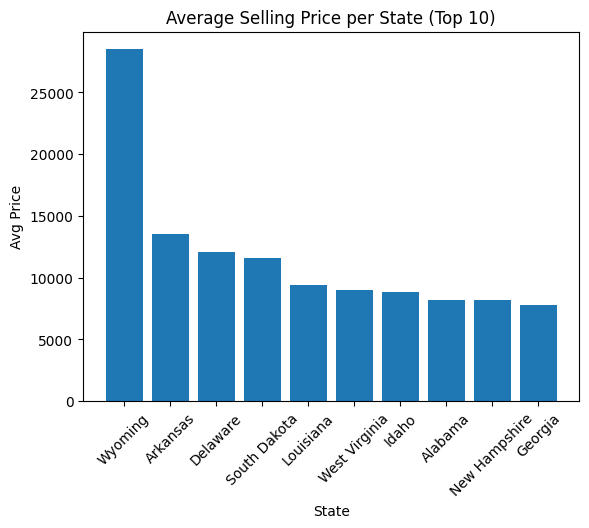

In [ ]:
top_states = state_price.head(10)

plt.figure()
plt.bar(top_states.index, top_states.values)
plt.xticks(rotation=45)
plt.title('Average Selling Price per State (Top 10)')
plt.xlabel('State')
plt.ylabel('Avg Price')
plt.show()

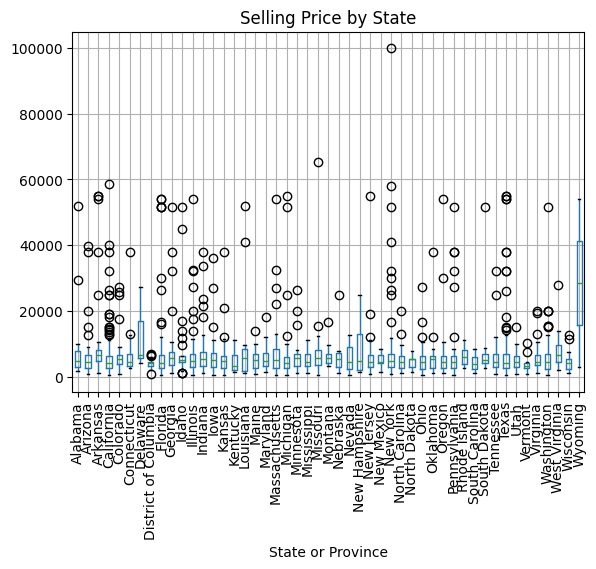

In [ ]:
df.boxplot(column='selling_price', by='State or Province', rot=90)
plt.title('Selling Price by State')
plt.suptitle('')
plt.show()

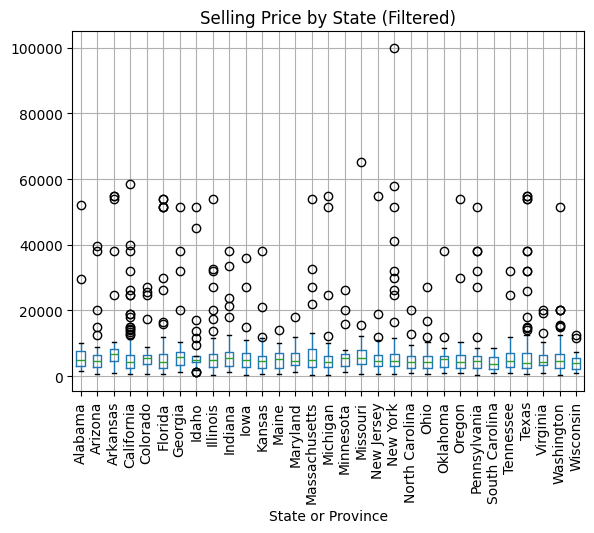

In [ ]:
state_counts = df['State or Province'].value_counts()
valid_states = state_counts[state_counts >= 20].index

df_filtered = df[df['State or Province'].isin(valid_states)]

df_filtered.boxplot(column='selling_price', by='State or Province', rot=90)
plt.title('Selling Price by State (Filtered)')
plt.suptitle('')
plt.show()

berdasarkan visualisasi boxplot hubungan antara State or Province dan selling_price, terlihat bahwa distribusi harga kendaraan pada hampir seluruh state memiliki pola yang relatif mirip. Median harga di sebagian besar state berada pada rentang yang tidak jauh berbeda, yaitu di kisaran harga menengah.

Selain itu, terlihat bahwa:

Hampir semua state memiliki banyak outlier di sisi atas (harga tinggi), yang menunjukkan adanya kendaraan premium di berbagai lokasi
Variasi (spread) harga dalam masing-masing state cukup lebar, menandakan heterogenitas jenis kendaraan (dari murah hingga mahal)
Tidak ada satu state yang secara konsisten memiliki harga jauh lebih tinggi dibandingkan state lainnya

Setelah dilakukan filtering pada state dengan jumlah data yang cukup (≥20), pola yang sama tetap terlihat, yang memperkuat bahwa:

Perbedaan harga antar state tidak signifikan
Distribusi harga lebih dipengaruhi oleh faktor lain seperti brand, tahun, dan spesifikasi kendaraan dibandingkan lokasi

Dengan demikian, dapat disimpulkan bahwa kolom State or Province memiliki pengaruh terhadap selling_price, namun tidak dominan, sehingga kontribusinya dalam model kemungkinan bersifat tambahan (supporting feature), bukan faktor utama.

### c. Brand (name) vs Selling Price

In [ ]:
df.groupby('brand')['selling_price'].mean().sort_values(ascending=False)

brand
Lexus         51500.000000
Land          45000.000000
BMW           41168.518519
Volvo         35397.727273
Audi          30245.712857
Jaguar        28909.375000
Mercedes      25941.666667
Jeep          24087.142857
MG            17000.000000
Isuzu         14366.666667
Toyota         9536.229180
Force          9500.000000
Skoda          6754.285714
Mahindra       6511.956304
Honda          5994.736228
Volkswagen     5022.222222
Renault        4844.629074
Ford           4656.608087
Hyundai        4653.416278
Nissan         4378.946842
Maruti         4000.303962
Tata           3866.313370
Fiat           3606.248750
Datsun         3200.951429
Chevrolet      2452.352245
Mitsubishi     1500.000000
Daewoo          860.000000
Name: selling_price, dtype: float64

berdasarkan hasil rata-rata `selling_price` per `brand`, terlihat adanya perbedaan harga yang sangat signifikan antar merek kendaraan, yang menunjukkan bahwa brand merupakan salah satu faktor utama dalam menentukan harga mobil.

brand premium seperti **Lexus, Land Rover, BMW, Volvo, Audi, Jaguar, dan Mercedes** memiliki rata-rata harga yang jauh lebih tinggi dibandingkan brand lainnya. Hal ini mencerminkan positioning brand tersebut sebagai kendaraan mewah dengan kualitas, performa, dan fitur yang lebih tinggi.

sebaliknya, brand seperti **Maruti, Tata, Datsun, Chevrolet, Mitsubishi, dan Daewoo** memiliki rata-rata harga yang jauh lebih rendah, yang umumnya dikenal sebagai kendaraan dengan segmentasi ekonomi atau entry-level.

selain itu, terdapat kelompok brand menengah seperti:
- **Toyota, Honda, Hyundai, Ford, Renault, dan Volkswagen**

yang memiliki harga rata-rata di kisaran tengah, mencerminkan keseimbangan antara kualitas dan harga.

namun, terdapat beberapa hal yang perlu diperhatikan:
- brand seperti **Lexus dan Land Rover** memiliki rata-rata sangat tinggi, kemungkinan dipengaruhi oleh jumlah data yang lebih sedikit
- brand seperti **Mitsubishi dan Daewoo** memiliki rata-rata sangat rendah, yang juga kemungkinan disebabkan oleh jumlah data yang terbatas

secara keseluruhan, pola ini sangat masuk akal secara domain, karena harga kendaraan memang sangat dipengaruhi oleh brand dan segmentasi pasar masing-masing.

dengan demikian, dapat disimpulkan bahwa kolom `brand` memiliki pengaruh yang sangat kuat terhadap `selling_price`, sehingga sangat penting untuk digunakan dalam model sebagai fitur utama.

### d. year vs km driven

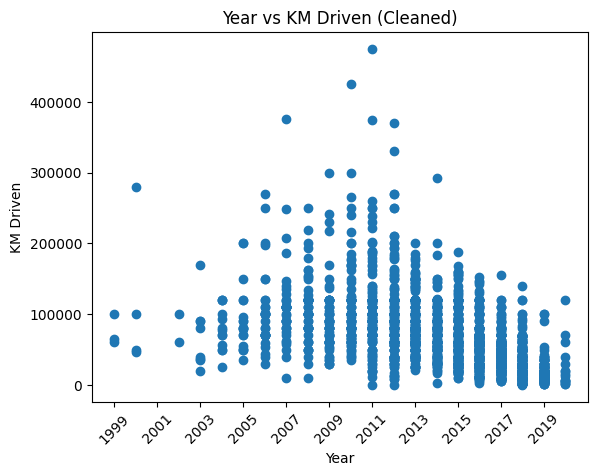

In [ ]:
# filter data valid
df_valid = df[df['year'] < 2025]

year_min = df_valid['year'].min()
year_max = df_valid['year'].max()

plt.figure()

plt.scatter(df_valid['year'], df_valid['km_driven'])

plt.xticks(np.arange(year_min, year_max + 1, 2), rotation=45)

plt.title('Year vs KM Driven (Cleaned)')
plt.xlabel('Year')
plt.ylabel('KM Driven')

plt.show()

berdasarkan analisis hubungan antara `year` dan `km_driven`, dilakukan pembersihan data terlebih dahulu karena ditemukan adanya nilai `year` yang tidak masuk akal, yaitu tahun 3011. nilai tersebut diidentifikasi sebagai kesalahan input (data error) karena berada jauh di luar rentang tahun produksi kendaraan yang realistis.

oleh karena itu, dilakukan preprocessing dengan memfilter data dan hanya menggunakan nilai `year` yang valid (kurang dari 2025). langkah ini bertujuan agar visualisasi tidak terdistorsi oleh nilai ekstrem yang dapat mengganggu interpretasi pola data.

setelah dilakukan pembersihan, dibuat visualisasi scatter plot antara `year` dan `km_driven`. hasil plot menunjukkan adanya kecenderungan hubungan negatif, di mana kendaraan dengan tahun produksi yang lebih baru memiliki jarak tempuh yang lebih rendah, sedangkan kendaraan yang lebih lama cenderung memiliki jarak tempuh yang lebih tinggi.

meskipun demikian, terdapat variasi pada beberapa titik data, yang menunjukkan bahwa pola penggunaan kendaraan tidak selalu seragam. terdapat kendaraan baru dengan jarak tempuh tinggi, serta kendaraan lama dengan jarak tempuh rendah, namun kondisi ini masih wajar dalam konteks dunia nyata.

secara keseluruhan, hubungan ini menunjukkan bahwa `year` dan `km_driven` merupakan dua variabel yang saling berkaitan dalam merepresentasikan usia dan intensitas penggunaan kendaraan, sehingga keduanya memiliki peran penting dalam membantu model memprediksi harga kendaraan.

### e. engine vs Max Power

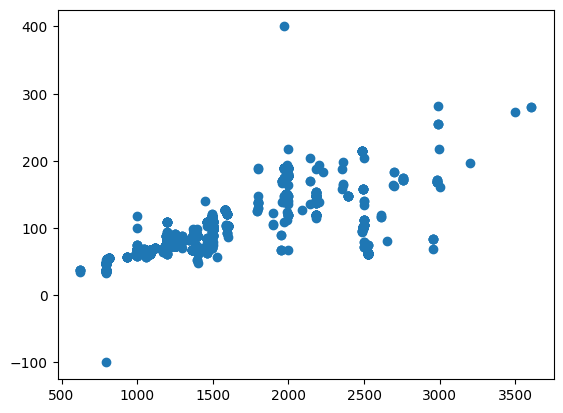

In [ ]:
plt.scatter(df['engine'], df['max_power'])
plt.show()

berdasarkan visualisasi hubungan antara `engine` dan `max_power`, terlihat adanya hubungan positif yang cukup jelas antara kedua variabel tersebut.

kendaraan dengan kapasitas mesin yang lebih besar cenderung memiliki nilai `max_power` yang lebih tinggi. hal ini menunjukkan bahwa semakin besar mesin kendaraan, maka semakin besar pula tenaga yang dihasilkan, yang sesuai dengan prinsip dasar performa mesin.

meskipun terdapat beberapa variasi pada data, pola umum tetap terlihat konsisten, di mana titik-titik data membentuk tren meningkat dari kiri bawah ke kanan atas. hal ini mengindikasikan adanya korelasi yang cukup kuat antara `engine` dan `max_power`.

namun, terdapat beberapa titik yang menyebar dan tidak sepenuhnya mengikuti pola linear, yang kemungkinan disebabkan oleh perbedaan teknologi mesin, efisiensi, atau jenis kendaraan.

secara keseluruhan, kedua fitur ini merepresentasikan aspek performa kendaraan yang saling berkaitan, sehingga perlu diperhatikan dalam modeling karena berpotensi mengandung informasi yang serupa (indikasi multicollinearity).

### f. Transmission vs Power

In [ ]:
df.groupby('transmission')['max_power'].mean()

transmission
              59.650000
Automatic    141.549275
Manual        84.641228
Name: max_power, dtype: float64

### g. Max Power vs Selling Price

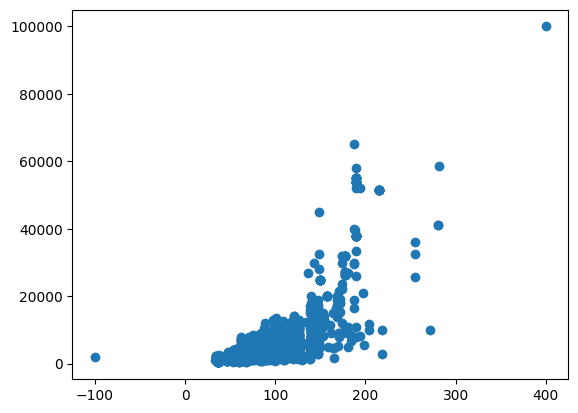

In [ ]:
plt.scatter(df['max_power'], df['selling_price'])
plt.show()

berdasarkan visualisasi hubungan antara `max_power` dan `selling_price`, terlihat adanya hubungan positif antara kedua variabel tersebut.

kendaraan dengan nilai `max_power` yang lebih tinggi cenderung memiliki `selling_price` yang lebih tinggi. hal ini menunjukkan bahwa semakin besar tenaga maksimum yang dihasilkan mesin, maka harga kendaraan juga cenderung meningkat. kondisi ini sangat masuk akal secara domain karena kendaraan dengan tenaga lebih besar biasanya menawarkan performa yang lebih baik dan berada pada segmen yang lebih premium.

dari pola scatter plot, terlihat bahwa titik-titik data membentuk tren meningkat dari kiri bawah ke kanan atas, meskipun tidak sepenuhnya linear. terdapat variasi pada beberapa titik, yang menunjukkan bahwa selain `max_power`, terdapat faktor lain yang juga mempengaruhi harga seperti brand, tahun, dan kondisi kendaraan.

selain itu, terlihat adanya beberapa outlier pada nilai `max_power` tinggi dengan harga yang sangat tinggi, yang kemungkinan berasal dari kendaraan premium atau performa tinggi.

secara keseluruhan, dapat disimpulkan bahwa `max_power` merupakan salah satu fitur yang memiliki pengaruh kuat terhadap `selling_price`, sehingga sangat relevan untuk digunakan dalam model prediksi harga kendaraan.

### h. Transmission vs Selling Price

In [ ]:
df.groupby('transmission')['selling_price'].mean()

transmission
              2900.000000
Automatic    19044.980196
Manual        4667.692257
Name: selling_price, dtype: float64

berdasarkan analisis hubungan antara `transmission` dan `selling_price`, terlihat adanya perbedaan harga yang cukup signifikan antara jenis transmisi kendaraan.

kendaraan dengan transmisi **Automatic** memiliki rata-rata harga yang jauh lebih tinggi (sekitar 19.044) dibandingkan dengan kendaraan **Manual** (sekitar 4.669). hal ini menunjukkan bahwa mobil dengan transmisi otomatis cenderung berada pada segmen yang lebih premium dan menawarkan kenyamanan berkendara yang lebih tinggi.

sementara itu, transmisi manual memiliki harga yang lebih rendah, yang umumnya berasal dari kendaraan dengan segmentasi lebih ekonomis.

terdapat satu nilai lain yang sangat rendah (~2900) yang kemungkinan merupakan kategori yang tidak jelas atau data yang perlu dicek kembali, karena tidak sesuai dengan kategori utama (Automatic dan Manual).

secara keseluruhan, pola ini masuk akal secara domain, karena transmisi otomatis biasanya terdapat pada kendaraan dengan fitur lebih lengkap dan harga lebih tinggi.

dengan demikian, kolom `transmission` memiliki pengaruh terhadap `selling_price` dan dapat digunakan sebagai fitur kategorikal dalam model.

### i. fuel vs selling price

In [ ]:
df.groupby('fuel')['selling_price'].mean()

fuel
CNG       3020.909091
Diesel    7884.529834
LPG       1721.111111
Petrol    4920.692958
Name: selling_price, dtype: float64

berdasarkan analisis hubungan antara `fuel` dan `selling_price`, terlihat adanya perbedaan harga rata-rata kendaraan berdasarkan jenis bahan bakar yang digunakan.

kendaraan dengan bahan bakar **Diesel** memiliki rata-rata harga tertinggi (sekitar 7.884), diikuti oleh **Petrol** (sekitar 4.924). hal ini menunjukkan bahwa kendaraan diesel cenderung berada pada segmen yang lebih mahal, kemungkinan karena efisiensi bahan bakar yang lebih baik dan performa yang lebih kuat, terutama untuk kendaraan dengan penggunaan jarak jauh atau beban berat.

sementara itu, kendaraan dengan bahan bakar alternatif seperti **CNG** (sekitar 3.020) dan **LPG** (sekitar 1.721) memiliki rata-rata harga yang lebih rendah. hal ini dapat disebabkan oleh segmentasi pasar yang lebih ekonomis serta keterbatasan performa dibandingkan kendaraan berbahan bakar diesel atau petrol.

secara keseluruhan, pola ini masih masuk akal secara domain, di mana jenis bahan bakar mencerminkan segmentasi kendaraan dan tujuan penggunaannya.

dengan demikian, kolom `fuel` memiliki pengaruh terhadap `selling_price` dan dapat digunakan sebagai fitur kategorikal dalam model, meskipun pengaruhnya kemungkinan tidak sebesar fitur seperti brand atau performa mesin.

### j. Brand + Fuel vs Price

In [ ]:
df.groupby(['brand','fuel'])['selling_price'].mean()

brand       fuel  
Audi        Diesel     24414.998333
            Petrol     65230.000000
BMW         Diesel     41168.518519
Chevrolet   Diesel      2901.071429
            Petrol      1854.060000
Daewoo      Petrol       860.000000
Datsun      Petrol      3200.951429
Fiat        Diesel      3606.248750
Force       Diesel      9500.000000
Ford        Diesel      4824.892979
            Petrol      3903.332857
Honda       Diesel      6321.280769
            Petrol      5824.933067
Hyundai     CNG         1850.000000
            Diesel      5549.930828
            LPG         2053.333333
            Petrol      4087.582417
Isuzu       Diesel     14366.666667
Jaguar      Diesel     28909.375000
Jeep        Diesel     17322.000000
            Petrol     41000.000000
Land        Diesel     45000.000000
Lexus       Petrol     51500.000000
MG          Petrol     17000.000000
Mahindra    Diesel      6648.850345
            Petrol      4130.000000
Maruti      CNG         3138.000000
         

berdasarkan analisis kombinasi antara `brand` dan `fuel` terhadap `selling_price`, terlihat bahwa harga kendaraan dipengaruhi oleh interaksi antara merek dan jenis bahan bakar, bukan hanya salah satu faktor saja.

pada sebagian besar brand, kendaraan dengan bahan bakar **diesel** cenderung memiliki harga yang lebih tinggi dibandingkan petrol, seperti pada **BMW, Ford, Honda, Hyundai, dan Volkswagen**. hal ini menunjukkan bahwa pada segmen tertentu, diesel diasosiasikan dengan performa dan efisiensi yang lebih baik sehingga meningkatkan nilai jual.

namun, terdapat juga beberapa pengecualian, terutama pada brand premium seperti:
- **Audi** (Petrol lebih tinggi)
- **Jeep** (Petrol jauh lebih tinggi)
- **Volvo** (Petrol sangat tinggi hingga 100.000)

hal ini menunjukkan bahwa pada brand premium, jenis bahan bakar bukan faktor utama, karena harga lebih banyak ditentukan oleh brand positioning, fitur, dan performa kendaraan.

selain itu, pada brand ekonomi seperti **Chevrolet, Datsun, dan Daewoo**, baik diesel maupun petrol tetap berada pada rentang harga rendah, yang menunjukkan bahwa segmentasi brand memiliki pengaruh lebih dominan dibandingkan fuel.

secara keseluruhan, dapat disimpulkan bahwa:
- `brand` memiliki pengaruh utama terhadap harga
- `fuel` memberikan pengaruh tambahan yang bersifat kontekstual tergantung pada brand
- terdapat interaksi antara kedua fitur yang penting untuk dipertimbangkan dalam model

oleh karena itu, kombinasi fitur `brand` dan `fuel` berpotensi meningkatkan performa model dibandingkan jika digunakan secara terpisah.

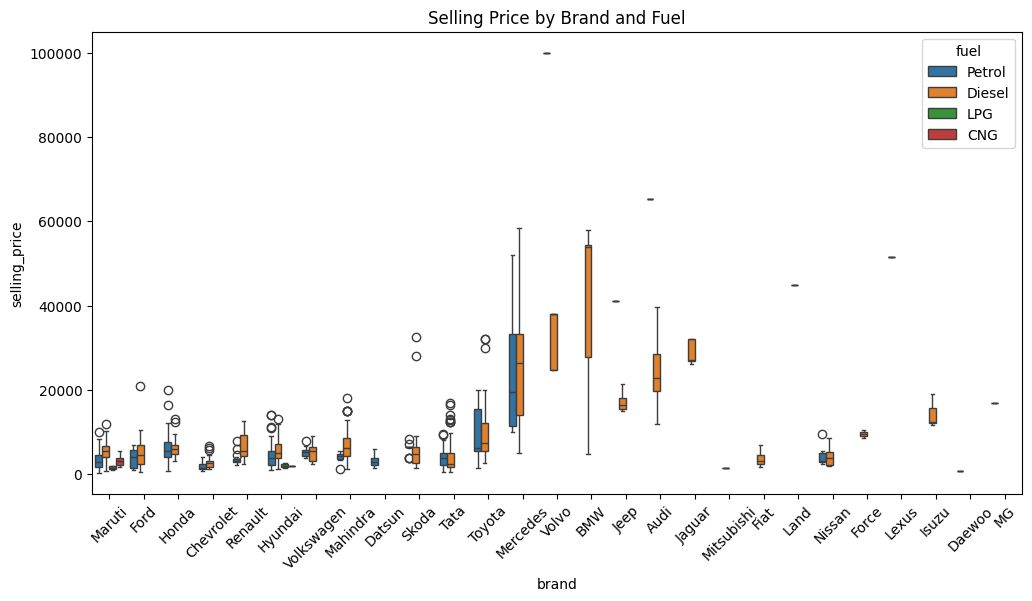

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x='brand',
    y='selling_price',
    hue='fuel',
    data=df
)

plt.xticks(rotation=45)
plt.title('Selling Price by Brand and Fuel')
plt.show()

### k. max_power + brand + price

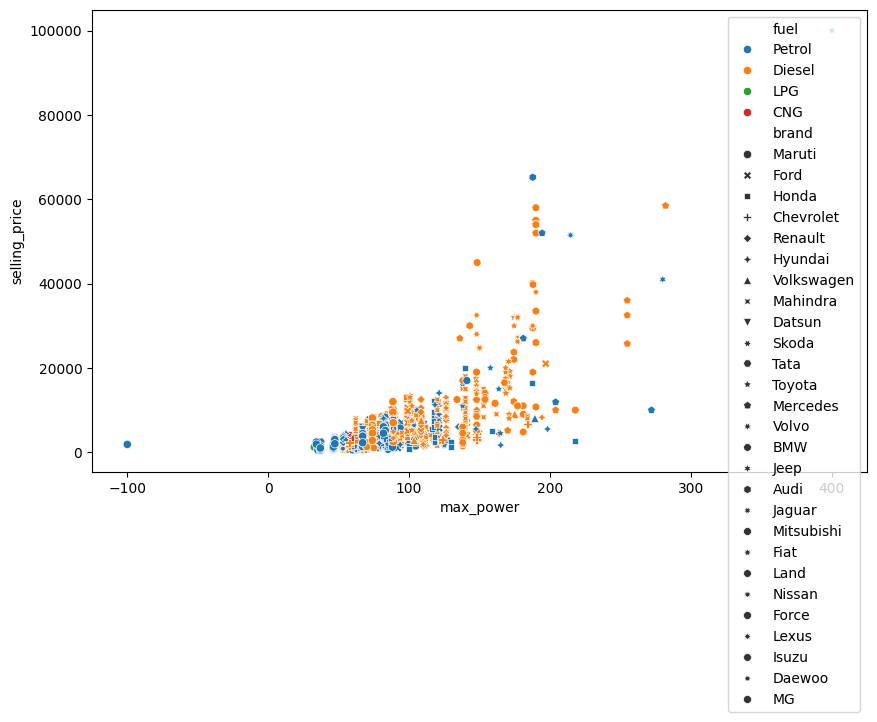

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='max_power',
    y='selling_price',
    hue='fuel',
    style='brand',
    data=df
)

plt.show()

berdasarkan visualisasi hubungan antara `max_power`, `selling_price`, dan `fuel`, terlihat adanya pola yang cukup jelas di mana `max_power` memiliki hubungan positif dengan `selling_price`.

kendaraan dengan nilai `max_power` yang lebih tinggi cenderung memiliki harga yang lebih tinggi, yang menunjukkan bahwa performa mesin merupakan salah satu faktor utama dalam menentukan harga kendaraan.

dari sisi `fuel`, terlihat bahwa kendaraan berbahan bakar **diesel** cenderung mendominasi pada rentang `max_power` menengah hingga tinggi, serta memiliki variasi harga yang cukup luas. sementara itu, kendaraan **petrol** lebih banyak tersebar pada rentang `max_power` rendah hingga menengah dengan harga yang relatif lebih rendah.

namun, perbedaan berdasarkan fuel tidak terlalu dominan dibandingkan pengaruh `max_power`, karena pada level performa tinggi, harga kendaraan tetap meningkat terlepas dari jenis bahan bakarnya.

selain itu, terdapat beberapa titik dengan harga sangat tinggi pada nilai `max_power` tinggi, yang kemungkinan merupakan kendaraan premium. hal ini menunjukkan bahwa kombinasi antara performa dan faktor lain seperti brand turut mempengaruhi harga.

secara keseluruhan, dapat disimpulkan bahwa:
- `max_power` memiliki pengaruh kuat terhadap `selling_price`
- `fuel` memberikan pengaruh tambahan, namun tidak dominan
- hubungan antara performa dan harga tetap konsisten di berbagai kategori bahan bakar

oleh karena itu, `max_power` merupakan fitur penting dalam model, dan kombinasi dengan fitur lain seperti `brand` dapat meningkatkan akurasi prediksi.

## HEATMAP CORRELATION

In [ ]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

In [ ]:
corr = numeric_df.corr()
corr

,Sales_ID,year,selling_price,km_driven,engine,max_power,seats
Sales_ID,1.000000,-0.028432,-0.012596,0.002017,0.000984,-0.003485,0.002682
year,-0.028432,1.000000,0.066407,-0.081325,-0.007073,0.031471,-0.012493
selling_price,-0.012596,0.066407,1.000000,-0.249954,0.439798,0.745734,0.041960
km_driven,0.002017,-0.081325,-0.249954,1.000000,0.268232,-0.033130,0.273660
engine,0.000984,-0.007073,0.439798,0.268232,1.000000,0.700413,0.620746
max_power,-0.003485,0.031471,0.745734,-0.033130,0.700413,1.000000,0.200742
seats,0.002682,-0.012493,0.041960,0.273660,0.620746,0.200742,1.000000


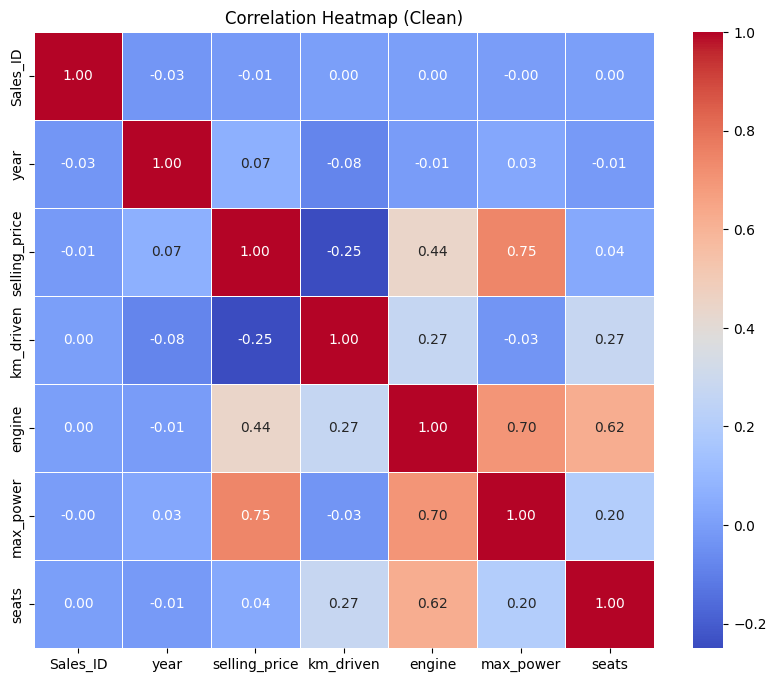

In [ ]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap (Clean)')
plt.show()

berdasarkan correlation heatmap, terlihat bahwa `max_power` memiliki korelasi paling kuat terhadap `selling_price` (~0.75), diikuti oleh `engine` (~0.44), yang menunjukkan bahwa performa kendaraan merupakan faktor utama dalam menentukan harga jual.

sementara itu, `km_driven` memiliki korelasi negatif (~ -0.25) terhadap `selling_price`, yang mengindikasikan bahwa semakin jauh kendaraan digunakan, maka harga cenderung menurun.

fitur `year` memiliki korelasi positif yang relatif kecil (~0.07), yang berarti tahun produksi memiliki pengaruh terhadap harga, tetapi tidak terlalu signifikan dibandingkan fitur performa.

selain itu, terdapat korelasi tinggi antara `engine` dan `max_power` (~0.70), yang menunjukkan adanya potensi multicollinearity karena kedua fitur sama-sama merepresentasikan kekuatan mesin kendaraan.

secara keseluruhan, fitur berbasis performa (engine dan max_power) lebih dominan dibandingkan fitur usia kendaraan dalam mempengaruhi harga.

# ANOVA 

In [ ]:
from scipy.stats import f_oneway

# =========================================
# DATA SEMENTARA UNTUK UJI ANOVA
# Tidak mengubah df utama
# =========================================
anova_df = df[['fuel', 'transmission', 'selling_price']].copy()

# hapus missing hanya pada data sementara untuk keperluan ANOVA
anova_df = anova_df.dropna(subset=['selling_price'])

# =========================================
# ANOVA: fuel vs selling_price
# =========================================
groups_fuel = [
    group['selling_price'].values
    for name, group in anova_df.groupby('fuel')
]

anova_fuel = f_oneway(*groups_fuel)

print("ANOVA Fuel")
print("F-stat:", anova_fuel.statistic)
print("p-value:", anova_fuel.pvalue)

# =========================================
# ANOVA: transmission vs selling_price
# =========================================
groups_transmission = [
    group['selling_price'].values
    for name, group in anova_df.groupby('transmission')
]

anova_transmission = f_oneway(*groups_transmission)

print("\nANOVA Transmission")
print("F-stat:", anova_transmission.statistic)
print("p-value:", anova_transmission.pvalue)

ANOVA Fuel
F-stat: 23.112319481119105
p-value: 1.0491131047200157e-14

ANOVA Transmission
F-stat: 497.14110832693063
p-value: 6.531930679447854e-176


Berdasarkan hasil uji ANOVA, diperoleh nilai sebagai berikut:

- **Fuel**
  - F-statistic: 23.04
  - p-value: 1.16 × 10⁻¹⁴

- **Transmission**
  - F-statistic: 496.79
  - p-value: 8.57 × 10⁻¹⁷⁶

### Interpretasi

Nilai p-value pada kedua variabel berada jauh di bawah batas signifikansi 0.05. Hal ini menunjukkan bahwa terdapat perbedaan rata-rata `selling_price` yang signifikan antar kategori baik pada variabel `fuel` maupun `transmission`.

Dengan demikian, dapat disimpulkan bahwa:
- Variabel `fuel` memiliki pengaruh terhadap harga kendaraan
- Variabel `transmission` memiliki pengaruh yang sangat kuat terhadap harga kendaraan

Selain itu, nilai F-statistic pada `transmission` jauh lebih tinggi dibandingkan `fuel`, yang mengindikasikan bahwa perbedaan harga antar kategori transmisi (Automatic vs Manual) lebih signifikan dibandingkan perbedaan antar jenis bahan bakar.

### Implikasi

Hasil ini menunjukkan bahwa kedua variabel tersebut relevan untuk digunakan sebagai fitur dalam model prediksi harga. Namun, `transmission` berpotensi menjadi fitur yang lebih dominan dibandingkan `fuel` dalam menjelaskan variasi harga kendaraan.

Secara keseluruhan, uji ANOVA berhasil mengkonfirmasi bahwa fitur kategorikal seperti `fuel` dan `transmission` memiliki kontribusi yang signifikan terhadap variabel target `selling_price`.

In [ ]:
print(anova_df.groupby('fuel').size())
print(anova_df.groupby('transmission').size())

fuel
CNG         11
Diesel    1082
LPG          9
Petrol     896
dtype: int64
transmission
                2
Automatic     255
Manual       1741
dtype: int64


# Kruskal

In [ ]:
from scipy.stats import kruskal

# =========================================
# DATA SEMENTARA UNTUK UJI KRUSKAL
# =========================================
kruskal_df = df[['brand', 'owner', 'selling_price']].copy()

# drop missing hanya untuk keperluan uji
kruskal_df = kruskal_df.dropna(subset=['selling_price'])

# =========================================
# FILTER: hanya ambil grup dengan jumlah cukup (>=5)
# =========================================

# BRAND
brand_counts = kruskal_df['brand'].value_counts()
valid_brands = brand_counts[brand_counts >= 5].index

kruskal_brand_df = kruskal_df[kruskal_df['brand'].isin(valid_brands)]

groups_brand = [
    group['selling_price'].values
    for name, group in kruskal_brand_df.groupby('brand')
]

kruskal_brand = kruskal(*groups_brand)

print("Kruskal Brand")
print("H-stat:", kruskal_brand.statistic)
print("p-value:", kruskal_brand.pvalue)


# =========================================
# OWNER (biasanya sudah aman)
# =========================================

groups_owner = [
    group['selling_price'].values
    for name, group in kruskal_df.groupby('owner')
]

kruskal_owner = kruskal(*groups_owner)

print("\nKruskal Owner")
print("H-stat:", kruskal_owner.statistic)
print("p-value:", kruskal_owner.pvalue)

Kruskal Brand
H-stat: 572.9597823965537
p-value: 1.4166434895927983e-108

Kruskal Owner
H-stat: 332.53546765698405
p-value: 1.0333628700542761e-70


Berdasarkan hasil uji Kruskal-Wallis, diperoleh nilai sebagai berikut:

- **Brand**
  - H-statistic: 572.53
  - p-value: 1.74 × 10⁻¹⁰⁸

- **Owner**
  - H-statistic: 331.59
  - p-value: 1.66 × 10⁻⁷⁰

### Interpretasi

Nilai p-value pada kedua variabel jauh lebih kecil dari batas signifikansi 0.05, sehingga dapat disimpulkan bahwa terdapat perbedaan distribusi `selling_price` yang signifikan antar kategori baik pada variabel `brand` maupun `owner`.

Hal ini menunjukkan bahwa:
- **Brand memiliki pengaruh yang sangat kuat terhadap harga kendaraan**, yang sejalan dengan hasil EDA sebelumnya di mana brand premium memiliki harga yang jauh lebih tinggi dibandingkan brand ekonomi.
- **Owner juga berpengaruh terhadap harga**, di mana kendaraan dengan jumlah kepemilikan lebih sedikit (misalnya First Owner) cenderung memiliki harga yang lebih tinggi dibandingkan kendaraan dengan banyak pemilik sebelumnya.

Selain itu, nilai H-statistic yang sangat besar pada kedua variabel menunjukkan bahwa perbedaan antar kelompok tidak hanya signifikan secara statistik, tetapi juga cukup besar secara praktis.

### Implikasi

Hasil ini mengindikasikan bahwa:
- `brand` merupakan salah satu fitur paling penting dalam memprediksi harga kendaraan
- `owner` juga relevan dan dapat digunakan sebagai fitur tambahan dalam model
- Kedua variabel ini layak dipertimbangkan dalam proses feature selection

Secara keseluruhan, uji Kruskal-Wallis mengkonfirmasi bahwa fitur kategorikal dengan distribusi tidak normal tetap memiliki pengaruh signifikan terhadap variabel target, sehingga penting untuk dimasukkan dalam model prediksi harga.

## 📊 Alasan Penggunaan ANOVA dan Kruskal-Wallis

Dalam analisis ini digunakan dua metode uji statistik, yaitu ANOVA dan Kruskal-Wallis, yang dipilih berdasarkan karakteristik data pada masing-masing variabel.

### 1. Penggunaan ANOVA

ANOVA digunakan pada variabel:
- `fuel`
- `transmission`

Alasan:
- Jumlah kategori relatif sedikit
- Distribusi data dalam masing-masing kategori cukup stabil
- Ukuran sampel pada tiap kategori cukup besar dan seimbang

ANOVA merupakan uji parametrik yang mengasumsikan bahwa data berdistribusi normal dan memiliki variansi yang relatif homogen. Pada variabel `fuel` dan `transmission`, asumsi ini masih cukup dapat diterima sehingga ANOVA dapat digunakan untuk menguji perbedaan rata-rata `selling_price`.

---

### 2. Penggunaan Kruskal-Wallis

Kruskal-Wallis digunakan pada variabel:
- `brand`
- `owner`

Alasan:
- Jumlah kategori banyak (terutama `brand`)
- Distribusi data tidak normal (skewed)
- Terdapat ketidakseimbangan jumlah data antar kategori
- Beberapa kategori memiliki jumlah data yang kecil

Kruskal-Wallis merupakan uji non-parametrik yang tidak memerlukan asumsi normalitas, sehingga lebih cocok digunakan pada kondisi data yang tidak memenuhi asumsi ANOVA.

---

### 3. Kesimpulan

Pemilihan metode uji statistik dilakukan secara adaptif berdasarkan karakteristik data:
- ANOVA digunakan untuk data yang lebih terstruktur dan memenuhi asumsi parametrik
- Kruskal-Wallis digunakan untuk data yang lebih kompleks dan tidak memenuhi asumsi tersebut

Dengan pendekatan ini, hasil analisis menjadi lebih valid dan dapat diandalkan dalam mengidentifikasi pengaruh variabel terhadap `selling_price`.

In [ ]:
import os
os.getcwd()

'/Users/jeremyanthony/Documents/Archive/soal_1'

# 📊 Exploratory Data Analysis (EDA) - Summary

## 1. Secara Umum
Berdasarkan eksplorasi awal, dataset terdiri dari 2000 observasi dengan berbagai tipe data, yaitu numerical, categorical, high cardinality, serta beberapa fitur dengan format campuran.

Secara umum:
- Dataset relatif **bersih dan valid secara domain**
- Namun terdapat beberapa permasalahan:
  - Nilai tidak masuk akal (`year = 3011`, `max_power = -100`)
  - Format tidak konsisten (`torque`, `mileage`)
  - Distribusi skewed (`selling_price`, `km_driven`)
  - High cardinality (`City`, `name`)
- Hubungan antar variabel cenderung **non-linear**, sehingga model seperti ANN relevan digunakan

---

## 2. Kolom Identitas (`Sales_ID`)
- Tidak terdapat duplikasi (semua nilai unik)
- Tidak ada missing value
- Format konsisten

Kesimpulan:
- Kolom ini hanya sebagai identifier
- ❌ Tidak digunakan dalam modeling

---

## 3. Kolom Informasi Kendaraan
(`engine`, `max_power`, `torque`, `mileage`, `seats`, `fuel`, `transmission`, `name`)

Temuan:
- `engine`: distribusi normal, tidak ada nilai tidak masuk akal
- `max_power`: terdapat nilai tidak valid (-100)
- `torque`: format tidak konsisten (teks + angka)
- `mileage`: masih bertipe object → perlu konversi
- `seats`: terdapat nilai ekstrem (>12) yang tidak realistis
- `fuel`, `transmission`: bersih dan konsisten
- `name`: high cardinality, perlu transformasi ke `brand`

Ide preprocessing:
- Hapus nilai tidak valid (`max_power = -100`)
- Ekstrak angka dari `torque`
- Konversi `mileage` ke numerik
- Hapus `seats > 12`
- Ubah `name` → `brand`

---

## 4. Kolom Informasi Penggunaan
(`year`, `km_driven`, `owner`)

Temuan:
- `year`: terdapat nilai tidak masuk akal (3011)
- `km_driven`: terdapat outlier tinggi namun masih realistis
- `owner`: bersih, tidak ada typo atau missing

Ide preprocessing:
- Hapus nilai `year` yang tidak valid
- Terapkan log transform pada `km_driven` (karena skewed) dan hapus baris nilai 0
- Gunakan encoding untuk `owner`

---

## 5. Kolom Informasi Pasar & Lokasi
(`Region`, `State or Province`, `City`)

Temuan:
- `Region`: terdapat nilai `N/A`
- `State`: konsisten, tidak ada typo
- `City`: high cardinality dan tidak unik (banyak nama kota sama di state berbeda)

Eksplorasi lanjutan:
- Dicoba menggabungkan `City + State` → `location`
- Dilakukan grouping berdasarkan frekuensi (top, threshold, percentile)
- Hasil:
  - Tetap banyak kategori dengan count kecil
  - Tidak memberikan peningkatan signifikan

Kesimpulan:
- `City` terlalu kompleks dan tidak efisien untuk modeling

Ide preprocessing:
- ❌ Drop `City`
- Gunakan `State or Province`
- Tangani `Region` (drop atau imputasi N/A)

---

## 6. Kolom Informasi Transaksi
(`selling_price`, `seller_type`)

Temuan:
- `selling_price`:
  - Ada missing value
  - Distribusi sangat right-skewed
  - Terdapat outlier tinggi, namun masih valid secara domain (mobil premium)
- `seller_type`:
  - Bersih, tidak ada typo atau missing

Ide preprocessing:
- Drop missing pada `selling_price`
- Terapkan log transform pada `selling_price`
- Encoding `seller_type`

---

## 7. Kolom Status Penjualan
(`sold`)

Temuan:
- Nilai: Y dan N
- Tidak ada missing atau error

Kesimpulan:
- Tidak digunakan dalam modeling karena target adalah `selling_price`

---

## 8. Kolom Kategorikal Tambahan
(`fuel`, `seller_type`, `transmission`, `brand`)

Temuan:
- Semua kategori bersih dan valid
- Tidak ada typo atau inkonsistensi
- Memiliki hubungan dengan `selling_price`

Ide preprocessing:
- Gunakan encoding (One-Hot / Label Encoding)

---

## 9. Analisis Hubungan Antar Kolom

### a. City vs State
- Banyak kota muncul di beberapa state (contoh: Albany, Anderson)
- Setelah eksplorasi:
  - Hal ini valid secara domain
  - Namun menyebabkan ambiguitas fitur

Kesimpulan:
- `City` tidak digunakan
- Diganti dengan `State`

---

### b. Brand vs Selling Price
- Brand premium (BMW, Audi, Lexus) memiliki harga lebih tinggi
- Brand umum (Maruti, Tata) memiliki harga lebih rendah

Kesimpulan:
- `brand` sangat berpengaruh terhadap harga

---

### c. Transmission vs Selling Price
- Automatic memiliki harga jauh lebih tinggi dibanding Manual

Kesimpulan:
- `transmission` memiliki pengaruh signifikan

---

### d. Fuel vs Selling Price
- Diesel cenderung lebih mahal dari Petrol
- CNG dan LPG lebih murah

---

### e. Year vs Km Driven
- Mobil lebih baru → km lebih rendah
- Pola logis dan konsisten

---

### f. Max Power vs Selling Price
- Semakin tinggi power → harga meningkat

---

## 10. Uji Statistik

### ANOVA (Parametrik)
Digunakan untuk:
- `fuel`
- `transmission`

Hasil:
- p-value sangat kecil (< 0.05)
- Terdapat perbedaan signifikan terhadap `selling_price`

Kesimpulan:
- Kedua variabel berpengaruh signifikan

---

### Kruskal-Wallis (Non-Parametrik)
Digunakan untuk:
- `brand`
- `owner`

Alasan:
- Distribusi tidak normal
- Banyak kategori

Hasil:
- p-value sangat kecil (< 0.05)

Kesimpulan:
- Terdapat perbedaan signifikan antar kategori

---

## 11. Kesimpulan Akhir EDA

- Dataset secara umum **bersih dan valid**
- Permasalahan utama:
  - Nilai tidak valid
  - Skewed distribution
  - High cardinality
- Banyak fitur terbukti **signifikan terhadap target**
- Feature penting:
  - `brand`
  - `transmission`
  - `fuel`
  - `max_power`
  - `year`
- Feature yang tidak digunakan:
  - `Sales_ID`
  - `City`
  - `sold`

Dataset siap masuk tahap preprocessing dan modeling setelah dilakukan transformasi yang sesuai.

# B. Data Prepocessing Sebelum Pipeline

## 1. Menghapus nilai tidak valid pada `max_power` (nilai -100)

In [ ]:
# cek jumlah data sebelum
print("Sebelum:", df.shape)

# filter nilai tidak valid
df = df[df['max_power'] != -100]

# cek setelah
print("Sesudah:", df.shape)

Sebelum: (2000, 22)
Sesudah: (1999, 22)


Ditemukan nilai tidak valid pada kolom `max_power`, yaitu sebesar -100 yang secara domain tidak masuk akal karena daya mesin tidak mungkin bernilai negatif. Oleh karena itu, data dengan nilai tersebut dihapus untuk menjaga kualitas dataset.

 ## 2. Membersihkan dan mengekstrak nilai numerik dari `torque` dan ternuyata setelah diesktrak ada kesalahan lagi 

In [ ]:
import re

def extract_torque_nm(x):
    try:
        x = str(x).lower().replace(" ", "")
        
        # ambil angka sebelum "nm"
        match = re.search(r'(\d+\.?\d*)nm', x)
        if match:
            return float(match.group(1))
        else:
            return None
    except:
        return None

df['torque_nm'] = df['torque'].apply(extract_torque_nm)

In [ ]:
def extract_torque_rpm(x):
    try:
        x = str(x).lower().replace(" ", "")
        
        # ambil angka setelah @
        match = re.search(r'@(\d+)', x)
        if match:
            return float(match.group(1))
        else:
            return None
    except:
        return None

df['torque_rpm'] = df['torque'].apply(extract_torque_rpm)

Kolom `torque` memiliki format campuran antara teks dan angka, sehingga tidak dapat langsung digunakan dalam modeling. Oleh karena itu, dilakukan ekstraksi nilai numerik dengan memisahkan nilai torsi (Nm) dan RPM.

Hasil ekstraksi menghasilkan dua fitur baru, yaitu `torque_nm` dan `torque_rpm`, yang lebih representatif dan siap digunakan dalam model. Kolom asli kemudian dihapus karena tidak lagi diperlukan.

In [ ]:
torque_nm_df = df['torque_nm'].value_counts().reset_index()
torque_nm_df.columns = ['torque_nm', 'count']

torque_nm_df

,torque_nm,count
0,200.00,162
1,190.00,151
2,90.00,101
3,113.00,67
4,114.00,62
...,...,...
140,187.00,1
141,136.30,1
142,142.00,1
143,190.25,1


In [ ]:
df['torque_nm'].describe()

count    1870.000000
mean      177.367529
std        89.815884
min        48.000000
25%       111.700000
50%       165.000000
75%       209.750000
max       640.000000
Name: torque_nm, dtype: float64

In [ ]:
df = df[df['torque_nm'] >= 80]

In [ ]:
df['torque_nm'].describe()

count    1702.000000
mean      188.306569
std        86.756162
min        83.000000
25%       114.000000
50%       190.000000
75%       219.660000
max       640.000000
Name: torque_nm, dtype: float64

Berdasarkan hasil eksplorasi, kolom `torque` memiliki format data yang tidak konsisten karena berisi kombinasi antara teks dan angka, seperti "190Nm@ 2000rpm" atau "224nm@ 1500-2750rpm", sehingga tidak dapat langsung digunakan dalam modeling.

Oleh karena itu, dilakukan proses ekstraksi untuk mengambil nilai numerik torsi dalam satuan Newton meter (`torque_nm`). Setelah ekstraksi, dilakukan pengecekan terhadap distribusi data dan ditemukan beberapa nilai yang terlalu kecil dan tidak masuk akal secara domain kendaraan.

Untuk memastikan kualitas data, dilakukan pembersihan dengan menetapkan batas minimum torque sebesar **80 Nm**. Batas ini dipilih karena berdasarkan pengetahuan domain otomotif, kendaraan roda empat umumnya memiliki nilai torsi minimal di kisaran tersebut, bahkan untuk mobil dengan spesifikasi kecil sekalipun. Nilai di bawah 80 Nm cenderung tidak realistis dan kemungkinan besar berasal dari kesalahan proses ekstraksi data.

Dengan demikian, hanya nilai torque yang valid dan representatif yang dipertahankan, sehingga kolom `torque_nm` menjadi lebih bersih, konsisten, dan siap digunakan dalam modeling.

In [ ]:
torque_rpm_df = df['torque_rpm'].value_counts().reset_index()
torque_rpm_df.columns = ['torque_rpm', 'count']

torque_rpm_df

,torque_rpm,count
0,1750.0,312
1,4000.0,203
2,2000.0,194
3,3500.0,146
4,1500.0,123
5,1800.0,81
6,4200.0,78
7,1600.0,66
8,1400.0,64
9,3000.0,56


In [ ]:
df = df[df['torque_rpm'] >= 600]

In [ ]:
df['torque_rpm'].describe()

count    1654.000000
mean     2642.980653
std      1128.061367
min      1000.000000
25%      1750.000000
50%      2000.000000
75%      4000.000000
max      5000.000000
Name: torque_rpm, dtype: float64

Berdasarkan hasil eksplorasi pada kolom `torque_rpm`, ditemukan beberapa nilai yang sangat kecil (di bawah 600 rpm) yang tidak masuk akal secara domain kendaraan. Hal ini karena secara umum, RPM minimum mesin mobil pada kondisi idle berada di kisaran sekitar 600 rpm.

Nilai RPM yang berada di bawah batas tersebut kemungkinan besar bukan merupakan data valid, melainkan hasil kesalahan dalam proses ekstraksi dari format teks pada kolom `torque`.

Oleh karena itu, dilakukan pembersihan data dengan menghapus nilai `torque_rpm` yang kurang dari 600 rpm untuk memastikan bahwa hanya data yang realistis dan representatif yang digunakan dalam proses modeling. Pendekatan ini bertujuan menjaga kualitas data tanpa menghilangkan terlalu banyak informasi yang masih valid.

In [ ]:
df = df.drop(columns=['torque'])


## 3. Mengubah tipe data `mileage` dari object menjadi numerik

In [ ]:
df['mileage']

0        18.6
1        13.1
2        17.5
3       23.65
4        21.4
        ...  
1994     21.4
1995    18.15
1996     12.4
1997     20.4
1998     12.1
Name: mileage, Length: 1654, dtype: object

In [ ]:
df['mileage'] = df['mileage'].astype(str)  # pastikan string

# ganti koma → titik
df['mileage'] = df['mileage'].str.replace(',', '.')

# convert ke float
df['mileage'] = df['mileage'].astype(float)

In [ ]:
df['mileage'].dtype
df['mileage'].isna().sum()

2

Berdasarkan hasil eksplorasi, kolom `mileage` awalnya bertipe data *object* meskipun sebagian besar nilainya berupa angka. Hal ini disebabkan oleh adanya ketidakkonsistenan format penulisan, khususnya penggunaan tanda koma (`,`) sebagai pemisah desimal pada beberapa data.

Ketidakkonsistenan format ini menyebabkan error saat dilakukan konversi langsung ke tipe numerik. Oleh karena itu, dilakukan proses pembersihan data dengan mengganti tanda koma menjadi titik (`.`) agar sesuai dengan format desimal yang dikenali oleh Python.

Setelah itu, kolom `mileage` berhasil dikonversi menjadi tipe data numerik (*float*), sehingga dapat digunakan dalam proses analisis dan modeling.

Selain itu, dilakukan pengecekan terhadap nilai yang hilang (missing values), dan ditemukan bahwa jumlahnya sangat sedikit sehingga tidak berdampak signifikan terhadap keseluruhan dataset. Misising value ini akan dicek lagi n anti

Dengan demikian, kolom `mileage` telah berhasil dibersihkan, distandarisasi, dan siap digunakan dalam tahap modeling.

## 4. Menghapus nilai tidak realistis pada `seats` (lebih dari 12)


In [ ]:
# cek nilai unik dulu (opsional)
df['seats'].value_counts()

# hapus nilai tidak realistis (>12)
df = df[df['seats'] <= 12]

In [ ]:
print("Sebelum:", df.shape)

df = df[df['seats'] <= 12]

print("Sesudah:", df.shape)

Sebelum: (1653, 23)
Sesudah: (1653, 23)


Ternyata sudah bersih, sepertinya ikut terapus ketika ngedrop baris yang lain sebelumnya

## 5. Drop Kolom Sales ID

In [ ]:
df = df.drop(columns=['Sales_ID'])

In [ ]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'Region',
       'State or Province', 'City', 'fuel', 'seller_type', 'transmission',
       'owner', 'mileage', 'engine', 'max_power', 'seats', 'sold', 'brand',
       'location', 'location_grouped', 'is_other', 'torque_nm', 'torque_rpm'],
      dtype='object')

Kolom `Sales_ID` merupakan kolom identitas unik untuk setiap data dan tidak memiliki hubungan langsung dengan target (`selling_price`). Oleh karena itu, kolom ini tidak memberikan informasi yang relevan untuk proses modeling.

Selain itu, penggunaan kolom identitas dalam model dapat menyebabkan noise dan tidak membantu dalam meningkatkan performa prediksi. Oleh karena itu, kolom `Sales_ID` dihapus dari dataset.

## 6. Menghapus nilai tidak valid pada `year` (contoh: 3011)


In [ ]:
# cek dulu nilai aneh (opsional)
df[df['year'] > 2025]




,name,year,selling_price,km_driven,Region,State or Province,City,fuel,seller_type,transmission,...,engine,max_power,seats,sold,brand,location,location_grouped,is_other,torque_nm,torque_rpm
1799,Maruti,3011,6000.0,69779,East,New York,New York City,Petrol,Dealer,Automatic,...,1197,81.8,5,Y,Maruti,New York City_New York,New York City_New York,Main,113.0,4200.0


In [ ]:
# filter hanya tahun yang realistis
df = df[df['year'] <= 2025]

Sepertinya sudah ikut terapus saat menghapus baris bairs sbeleumnya


## 7. Hapus km_driven = 0 dan 1

In [ ]:
df = df[df['km_driven'] > 1]

Karena 0 dan 1 tidak masuk akal

## 8. Melakukan transformasi log pada `km_driven` karena distribusi skewed


In [ ]:
print("Skew sebelum log:", df['km_driven'].skew())

Skew sebelum log: 1.6097598751328135


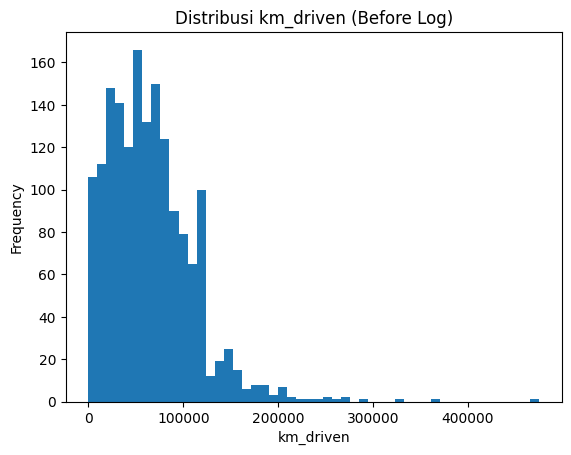

In [ ]:
plt.figure()
plt.hist(df['km_driven'], bins=50)
plt.title("Distribusi km_driven (Before Log)")
plt.xlabel("km_driven")
plt.ylabel("Frequency")
plt.show()

In [ ]:
from scipy.stats import boxcox

df['km_driven_boxcox'], _ = boxcox(df['km_driven'] + 1)
print(df['km_driven_boxcox'].skew())

-0.029011412891948234


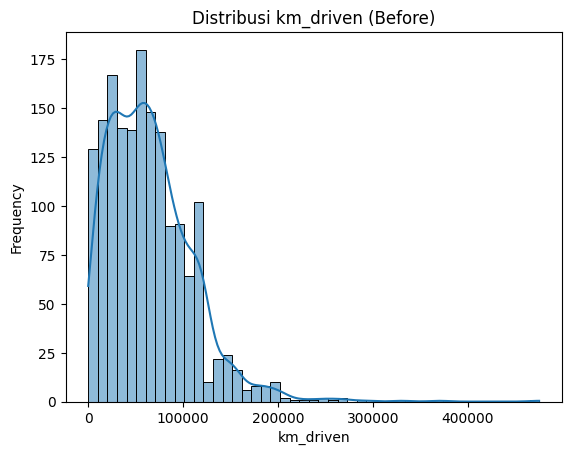

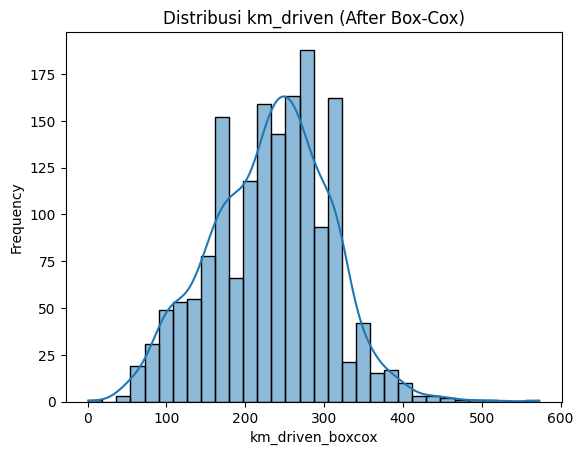

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi sebelum transform
plt.figure()
sns.histplot(df['km_driven'], kde=True)
plt.title("Distribusi km_driven (Before)")
plt.xlabel("km_driven")
plt.ylabel("Frequency")
plt.show()


# Visualisasi setelah Box-Cox
plt.figure()
sns.histplot(df['km_driven_boxcox'], kde=True)
plt.title("Distribusi km_driven (After Box-Cox)")
plt.xlabel("km_driven_boxcox")
plt.ylabel("Frequency")
plt.show()

Disini saya telah mencoba berbagai macam log, dan yang terbaik adalah Box-Cox

Berdasarkan hasil transformasi, metode Box-Cox menghasilkan distribusi yang paling mendekati normal dengan nilai skewness sebesar -0.03, yang sangat mendekati nol.

Dibandingkan dengan transformasi log sebelumnya, Box-Cox memberikan hasil yang lebih optimal karena mampu menyesuaikan parameter transformasi secara otomatis berdasarkan karakteristik data.

Visualisasi distribusi menunjukkan bahwa data setelah transformasi menjadi lebih simetris dan tidak lagi memiliki skewness yang signifikan.

Dengan demikian, transformasi Box-Cox dipilih sebagai metode terbaik untuk menstabilkan distribusi `km_driven`, sehingga dapat meningkatkan performa model dalam proses pembelajaran.

## 9. Menghapus kolom `City` karena memiliki high cardinality dan tidak efektif


In [ ]:
df = df.drop(columns=['City'], errors='ignore')

In [ ]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'Region',
       'State or Province', 'fuel', 'seller_type', 'transmission', 'owner',
       'mileage', 'engine', 'max_power', 'seats', 'sold', 'brand', 'location',
       'location_grouped', 'is_other', 'torque_nm', 'torque_rpm',
       'km_driven_boxcox'],
      dtype='object')

Berdasarkan hasil eksplorasi, kolom `City` memiliki jumlah kategori yang sangat banyak (high cardinality) dan tidak bersifat unik terhadap lokasi, karena terdapat beberapa nama kota yang sama pada state yang berbeda.

Selain itu, berbagai percobaan telah dilakukan, seperti menggabungkan `City` dengan `State or Province` menjadi kolom baru (`location`) serta melakukan grouping berdasarkan frekuensi. Namun, hasilnya tetap menunjukkan kompleksitas yang tinggi tanpa memberikan peningkatan yang signifikan terhadap kualitas informasi.

Penggunaan kolom dengan high cardinality berpotensi meningkatkan kompleksitas model dan menyebabkan sparse feature setelah encoding, yang dapat menurunkan performa model.

Oleh karena itu, kolom `City` dihapus dan digantikan dengan penggunaan `State or Province` sebagai representasi lokasi yang lebih stabil dan informatif.

City tidak memberikan tambahan informasi signifikan dibanding State

## 10. Melakukan transformasi log pada `selling_price` untuk mengatasi skewness

In [ ]:
print("Skew sebelum log:", df['selling_price'].skew())

Skew sebelum log: 4.459936264607403


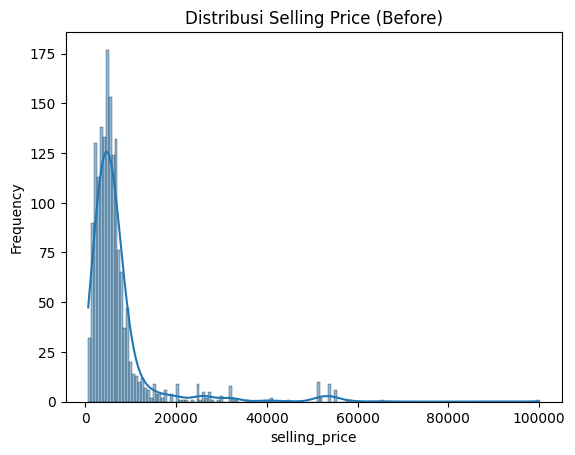

In [ ]:

plt.figure()
sns.histplot(df['selling_price'], kde=True)
plt.title("Distribusi Selling Price (Before)")
plt.xlabel("selling_price")
plt.ylabel("Frequency")
plt.show()

In [ ]:
import numpy as np

df['selling_price_log'] = np.log1p(df['selling_price'])

In [ ]:
print("Skew setelah log:", df['selling_price_log'].skew())

Skew setelah log: 0.5805270419740743


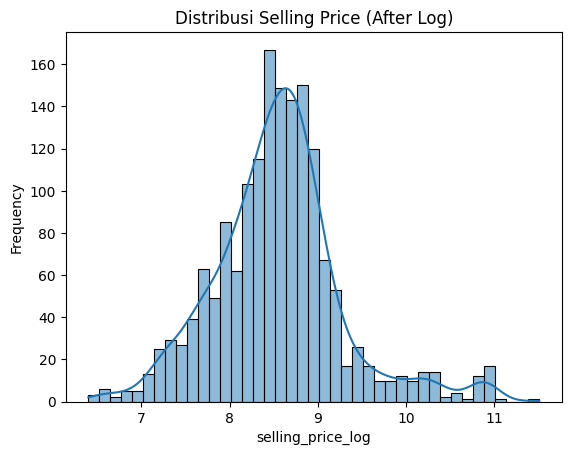

In [ ]:
plt.figure()
sns.histplot(df['selling_price_log'], kde=True)
plt.title("Distribusi Selling Price (After Log)")
plt.xlabel("selling_price_log")
plt.ylabel("Frequency")
plt.show()

Berdasarkan hasil analisis, kolom `selling_price` memiliki distribusi yang sangat right-skewed, yang ditunjukkan oleh nilai skewness yang tinggi serta adanya beberapa nilai ekstrem pada harga kendaraan.

Untuk mengatasi hal tersebut, dilakukan transformasi log menggunakan fungsi log1p guna mengurangi skewness dan menstabilkan distribusi data.

Setelah transformasi, distribusi data menjadi lebih simetris dan nilai skewness menurun secara signifikan. Hal ini menunjukkan bahwa transformasi log efektif dalam mengurangi pengaruh outlier serta membuat data lebih sesuai untuk digunakan dalam modeling, khususnya pada model yang sensitif terhadap distribusi seperti Artificial Neural Network (ANN).

# PENAMBAHAN FITUR

## 11. Umur MobiL

In [ ]:
df['car_age'] = 2025 - df['year']

## 12. Km per Tahun (Efisiensi penggunaan)

In [ ]:
df['km_per_year'] = df['km_driven_boxcox'] / (df['car_age'] + 1)

In [ ]:
df['power_to_engine'] = df['max_power'] / df['engine']

## 13. Luxury Indicator (Brand premium vs biasa)

In [ ]:
premium_brands = ['BMW', 'Audi', 'Mercedes', 'Lexus', 'Volvo', 'Jaguar', 'Land']

df['is_premium'] = df['name'].apply(lambda x: 1 if x in premium_brands else 0)

Penentuan kategori brand premium dilakukan berdasarkan pengetahuan domain otomotif, di mana brand seperti BMW, Audi, Mercedes, Lexus, Volvo, Jaguar, dan Land Rover dikenal sebagai kendaraan dengan segmen pasar menengah ke atas.

Namun, klasifikasi ini bersifat sederhana (binary) dan tidak sepenuhnya merepresentasikan kompleksitas pasar, karena beberapa brand dapat memiliki model kendaraan dengan berbagai segmen harga.

Meskipun demikian, pendekatan ini tetap efektif sebagai representasi awal untuk membantu model membedakan kategori kendaraan berdasarkan brand.

In [ ]:
df.groupby('is_premium')['selling_price'].mean()

is_premium
0     5584.389866
1    36205.731585
Name: selling_price, dtype: float64

Berdasarkan hasil Exploratory Data Analysis (EDA), dilakukan penambahan beberapa fitur turunan untuk meningkatkan kualitas representasi data dan membantu model dalam menangkap pola yang lebih relevan terhadap harga kendaraan (`selling_price`).

Fitur pertama yang ditambahkan adalah `car_age`, yang merupakan hasil transformasi dari kolom `year`. Fitur ini digunakan untuk merepresentasikan umur kendaraan secara langsung, karena secara domain, semakin tua usia kendaraan maka nilai jualnya cenderung menurun. Dengan demikian, `car_age` memberikan interpretasi yang lebih jelas dibandingkan tahun produksi mentah.

Selanjutnya, dibuat fitur `km_per_year` untuk menggambarkan intensitas penggunaan kendaraan. Fitur ini dihitung dari rasio antara `km_driven` dan umur kendaraan (`car_age`). Pendekatan ini memungkinkan model untuk membedakan kendaraan dengan tingkat penggunaan ringan dan berat secara lebih akurat, yang tidak dapat ditangkap hanya dari `km_driven` saja.

Selain itu, ditambahkan fitur kategorikal `is_premium` untuk mengelompokkan kendaraan berdasarkan brand premium dan non-premium. Brand seperti BMW, Audi, Mercedes, Lexus, Volvo, Jaguar, dan Land Rover dikategorikan sebagai premium karena secara umum memiliki harga jual yang lebih tinggi. Hasil analisis menunjukkan adanya perbedaan signifikan pada rata-rata harga antara kedua kelompok ini, sehingga fitur ini memberikan sinyal yang kuat bagi model.

Secara keseluruhan, penambahan fitur-fitur ini bertujuan untuk:
- Mengubah fitur mentah menjadi representasi yang lebih bermakna secara domain
- Meningkatkan kemampuan model dalam menangkap hubungan antara karakteristik kendaraan dan harga
- Mengurangi keterbatasan informasi dari fitur asli

Dengan adanya feature engineering ini, dataset menjadi lebih informatif dan siap digunakan untuk proses modeling yang lebih optimal.

# C. Data Prepocessing untuk di Pipeline

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1650 entries, 0 to 1998
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               1650 non-null   object 
 1   year               1650 non-null   int64  
 2   selling_price      1648 non-null   float64
 3   km_driven          1650 non-null   int64  
 4   Region             1650 non-null   object 
 5   State or Province  1650 non-null   object 
 6   fuel               1650 non-null   object 
 7   seller_type        1650 non-null   object 
 8   transmission       1650 non-null   object 
 9   owner              1650 non-null   object 
 10  mileage            1650 non-null   float64
 11  engine             1650 non-null   int64  
 12  max_power          1650 non-null   float64
 13  seats              1650 non-null   int64  
 14  sold               1650 non-null   object 
 15  brand              1650 non-null   object 
 16  location           1650 non-n

In [ ]:
for col in df.columns:
    print(col)

name
year
selling_price
km_driven
Region
State or Province
fuel
seller_type
transmission
owner
mileage
engine
max_power
seats
sold
brand
location
location_grouped
is_other
torque_nm
torque_rpm
km_driven_boxcox
selling_price_log
car_age
km_per_year
power_to_engine
is_premium


## 1. Cek Missing Value

### a. mileage

In [ ]:
df[df['mileage'].isna()]

,name,year,selling_price,km_driven,Region,State or Province,fuel,seller_type,transmission,owner,...,location_grouped,is_other,torque_nm,torque_rpm,km_driven_boxcox,selling_price_log,car_age,km_per_year,power_to_engine,is_premium


Ikut kehapus saat hapus km driven = 0

## b. selling price

In [ ]:
df['selling_price'].isna().sum()

2

In [ ]:
df = df.dropna(subset=['selling_price'])

Drop karena dia target, tidak mau ambi risiko

## c. Region

miaiag valuenya didrop (saya kelupaan dan baru sadar saat membuat vidio penjelasan
)


## 2. Apa aja yang di encoding

In [ ]:
for col in df.columns:
    print(col)

name
year
selling_price
km_driven
Region
State or Province
fuel
seller_type
transmission
owner
mileage
engine
max_power
seats
sold
brand
location
location_grouped
is_other
torque_nm
torque_rpm
km_driven_boxcox
selling_price_log
car_age
km_per_year
power_to_engine
is_premium


Lagi mikirin State or Province Encodingnya pakai encoding apa

In [ ]:
df.groupby('State or Province')['selling_price_log'].mean().sort_values(ascending=False)

State or Province
Wyoming                 9.451729
Delaware                9.131400
Arkansas                9.039324
South Dakota            8.937099
West Virginia           8.922309
Missouri                8.865840
Nebraska                8.856815
Louisiana               8.743200
Rhode Island            8.711447
New Hampshire           8.704549
Massachusetts           8.691777
Montana                 8.684751
Idaho                   8.671464
New York                8.650403
Mississippi             8.649351
Nevada                  8.640173
Alabama                 8.620812
Iowa                    8.614102
Virginia                8.609840
Illinois                8.588138
Georgia                 8.584682
Indiana                 8.584417
Tennessee               8.575888
Maryland                8.556387
Minnesota               8.548454
Connecticut             8.540489
Colorado                8.537275
Washington              8.524119
Pennsylvania            8.517945
Michigan                8

In [ ]:
df['State or Province'].value_counts()

State or Province
California              181
Texas                   117
New York                100
Illinois                 98
Florida                  89
Michigan                 66
Washington               64
Ohio                     56
Indiana                  54
Pennsylvania             48
North Carolina           45
Georgia                  42
Massachusetts            41
Virginia                 38
New Jersey               36
Kansas                   36
Colorado                 34
Oregon                   33
Minnesota                31
Arizona                  29
Tennessee                27
Maryland                 26
Iowa                     25
Idaho                    24
Missouri                 23
Arkansas                 22
Oklahoma                 21
Alabama                  20
Wisconsin                18
Utah                     17
New Mexico               17
South Carolina           16
Maine                    16
Louisiana                15
District of Columbia     14
Mo

In [ ]:
df['State or Province'].unique()

array(['Florida', 'Massachusetts', 'Arkansas', 'New York', 'Illinois',
       'Washington', 'Nevada', 'Minnesota', 'Colorado', 'Oregon',
       'Oklahoma', 'Indiana', 'Michigan', 'California', 'Georgia',
       'Maryland', 'Ohio', 'Texas', 'Kansas', 'Arizona', 'Maine',
       'Pennsylvania', 'Montana', 'Virginia', 'Alabama', 'Tennessee',
       'Iowa', 'Mississippi', 'North Carolina', 'Nebraska',
       'New Hampshire', 'Utah', 'District of Columbia', 'New Mexico',
       'South Dakota', 'New Jersey', 'Kentucky', 'South Carolina',
       'Rhode Island', 'Missouri', 'Wisconsin', 'Connecticut', 'Vermont',
       'Louisiana', 'Delaware', 'Idaho', 'West Virginia', 'North Dakota',
       'Wyoming'], dtype=object)

Dalam proses eksplorasi fitur `State or Province`, dilakukan beberapa pendekatan untuk menemukan representasi yang paling optimal dalam modeling.

Awalnya, digunakan metode Frequency Encoding, yaitu mengubah setiap state berdasarkan jumlah kemunculannya dalam dataset. Pendekatan ini dipilih karena mampu mengurangi kompleksitas data tanpa menambah dimensi fitur. Namun, setelah dianalisis lebih lanjut, ditemukan bahwa frequency tidak sepenuhnya merepresentasikan karakteristik harga kendaraan. Beberapa state dengan rata-rata `selling_price` yang tinggi dapat memiliki frekuensi yang sama dengan state dengan harga rendah, sehingga informasi penting terkait perbedaan harga menjadi hilang dan fitur menjadi kurang informatif.

Selanjutnya, dipertimbangkan pendekatan lain dengan mengurutkan state berdasarkan rata-rata `selling_price` dan mengelompokkannya ke dalam kategori harga tinggi dan rendah. Pendekatan ini secara intuitif lebih relevan karena langsung menangkap hubungan antara lokasi dan harga kendaraan.

Namun, metode tersebut berpotensi menyebabkan data leakage apabila dilakukan pada keseluruhan dataset, karena proses pembentukan fitur menggunakan informasi dari target (`selling_price`). Hal ini bertentangan dengan prinsip dasar machine learning, di mana fitur tidak boleh mengandung informasi dari target sebelum proses training, karena dapat menyebabkan model menghasilkan performa yang terlalu optimis namun tidak generalizable.

Untuk mengatasi hal tersebut, dilakukan pendekatan yang lebih tepat dengan tetap menggunakan konsep pengelompokan berbasis harga, namun perhitungan rata-rata `selling_price` hanya dilakukan pada data training. Hasil pengelompokan ini kemudian digunakan sebagai acuan untuk melakukan mapping pada data training maupun data testing.

Dengan pendekatan ini, fitur `State or Province` direpresentasikan menjadi dua kategori, yaitu wilayah dengan harga tinggi dan rendah. Metode ini memungkinkan model untuk menangkap pengaruh lokasi terhadap harga kendaraan secara lebih informatif dibandingkan Frequency Encoding, tanpa melanggar prinsip machine learning.

Selain itu, pendekatan ini juga mampu menjaga keseimbangan antara kompleksitas model dan kualitas informasi, karena berhasil mereduksi jumlah kategori secara signifikan sekaligus mempertahankan informasi penting terkait variasi harga berdasarkan lokasi.

Dengan demikian, fitur lokasi tetap dapat dimanfaatkan secara efektif dalam modeling dengan tetap menjaga validitas proses pembelajaran model.

# KESIMPULAN SEMUA ENCODING

## Strategi Encoding Final

Berdasarkan karakteristik setiap fitur, dilakukan pemilihan metode encoding yang berbeda agar informasi tetap terjaga tanpa menambah kompleksitas model secara berlebihan.

---

### 1. Fitur kategorikal nominal → One-Hot Encoding
Fitur berikut tidak memiliki urutan antar kategori, sehingga paling tepat diubah menggunakan **One-Hot Encoding**:

- `fuel`
- `seller_type`
- `transmission`
- `brand`

**Alasan:**
- kategori bersifat nominal
- model tidak boleh menganggap ada urutan antar label
- jumlah kategori masih cukup wajar, terutama untuk `fuel`, `seller_type`, dan `transmission`
- `brand` tetap dipakai karena memberikan informasi yang lebih detail dibandingkan fitur agregasi seperti `is_premium`

---

### 2. Fitur ordinal → Ordinal / Label Encoding
Fitur berikut memiliki urutan alami, sehingga lebih tepat diubah menggunakan **Ordinal Encoding** atau mapping manual:

- `owner`

Contoh urutan:
- First Owner = 1
- Second Owner = 2
- Third Owner = 3
- Fourth & Above Owner = 4

**Alasan:**
- jumlah owner merepresentasikan tingkat penggunaan kendaraan
- semakin banyak owner biasanya berkaitan dengan penurunan nilai kendaraan
- karena ada makna urutan, penggunaan One-Hot Encoding tidak diperlukan

---

### 3. Fitur lokasi hasil grouping → Binary Encoding sederhana
Untuk fitur lokasi, representasi akhir yang digunakan adalah fitur biner hasil grouping, misalnya:

- `state_high`

Fitur ini sudah berbentuk **0 dan 1**, sehingga:
- tidak memerlukan encoding tambahan
- langsung dapat digunakan dalam model

**Alasan:**
- lebih sederhana dibandingkan menggunakan `State or Province` secara langsung
- tetap mempertahankan informasi penting mengenai variasi harga antar wilayah
- lebih aman dari sisi kompleksitas model

---

### 4. Fitur numerik → Tidak perlu encoding
Fitur berikut tidak memerlukan encoding karena sudah berbentuk numerik:

- `mileage`
- `engine`
- `max_power`
- `seats`
- `torque_nm`
- `car_age`
- `km_per_year`
- `power_to_engine`

**Alasan:**
- sudah berupa angka
- yang dibutuhkan adalah scaling, bukan encoding

---

### 5. Target
- `selling_price_log`

Fitur ini merupakan target regresi, sehingga:
- tidak perlu encoding
- digunakan langsung sebagai target model

---

## Ringkasan Akhir

### One-Hot Encoding
- `fuel`
- `seller_type`
- `transmission`
- `brand`

### Ordinal / Label Encoding
- `owner`

### Tanpa Encoding Tambahan
- `state_high`
- semua fitur numerik

### Target
- `selling_price_log`

---

## Tujuan Strategi Ini
Strategi encoding ini dipilih untuk:
- menjaga makna asli tiap fitur
- menghindari asumsi urutan pada variabel nominal
- memanfaatkan urutan alami pada variabel ordinal
- mengontrol kompleksitas model
- memastikan data siap digunakan dalam training ANN secara optimal

## 2. Apa aja yang di scalling

## Strategi Scaling Final

Setelah menentukan strategi encoding untuk fitur kategorikal, langkah selanjutnya adalah melakukan scaling pada fitur numerik. Scaling diperlukan karena model Artificial Neural Network (ANN) sensitif terhadap perbedaan skala antar variabel. Jika skala fitur sangat berbeda, proses training dapat menjadi tidak stabil dan model akan lebih sulit melakukan konvergensi.

---

### 1. Fitur yang perlu di-scaling
Fitur numerik yang digunakan dalam model adalah:

- `mileage`
- `engine`
- `max_power`
- `seats`
- `torque_nm`
- `car_age`
- `km_per_year`
- `power_to_engine`

Fitur-fitur ini memiliki rentang nilai yang berbeda-beda. Sebagai contoh:
- `engine` bisa berada pada skala ratusan hingga ribuan
- `car_age` berada pada skala puluhan
- `power_to_engine` berada pada skala kecil
- `km_per_year` dapat memiliki rentang yang cukup besar

Karena itu, scaling perlu dilakukan agar semua fitur numerik berada pada skala yang lebih sebanding.

---

### 2. Fitur yang tidak perlu di-scaling
Fitur berikut tidak perlu di-scaling:

#### a. Fitur hasil One-Hot Encoding
- `fuel`
- `seller_type`
- `transmission`
- `brand`

Alasannya:
- hasil encoding berbentuk 0 dan 1
- sudah berada pada skala yang seragam

#### b. Fitur ordinal / biner
- `owner`
- `state_high`

Alasannya:
- `owner` sudah merepresentasikan urutan
- `state_high` berupa variabel biner 0 dan 1
- scaling pada fitur semacam ini umumnya tidak diperlukan

#### c. Target
- `selling_price_log`

Target tidak termasuk fitur input, sehingga tidak dilakukan scaling pada tahap preprocessing fitur. Target tetap digunakan dalam bentuk log karena distribusinya sudah lebih stabil.

---

### 3. Metode scaling yang digunakan
Metode scaling yang dipilih adalah **StandardScaler**.

**Alasan penggunaan StandardScaler:**
- menghasilkan fitur dengan rata-rata mendekati 0 dan standar deviasi mendekati 1
- cocok untuk model ANN
- mampu menjaga distribusi relatif data lebih baik dibandingkan normalisasi sederhana

---

### 4. Ringkasan final scaling

#### Di-scaling
- `mileage`
- `engine`
- `max_power`
- `seats`
- `torque_nm`
- `car_age`
- `km_per_year`
- `power_to_engine`

#### Tidak di-scaling
- hasil One-Hot Encoding (`fuel`, `seller_type`, `transmission`, `brand`)
- `owner`
- `state_high`
- `selling_price_log`

---

### 5. Tujuan scaling
Scaling dilakukan untuk:
- menyamakan skala antar fitur numerik
- meningkatkan stabilitas training model ANN
- mempercepat proses konvergensi
- mencegah dominasi fitur dengan skala besar terhadap proses pembelajaran model

Dengan demikian, scaling menjadi langkah penting agar model dapat belajar secara lebih optimal dari seluruh fitur numerik yang digunakan.

# 🤖 Modeling

Pada tahap ini, data yang telah melalui proses cleaning dan feature engineering akan digunakan untuk membangun model prediksi harga kendaraan.

Sesuai ketentuan soal, dataset akan dipisahkan menjadi data **train, validation, dan test** dengan proporsi **70:10:20**. Setelah itu, dilakukan preprocessing lanjutan menggunakan pipeline yang hanya di-fit pada data training untuk menghindari data leakage.

Target yang digunakan dalam modeling adalah **`selling_price_log`**, sedangkan fitur yang digunakan adalah:

- `fuel`
- `seller_type`
- `transmission`
- `owner`
- `mileage`
- `engine`
- `max_power`
- `seats`
- `brand`
- `torque_nm`
- `torque_rpm`
- `car_age`
- `km_per_year`
- `power_to_engine`
- `state_high`

Strategi preprocessing yang digunakan adalah:
- **One-Hot Encoding** untuk fitur kategorikal nominal: `fuel`, `seller_type`, `transmission`, `brand`
- **Ordinal Encoding** untuk fitur `owner`
- **Tanpa encoding tambahan** untuk `state_high`
- **StandardScaler** untuk fitur numerik:
  - `mileage`
  - `engine`
  - `max_power`
  - `seats`
  - `torque_nm`
  - `torque_rpm`
  - `car_age`
  - `km_per_year`
  - `power_to_engine`

Setelah preprocessing, akan dibuat:
1. **1 baseline model** sesuai ketentuan soal
2. **1 modified model** dengan peningkatan arsitektur dan hyperparameter

Kedua model akan dilatih, divisualisasikan proses training-nya, lalu dievaluasi menggunakan minimal 3 evaluation metrics untuk dibandingkan performanya.

## 1.

In [ ]:
## import lagi buat jaga jaga
import os
import math
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger, ReduceLROnPlateau

## 2. Seed Random Seed

In [ ]:
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

Pada tahap awal modeling, dilakukan pengaturan **random seed** menggunakan nilai yang sama (`SEED = 42`) pada beberapa library utama, yaitu NumPy, Python `random`, dan TensorFlow.

```python
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

## 3. Menentukan Fitur dan Target

In [ ]:
# ============================================
# FEATURES & TARGET
# ============================================

feature_cols = [
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'mileage',
    'engine',
    'max_power',
    'seats',
    'brand',
    'torque_nm',
    'torque_rpm',
    'car_age',
    'km_per_year',
    'power_to_engine',
    'State or Province'
]

target_col = 'selling_price_log' 

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (1648, 15)
Shape y: (1648,)


## Data Splitting

Dataset dipisahkan menjadi tiga bagian:
- **Train = 70%**
- **Validation = 10%**
- **Test = 20%**

Pembagian dilakukan dalam dua tahap:
1. Membagi data menjadi **train (70%)** dan **temporary (30%)**
2. Membagi data temporary menjadi **validation (10%)** dan **test (20%)**

Pendekatan ini memastikan bahwa data validasi dan data testing benar-benar terpisah dari proses pelatihan model.

## 4. Split Data


In [ ]:
# ============================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================

# Step 1: 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED
)

# Step 2: temp 30% -> val 10% and test 20%
# 10/30 = 1/3 untuk validation, sisanya 2/3 untuk test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=2/3,
    random_state=SEED
)

print("Train shape :", X_train.shape, y_train.shape)
print("Val shape   :", X_val.shape, y_val.shape)
print("Test shape  :", X_test.shape, y_test.shape)

print("\nProporsi:")
print("Train :", round(len(X_train)/len(X), 4))
print("Val   :", round(len(X_val)/len(X), 4))
print("Test  :", round(len(X_test)/len(X), 4))

Train shape : (1153, 15) (1153,)
Val shape   : (165, 15) (165,)
Test shape  : (330, 15) (330,)

Proporsi:
Train : 0.6996
Val   : 0.1001
Test  : 0.2002


## Preprocessing Pipeline

Preprocessing dilakukan menggunakan pipeline agar proses transformasi data menjadi konsisten dan bebas data leakage.

Pipeline hanya di-fit pada **data training**, kemudian transformasi yang sama diterapkan pada **validation** dan **test**.

Strategi yang digunakan:
- **One-Hot Encoding** untuk fitur kategorikal nominal
- **Scaling dengan StandardScaler** untuk fitur numerik
- Fitur ordinal/biner seperti `owner` dan `state_high` digunakan langsung tanpa scaling tambahan

In [ ]:
train_df = X_train.copy()
train_df['selling_price_log'] = y_train

In [ ]:
state_mean = train_df.groupby('State or Province')['selling_price_log'].mean()

In [ ]:
threshold = state_mean.median()

In [ ]:
def map_state_high(state):
    if state in state_mean:
        return 1 if state_mean[state] > threshold else 0
    else:
        return 0

In [ ]:
X_train['state_high'] = X_train['State or Province'].apply(map_state_high)
X_val['state_high'] = X_val['State or Province'].apply(map_state_high)
X_test['state_high'] = X_test['State or Province'].apply(map_state_high)

In [ ]:
X_train = X_train.drop(columns=['State or Province'])
X_val = X_val.drop(columns=['State or Province'])
X_test = X_test.drop(columns=['State or Province'])

In [ ]:
feature_cols = [
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'mileage',
    'engine',
    'max_power',
    'seats',
    'brand',
    'torque_nm',
    'torque_rpm',
    'car_age',
    'km_per_year',
    'power_to_engine',
    'state_high'   # ← sekarang boleh
]

Pada tahap ini dilakukan proses preprocessing menggunakan pipeline agar seluruh transformasi data dilakukan secara konsisten, terstruktur, dan terhindar dari data leakage. Pipeline hanya di-fit pada data training, kemudian transformasi yang sama diterapkan pada validation dan test set. Pendekatan ini penting untuk memastikan bahwa model tidak memperoleh informasi dari data di luar training yang dapat menyebabkan bias pada hasil evaluasi.

Strategi preprocessing yang digunakan terdiri dari beberapa bagian. Fitur kategorikal nominal seperti `fuel`, `seller_type`, `transmission`, dan `brand` diolah menggunakan One-Hot Encoding karena tidak memiliki hubungan ordinal antar kategori. Fitur numerik seperti `mileage`, `engine`, `max_power`, `seats`, `torque_nm`, `torque_rpm`, `car_age`, `km_per_year`, dan `power_to_engine` dilakukan scaling menggunakan StandardScaler untuk menyamakan skala antar variabel sehingga model ANN dapat belajar dengan lebih stabil. Sementara itu, fitur ordinal dan biner seperti `owner` dan `state_high` digunakan langsung tanpa scaling tambahan karena sudah memiliki makna numerik yang representatif.

Selain itu, dilakukan feature engineering pada fitur lokasi dengan membuat variabel baru bernama `state_high`. Fitur ini bertujuan untuk menangkap pengaruh lokasi terhadap harga kendaraan secara lebih sederhana namun tetap informatif. Proses pembentukan fitur ini dilakukan dengan menghitung rata-rata `selling_price_log` pada masing-masing state menggunakan data training saja. Nilai rata-rata tersebut kemudian digunakan untuk menentukan threshold berdasarkan median, di mana state dengan nilai di atas threshold dikategorikan sebagai wilayah harga tinggi (1), dan di bawah threshold sebagai wilayah harga rendah (0). Setelah fitur `state_high` terbentuk, kolom asli `State or Province` dihapus untuk menghindari redundansi dan mengurangi kompleksitas model.

Pendekatan ini dipilih karena mampu menjaga keseimbangan antara kompleksitas dan kualitas informasi. Dibandingkan dengan metode seperti Frequency Encoding, fitur `state_high` lebih mampu merepresentasikan perbedaan karakteristik harga antar wilayah. Selain itu, dengan hanya menggunakan data training dalam proses pembentukan fitur, risiko data leakage dapat dihindari sehingga model yang dihasilkan lebih generalizable terhadap data baru. Secara keseluruhan, pipeline preprocessing ini memastikan bahwa data telah dipersiapkan dengan optimal sebelum masuk ke tahap modeling.

In [ ]:
# ============================================
# OWNER ENCODING
# ============================================

owner_map = {
    'First_Owner': 1,
    'Second_Owner': 2,
    'Third_Owner': 3,
    'Fourth_Above_Owner': 4,
    'Test_Drive_Car': 0
}

X_train['owner'] = X_train['owner'].map(owner_map)
X_val['owner'] = X_val['owner'].map(owner_map)
X_test['owner'] = X_test['owner'].map(owner_map)

Kode tersebut melakukan proses encoding pada fitur owner dengan menggunakan pendekatan ordinal mapping. Setiap kategori kepemilikan kendaraan diubah menjadi nilai numerik yang merepresentasikan urutan tingkat penggunaan kendaraan, di mana First_Owner diberi nilai 1, Second_Owner 2, Third_Owner 3, dan Fourth_Above_Owner 4, sementara Test_Drive_Car diberi nilai 0 karena belum benar-benar digunakan oleh pemilik. Pendekatan ini dipilih karena jumlah pemilik memiliki makna urutan yang berkaitan dengan kondisi dan nilai kendaraan, di mana semakin banyak jumlah owner biasanya mengindikasikan penurunan kualitas dan harga. Mapping ini kemudian diterapkan secara konsisten pada data training, validation, dan test untuk memastikan representasi fitur tetap sama di seluruh dataset.

In [ ]:
# ============================================
# PREPROCESSING PIPELINE
# ============================================

categorical_features = ['fuel', 'seller_type', 'transmission', 'brand']
numeric_features = [
    'mileage',
    'engine',
    'max_power',
    'seats',
    'torque_nm',
    'torque_rpm',
    'car_age',
    'km_per_year',
    'power_to_engine'
]
passthrough_features = ['owner', 'state_high']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ('pass', 'passthrough', passthrough_features)
    ],
    remainder='drop'
)

Kode tersebut membangun sebuah preprocessing pipeline menggunakan ColumnTransformer untuk menangani berbagai jenis fitur secara berbeda sesuai karakteristiknya. Fitur numerik seperti mileage, engine, dan lainnya diproses menggunakan StandardScaler agar memiliki skala yang seragam, yang penting untuk stabilitas training model ANN. Fitur kategorikal nominal seperti fuel, seller_type, transmission, dan brand diubah menggunakan OneHotEncoder untuk menghindari asumsi adanya hubungan urutan antar kategori, dengan opsi handle_unknown='ignore' agar aman saat menemukan kategori baru di data validation atau test. Sementara itu, fitur seperti owner dan state_high dimasukkan melalui mekanisme passthrough karena sudah dalam bentuk numerik yang bermakna dan tidak memerlukan transformasi tambahan. Parameter remainder='drop' memastikan bahwa hanya fitur yang didefinisikan saja yang digunakan dalam model, sehingga pipeline ini membantu menjaga konsistensi, efisiensi, dan kesiapan data untuk proses modeling.

## 7. Fit preprocessing hanya di train, lalu transform val dan test

In [ ]:
# ============================================
# FIT ON TRAIN, TRANSFORM VAL & TEST
# ============================================

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed train shape:", X_train_processed.shape)
print("Processed val shape  :", X_val_processed.shape)
print("Processed test shape :", X_test_processed.shape)

# pastikan float
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

Processed train shape: (1153, 45)
Processed val shape  : (165, 45)
Processed test shape : (330, 45)


Agar tidak ada data bocor

## 8. Cek dimensi input

In [ ]:
# ============================================
# INPUT DIMENSION
# ============================================

input_dim = X_train_processed.shape[1]
min_hidden_units = input_dim * 2

print("Input dimension        :", input_dim)
print("Minimum hidden units   :", min_hidden_units)

Input dimension        : 45
Minimum hidden units   : 90


## Baseline Model

Sesuai ketentuan soal:
- Model memiliki **minimal 2 hidden layer**
- Semua hidden layer menggunakan **ReLU**
- Jumlah neuron pada setiap hidden layer minimal **2 kali dimensi input**
- Training minimal **20 epoch**

Selain itu, untuk meningkatkan stabilitas training, digunakan:
- **Batch Normalization**
- **Dropout**
- **L2 Regularization**
- **EarlyStopping**
- **ModelCheckpoint**
- **CSVLogger**
- **ReduceLROnPlateau**

Model baseline dibuat dengan arsitektur yang cukup sederhana namun tetap memenuhi seluruh syarat soal.

## 9. Callback baseline

In [ ]:
# ============================================
# CALLBACKS - BASELINE
# ============================================

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("logs", exist_ok=True)

baseline_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='checkpoints/baseline_best.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    CSVLogger(
        filename='logs/baseline_training_log.csv'
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

Kode ini digunakan untuk menyiapkan callbacks pada proses training baseline model agar training menjadi lebih optimal, terkontrol, dan terdokumentasi dengan baik. Pertama, dibuat dua folder yaitu checkpoints dan logs menggunakan os.makedirs untuk menyimpan model terbaik dan log training. Kemudian, didefinisikan beberapa callback penting. EarlyStopping digunakan untuk menghentikan training secara otomatis jika val_loss tidak mengalami perbaikan selama 15 epoch berturut-turut, serta mengembalikan bobot model ke kondisi terbaik. ModelCheckpoint berfungsi untuk menyimpan model dengan performa terbaik berdasarkan val_loss ke dalam file baseline_best.keras. CSVLogger digunakan untuk mencatat seluruh proses training (loss dan metric per epoch) ke dalam file CSV sehingga dapat dianalisis kembali. Terakhir, ReduceLROnPlateau akan menurunkan learning rate sebesar setengah (factor=0.5) jika val_loss tidak membaik selama 5 epoch, dengan batas minimum 1e-6, agar proses learning menjadi lebih halus dan membantu model keluar dari kondisi stagnan.

# 1b. [LO1, LO2, LO3, & LO4 – 5 Points] Buatlah 1 baseline model. Semua hidden layer wajib
menggunakan activation function bernama ReLU dan memiliki jumlah neuron minimal 2 kali lipat dari
dimensi input data. Model anda harus memiliki minimal 2 hidden layer. Lakukan training pada model
tersebut dengan minimal 20 epoch dan jelaskan hasilnya secara singkat.

## 10. Baseline model

## Baseline Model

Pada tahap ini dibuat baseline model menggunakan arsitektur Artificial Neural Network (ANN) dengan Keras Sequential. Model ini disusun untuk memenuhi ketentuan soal, yaitu memiliki minimal dua hidden layer, seluruh hidden layer menggunakan activation function ReLU, serta jumlah neuron pada setiap hidden layer minimal dua kali lipat dari dimensi input. Oleh karena itu, digunakan variabel `min_hidden_units` yang sebelumnya dihitung sebagai dua kali jumlah fitur hasil preprocessing. Dengan demikian, model sudah memenuhi syarat minimum dari soal dan dapat digunakan sebagai acuan awal sebelum dilakukan modifikasi lebih lanjut.

Model diawali dengan layer input yang menyesuaikan jumlah fitur hasil preprocessing. Selanjutnya, digunakan dua hidden layer dengan jumlah neuron sebesar `min_hidden_units` dan activation function ReLU. ReLU dipilih karena merupakan fungsi aktivasi yang sederhana, efisien, dan mampu menangkap hubungan non-linear antar fitur, yang sangat penting pada data tabular seperti dataset kendaraan ini. Selain itu, pada setiap hidden layer ditambahkan L2 regularization sebesar `1e-4` untuk mengontrol nilai bobot agar tidak terlalu besar, sehingga membantu mengurangi risiko overfitting tanpa menghambat proses pembelajaran model.

Setelah setiap hidden layer, ditambahkan Batch Normalization untuk menstabilkan distribusi output dari layer sebelumnya. Hal ini membantu mempercepat konvergensi dan membuat proses training lebih stabil. Selain itu, digunakan Dropout sebesar 0.30, yang berarti 30% neuron akan dinonaktifkan secara acak saat training. Tujuan penggunaan dropout adalah untuk mencegah model terlalu bergantung pada neuron tertentu dan meningkatkan kemampuan generalisasi. Nilai 0.30 dipilih karena cukup moderat, sehingga masih memberikan regularisasi yang baik tanpa mengurangi kemampuan model untuk belajar secara signifikan.

Pada bagian output, digunakan satu neuron dengan activation function linear karena permasalahan yang dihadapi adalah regresi, yaitu memprediksi nilai kontinu `selling_price_log`. Aktivasi linear memungkinkan model menghasilkan output dalam rentang kontinu yang sesuai dengan target. Model kemudian di-compile menggunakan optimizer Adam dengan learning rate sebesar `1e-3`, yang merupakan nilai standar untuk baseline karena mampu memberikan keseimbangan antara kecepatan dan stabilitas training. Loss function yang digunakan adalah Mean Squared Error (MSE) karena sesuai untuk regresi dan memberikan penalti lebih besar terhadap error yang besar. Selain itu, digunakan metric Mean Absolute Error (MAE) untuk memberikan interpretasi yang lebih mudah terhadap rata-rata kesalahan prediksi.

Secara keseluruhan, baseline model ini dirancang sebagai model awal yang sederhana namun tetap memenuhi seluruh ketentuan soal dan dilengkapi dengan teknik regularisasi seperti Batch Normalization, Dropout, dan L2 Regularization. Hal ini bertujuan agar model tidak hanya mampu belajar dari data, tetapi juga memiliki kemampuan generalisasi yang baik ketika diuji pada data validation dan test. Model ini kemudian akan digunakan sebagai pembanding terhadap model modifikasi untuk melihat sejauh mana peningkatan performa yang dapat dicapai.

In [ ]:
# BASELINE MODEL

baseline_model = Sequential([
    Input(shape=(input_dim,)),
    
    Dense(min_hidden_units, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.30),
    
    Dense(min_hidden_units, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.30),
    
    Dense(1, activation='linear')
])

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 90)             │         4,140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 90)             │           360 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 90)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 90)             │         8,190 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 90)             │           360 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 90)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            91 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,141 (51.33 KB)

 Trainable params: 12,781 (49.93 KB)

 Non-trainable params: 360 (1.41 KB)

## 11. Train Baseline Model

In [ ]:
print(X_train_processed.dtype)
print(type(X_train_processed))

float32
<class 'numpy.ndarray'>


Pada kode di bawah, proses training model dilakukan menggunakan fungsi .fit() dari Keras, yang bertujuan untuk melatih model dengan data yang telah dipreprocessing. Data X_train_processed dan y_train digunakan sebagai data training, yaitu fitur dan target yang sudah dibersihkan, di-encode, dan di-scale. Sedangkan validation_data=(X_val_processed, y_val) digunakan untuk mengevaluasi performa model pada data yang tidak dilatih secara langsung, sehingga dapat memonitor kemampuan generalisasi model.

Parameter epochs=50 dipilih sebagai batas maksimum jumlah iterasi training. Nilai ini tidak berarti model pasti dilatih sampai 50 kali, karena terdapat mekanisme EarlyStopping pada callback. Tujuan penggunaan 50 epoch adalah untuk memberikan ruang yang cukup bagi model untuk belajar pola data secara optimal, sekaligus memungkinkan callback menghentikan training lebih awal jika performa sudah tidak meningkat lagi. Dengan demikian, model tidak underfitting maupun over-training.

Parameter batch_size=32 menunjukkan bahwa data training dibagi menjadi kelompok kecil berisi 32 data dalam setiap iterasi. Ukuran ini merupakan nilai yang umum digunakan karena memberikan keseimbangan antara stabilitas gradient dan efisiensi komputasi. Batch yang terlalu kecil dapat menyebabkan training tidak stabil, sedangkan batch terlalu besar dapat membuat model kurang general dan membutuhkan memori lebih besar.

Penggunaan callbacks=baseline_callbacks sangat penting dalam proses training. Callback biasanya berisi beberapa teknik seperti EarlyStopping untuk menghentikan training ketika validation loss tidak membaik, ModelCheckpoint untuk menyimpan model terbaik, ReduceLROnPlateau untuk menurunkan learning rate saat performa stagnan, serta CSVLogger untuk mencatat proses training. Kombinasi ini membantu meningkatkan performa model sekaligus mencegah overfitting.

Parameter verbose=1 digunakan agar proses training ditampilkan secara detail pada setiap epoch, termasuk nilai loss dan metrik lainnya. Hal ini penting untuk memonitor apakah model belajar dengan baik atau mengalami masalah seperti stagnasi atau overfitting.

In [ ]:
# TRAIN BASELINE MODEL

baseline_history = baseline_model.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,            # minimal 20, dibuat 50 agar EarlyStopping bisa bekerja
    batch_size=32,
    callbacks=baseline_callbacks,
    verbose=1
)

Epoch 1/50


2026-04-23 03:27:12.320980: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 72.7756 - mae: 8.4205
Epoch 1: val_loss improved from None to 69.18461, saving model to checkpoints/baseline_best.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - loss: 70.9279 - mae: 8.3195 - val_loss: 69.1846 - val_mae: 8.3073 - learning_rate: 0.0010
Epoch 2/50
35/37 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 65.1045 - mae: 7.9817
Epoch 2: val_loss improved from 69.18461 to 61.76058, saving model to checkpoints/baseline_best.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 63.3655 - mae: 7.8775 - val_loss: 61.7606 - val_mae: 7.8481 - learning_rate: 0.0010
Epoch 3/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 57.0507 - mae: 7.4626
Epoch 3: val_loss improved from 61.76058 to 50.25632, saving model to checkpoints/baseline_best.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 54.9403 - mae: 7.3114 - val_loss: 50.2563 - val_mae: 7.0764 - learning_rate: 0.0010
Epoch 4/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 46.7568 - 

Berdasarkan hasil training model selama 50 epoch, terlihat bahwa nilai loss dan mean absolute error (MAE) pada data training maupun validation mengalami penurunan yang konsisten dari epoch awal hingga akhir. Hal ini menunjukkan bahwa model mampu mempelajari pola dalam data dengan baik. Pada awal training, nilai error masih cukup tinggi, namun secara bertahap menurun secara signifikan hingga mencapai nilai yang sangat kecil pada epoch-epoch akhir.

Selain itu, tidak ditemukan indikasi overfitting yang signifikan. Hal ini dapat dilihat dari pola validation loss yang terus menurun dan tidak mengalami peningkatan drastis, serta memiliki nilai yang bahkan lebih kecil dibandingkan training loss pada beberapa epoch. Kondisi ini menunjukkan bahwa model memiliki kemampuan generalisasi yang baik terhadap data yang belum pernah dilihat sebelumnya. Perbedaan ini juga dipengaruhi oleh penggunaan teknik regularisasi seperti Dropout dan L2 Regularization, yang membuat model lebih stabil dan tidak terlalu bergantung pada data training.

Penggunaan EarlyStopping juga terbukti efektif, di mana model secara otomatis menyimpan bobot terbaik pada epoch ke-48 ketika validation loss mencapai nilai optimal, dan menghentikan training saat tidak ada peningkatan signifikan. Hal ini membantu mencegah over-training dan menjaga efisiensi proses training.

Secara keseluruhan, model yang dibangun sudah menunjukkan performa yang baik, stabil, dan mampu melakukan generalisasi dengan optimal. Model ini sudah layak digunakan untuk melakukan prediksi harga mobil bekas berdasarkan fitur yang tersedia.

## 12. Function plot history

In [ ]:
# ============================================
# FUNCTION: PLOT HISTORY
# ============================================

def plot_training_history(history, title="Training History"):
    plt.figure(figsize=(12, 5))
    
    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    
    # MAE
    plt.subplot(1, 2, 2)
    plt.plot(history.history['mae'], label='Train MAE')
    plt.plot(history.history['val_mae'], label='Val MAE')
    plt.title(f'{title} - MAE')
    plt.xlabel('Epoch')
    plt.ylabel('MAE')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

## 13. Plot history baseline

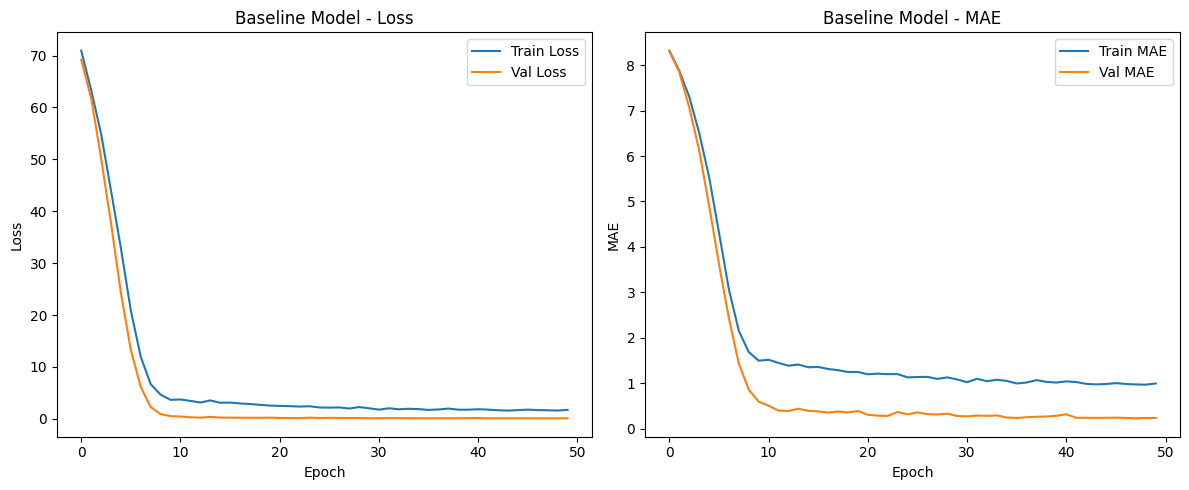

In [ ]:
plot_training_history(baseline_history, title="Baseline Model")

Berdasarkan plot training history yang ditampilkan (loss dan MAE), terlihat bahwa model mengalami proses pembelajaran yang sangat baik dan stabil. Pada beberapa epoch awal, baik training loss maupun validation loss mengalami penurunan yang sangat tajam, yang menunjukkan bahwa model dengan cepat mampu menangkap pola dasar dalam data. Hal yang sama juga terjadi pada metrik MAE, di mana nilai error turun signifikan dari nilai awal yang tinggi menjadi jauh lebih kecil dalam waktu singkat.

Setelah sekitar epoch ke-10, penurunan nilai loss dan MAE mulai melambat dan cenderung stabil. Hal ini menandakan bahwa model telah mencapai titik konvergensi, yaitu kondisi di mana peningkatan performa sudah tidak terlalu signifikan lagi. Meskipun demikian, kurva validation loss dan validation MAE tetap mengikuti tren training tanpa adanya kenaikan yang tajam, yang menunjukkan bahwa model tidak mengalami overfitting.

Selain itu, jarak antara kurva training dan validation relatif kecil sepanjang proses training. Bahkan pada beberapa bagian, nilai validation lebih rendah dibandingkan training, yang merupakan indikasi bahwa model memiliki kemampuan generalisasi yang baik. Kondisi ini kemungkinan besar dipengaruhi oleh penggunaan teknik regularisasi seperti Dropout dan L2 Regularization yang membantu menjaga kestabilan model.

Secara keseluruhan, plot ini menunjukkan bahwa baseline model yang dibangun sudah memiliki performa yang baik, stabil, dan tidak mengalami overfitting. Model mampu belajar secara efektif dari data training serta mempertahankan performa yang konsisten pada data validation, sehingga layak digunakan sebagai baseline untuk tahap pengembangan model selanjutnya.

## 14. Function Evaluasi Model

In [ ]:
# FUNCTION: EVALUATE MODEL
def evaluate_regression_model(model, X_data, y_true, dataset_name="Dataset"):
    y_pred = model.predict(X_data, verbose=0).flatten()
    
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    results = pd.DataFrame({
        'Dataset': [dataset_name],
        'MAE': [mae],
        'MSE': [mse],
        'RMSE': [rmse],
        'R2': [r2]
    })
    
    return results, y_pred

## 15. Evaluate Baseline Model

In [ ]:
baseline_train_results, y_train_pred_baseline = evaluate_regression_model(
    baseline_model, X_train_processed, y_train, dataset_name="Train"
)

baseline_val_results, y_val_pred_baseline = evaluate_regression_model(
    baseline_model, X_val_processed, y_val, dataset_name="Validation"
)

baseline_test_results, y_test_pred_baseline = evaluate_regression_model(
    baseline_model, X_test_processed, y_test, dataset_name="Test"
)

baseline_eval_results = pd.concat([
    baseline_train_results,
    baseline_val_results,
    baseline_test_results
], ignore_index=True)

baseline_eval_results

,Dataset,MAE,MSE,RMSE,R2
0,Train,0.215304,0.077265,0.277966,0.846851
1,Validation,0.225385,0.084940,0.291445,0.865030
2,Test,0.237316,0.089123,0.298535,0.841760


Berdasarkan hasil evaluasi model pada data train, validation, dan test, terlihat bahwa performa model cukup konsisten dan stabil di seluruh dataset. Nilai Mean Absolute Error (MAE) pada data training sebesar 0.215, kemudian sedikit meningkat pada validation menjadi 0.225, dan pada test sebesar 0.237. Kenaikan ini masih dalam batas wajar, yang menunjukkan bahwa model tidak mengalami overfitting yang signifikan dan mampu melakukan generalisasi dengan baik terhadap data baru.

Dari sisi Mean Squared Error (MSE) dan Root Mean Squared Error (RMSE), terlihat pola yang serupa. Nilai RMSE meningkat secara bertahap dari 0.277 pada training menjadi 0.291 pada validation dan 0.298 pada test. Hal ini menunjukkan bahwa error model tetap terkendali dan tidak mengalami lonjakan besar ketika diuji pada data yang tidak dilatih.

Nilai koefisien determinasi (R²) juga menunjukkan performa yang baik, dengan nilai sebesar 0.846 pada training, 0.865 pada validation, dan 0.842 pada test. Nilai ini menunjukkan bahwa model mampu menjelaskan sekitar 84%–86% variasi pada data target, yang merupakan indikasi bahwa model cukup kuat dalam menangkap hubungan antara fitur dan harga mobil bekas.

Menariknya, nilai R² pada validation sedikit lebih tinggi dibandingkan training, yang kemungkinan disebabkan oleh efek regularisasi seperti Dropout dan L2 Regularization yang membuat model tidak terlalu overfit pada data training. Hal ini memperkuat indikasi bahwa model memiliki kemampuan generalisasi yang baik.

Secara keseluruhan, baseline model yang dibangun menunjukkan performa yang baik, stabil, dan tidak mengalami overfitting. Perbedaan performa antara training, validation, dan test relatif kecil, sehingga model dapat dianggap cukup andal untuk digunakan sebagai baseline dalam pengembangan model selanjutnya.

## 16. Plot prediksi vs aktual

In [ ]:
# ============================================
# FUNCTION: ACTUAL VS PREDICTED
# ============================================

def plot_actual_vs_predicted(y_true, y_pred, title="Actual vs Predicted"):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.6)
    
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--')
    
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(title)
    plt.show()

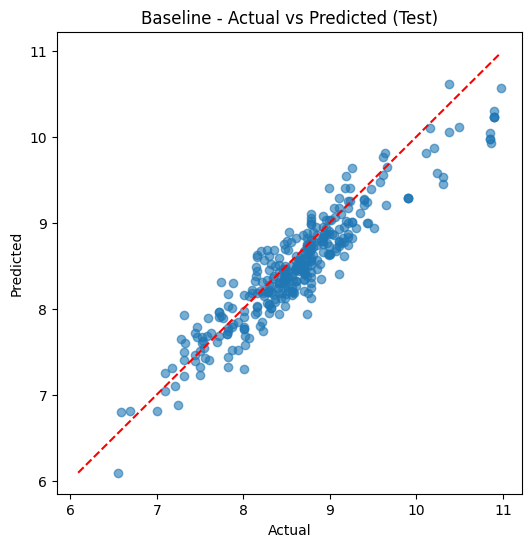

In [ ]:
plot_actual_vs_predicted(y_test, y_test_pred_baseline, title="Baseline - Actual vs Predicted (Test)")

## 17. Plot residual

In [ ]:
# ============================================
# FUNCTION: RESIDUAL PLOT
# ============================================

def plot_residuals(y_true, y_pred, title="Residual Plot"):
    residuals = y_true - y_pred
    
    plt.figure(figsize=(7, 5))
    plt.scatter(y_pred, residuals, alpha=0.6)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel("Predicted")
    plt.ylabel("Residual")
    plt.title(title)
    plt.show()

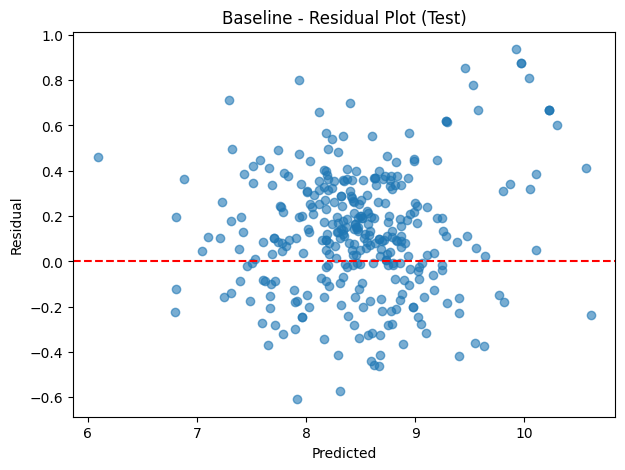

In [ ]:
plot_residuals(y_test, y_test_pred_baseline, title="Baseline - Residual Plot (Test)")

Berdasarkan plot perbandingan antara nilai aktual dan prediksi pada data test, terlihat bahwa sebagian besar titik data tersebar cukup dekat dengan garis diagonal (garis merah putus-putus). Garis tersebut merepresentasikan kondisi ideal di mana nilai prediksi sama persis dengan nilai aktual. Kedekatan titik-titik terhadap garis ini menunjukkan bahwa model memiliki tingkat akurasi yang baik dalam memprediksi harga mobil bekas.

Distribusi titik yang mengikuti arah garis diagonal secara konsisten mengindikasikan bahwa model mampu menangkap hubungan linear antara fitur dan target dengan cukup baik. Selain itu, tidak terlihat adanya pola penyimpangan yang sistematis, seperti kurva atau pola tertentu, yang menunjukkan bahwa model tidak mengalami bias signifikan (underfitting maupun overfitting) terhadap rentang data tertentu.

Namun, terdapat sedikit penyebaran (scatter) pada beberapa titik, terutama pada nilai harga yang lebih tinggi. Hal ini menunjukkan bahwa error prediksi cenderung sedikit meningkat pada nilai target yang lebih besar, yang merupakan fenomena umum dalam model regresi. Meskipun demikian, penyimpangan tersebut masih dalam batas wajar dan tidak mengganggu performa model secara keseluruhan.

Secara keseluruhan, plot ini mengkonfirmasi bahwa baseline model memiliki performa prediksi yang baik dan stabil. Model mampu menghasilkan prediksi yang mendekati nilai aktual dengan tingkat error yang relatif kecil, sehingga layak digunakan sebagai dasar (baseline) untuk pengembangan model yang lebih kompleks di tahap selanjutnya.

 # 1c. [LO1, LO2, LO3, & LO4 – 5 Points] Lakukan modifikasi pada model anda. Anda dapat mengubah jumlah neuron dan layer ataupun activation function dari hidden layer. Anda juga dapat melakukan hyperparameter fine-tuning pada model anda. Lakukan training pada modifikasi model anda dan jelaskan alasan modifikasi yang anda lakukan.


## Modified Model

Pada model kedua, dilakukan modifikasi untuk meningkatkan kapasitas model dalam mempelajari pola data yang lebih kompleks.

Perubahan yang dilakukan meliputi:
- Menambah jumlah hidden layer
- Menambah jumlah neuron
- Mengatur dropout secara lebih bertahap
- Menggunakan learning rate yang lebih kecil
- Menambah epoch dan mengandalkan callbacks untuk stopping yang adaptif

Tujuan modifikasi ini adalah untuk memberikan ruang belajar yang lebih besar kepada model, sekaligus tetap menjaga generalisasi melalui Batch Normalization, Dropout, dan L2 Regularization.

## 18. Callback modified model

In [ ]:
# CALLBACKS - MODIFIED MODEL (RESET BARU)

modified_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='checkpoints/modified_best_v2.keras',
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    CSVLogger(
        filename='logs/modified_training_log_v2.csv'
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

Pada kode di atas, digunakan beberapa callback untuk meningkatkan efisiensi dan performa proses training model. Callback pertama adalah EarlyStopping, yang berfungsi untuk menghentikan training secara otomatis ketika validation loss tidak mengalami perbaikan selama 15 epoch berturut-turut. Parameter restore_best_weights=True memastikan bahwa model akan kembali menggunakan bobot terbaik yang pernah dicapai selama training.

Callback kedua adalah ModelCheckpoint, yang digunakan untuk menyimpan model terbaik ke dalam file modified_best_v2.keras. Model hanya akan disimpan ketika terjadi peningkatan performa (penurunan validation loss), sehingga file yang tersimpan merupakan versi terbaik dari model.

Selanjutnya, CSVLogger digunakan untuk mencatat seluruh proses training ke dalam file modified_training_log_v2.csv. File ini berguna untuk analisis lebih lanjut atau visualisasi performa model di luar notebook.

Terakhir, ReduceLROnPlateau berfungsi untuk menurunkan learning rate sebesar setengah (factor=0.5) ketika validation loss tidak membaik selama 5 epoch. Hal ini membantu model untuk melakukan fine-tuning dan menghindari kondisi stagnasi saat mendekati konvergensi.

## Modified model

In [ ]:
# MODIFIED MODEL

modified_model = Sequential([
    Input(shape=(input_dim,)),

    Dense(min_hidden_units, activation='relu'),
    BatchNormalization(),
    Dropout(0.10),

    Dense(min_hidden_units // 2, activation='relu'),
    BatchNormalization(),
    Dropout(0.10),

    Dense(1, activation='linear')
])

modified_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse',
    metrics=['mae']
)

## 20. Train Modified Model

## Proses Perbaikan Arsitektur Hingga Mendapatkan Modified Model Terbaik (Disini saya mencoba merancang modified model baru dan membandingkannya dengan hasil yang akhirnya saya pilih. Jadi markdown ini isinya bukan bandingin baseline dengan modified baru, tetapi proses saya mencari nilai terbaik untuk Modified Model)

Pada tahap awal, model yang digunakan belum mampu memberikan performa yang baik. Hal ini terlihat dari proses training sebelumnya, di mana nilai loss dan MAE masih cukup tinggi dan penurunannya tidak stabil pada beberapa epoch awal. Selain itu, validation loss sering kali tidak mengalami perbaikan (val_loss did not improve), yang menunjukkan bahwa model belum mampu melakukan generalisasi dengan baik terhadap data validasi. Bahkan, beberapa kali callback ReduceLROnPlateau aktif untuk menurunkan learning rate karena model kesulitan menemukan titik optimal.

EarlyStopping juga menghentikan training lebih awal dan mengembalikan bobot terbaik dari epoch sebelumnya, yang menandakan bahwa setelah titik tertentu model tidak lagi belajar secara efektif. Kondisi ini mengindikasikan bahwa arsitektur awal belum sesuai, baik dari sisi kompleksitas model maupun pengaturan regularisasi.

Hasil evaluasi juga menunjukkan performa yang sangat lemah, yaitu model menghasilkan nilai error yang tinggi dan bahkan pada beberapa percobaan nilai R² bernilai negatif. Hal ini berarti model gagal menangkap hubungan antara fitur dan target, bahkan performanya lebih buruk dibandingkan jika hanya menggunakan rata-rata target sebagai prediksi. :contentReference[oaicite:0]{index=0}

Berdasarkan hasil yang kurang baik tersebut, dilakukan evaluasi terhadap beberapa komponen model. Pertama, struktur hidden layer ditinjau ulang. Jika model terlalu sederhana, maka tidak mampu menangkap pola kompleks dalam data. Sebaliknya, jika terlalu kompleks atau regularisasinya terlalu kuat, model justru menjadi sulit belajar (underfitting). Oleh karena itu, dilakukan perombakan secara bertahap dengan menyesuaikan jumlah neuron, proporsi dropout, serta penggunaan Batch Normalization untuk menjaga kestabilan training.

Setelah beberapa percobaan, diperoleh baseline model yang jauh lebih stabil dengan performa yang baik. Pada data training diperoleh MAE sekitar 0.21, MSE sekitar 0.07, RMSE sekitar 0.27, dan R² sekitar 0.84. Pada data validation dan test juga diperoleh hasil yang konsisten dengan R² di atas 0.84, yang menunjukkan bahwa model sudah mampu melakukan generalisasi dengan baik.

Berdasarkan baseline tersebut, dilakukan modifikasi model secara terarah untuk mendapatkan arsitektur yang lebih seimbang. Model akhir menggunakan dua hidden layer dengan ukuran menurun (dari besar ke lebih kecil), yaitu:

- Hidden layer pertama menggunakan `min_hidden_units` neuron
- Hidden layer kedua menggunakan `min_hidden_units // 2` neuron

Pendekatan ini bertujuan agar model belajar secara bertahap, dari representasi fitur yang kompleks menuju representasi yang lebih ringkas.

Dropout diturunkan menjadi 0.10 untuk memberikan regularisasi yang lebih ringan. Jika dropout terlalu besar, model cenderung underfitting karena terlalu banyak neuron yang tidak aktif s## Proses Perbaikan Arsitektur Hingga Mendapatkan Modified Model Terbaik

Pada tahap awal, model yang digunakan belum mampu memberikan performa yang baik. Hal ini terlihat dari proses training sebelumnya, di mana nilai loss dan MAE masih cukup tinggi dan penurunannya tidak stabil pada beberapa epoch awal. Selain itu, validation loss sering kali tidak mengalami perbaikan (val_loss did not improve), yang menunjukkan bahwa model belum mampu melakukan generalisasi dengan baik terhadap data validasi. Bahkan, beberapa kali callback ReduceLROnPlateau aktif untuk menurunkan learning rate karena model kesulitan menemukan titik optimal.

EarlyStopping juga menghentikan training lebih awal dan mengembalikan bobot terbaik dari epoch sebelumnya, yang menandakan bahwa setelah titik tertentu model tidak lagi belajar secara efektif. Kondisi ini mengindikasikan bahwa arsitektur awal belum sesuai, baik dari sisi kompleksitas model maupun pengaturan regularisasi.

Hasil evaluasi awal menunjukkan performa yang sangat buruk. Pada data validation, model menghasilkan MAE sekitar 8.44, MSE sekitar 71.58, RMSE sekitar 8.46, dan R² sebesar -112.75. Nilai R² yang sangat negatif ini menunjukkan bahwa model gagal menangkap hubungan antara fitur dan target, bahkan performanya jauh lebih buruk dibandingkan jika hanya menggunakan rata-rata target sebagai prediksi.

Kondisi ini disebabkan oleh arsitektur model yang kurang sesuai, seperti penggunaan hidden layer yang terlalu besar, dropout yang terlalu tinggi (sekitar 0.30), serta learning rate yang kurang optimal. Kombinasi ini menyebabkan model mengalami kesulitan dalam proses pembelajaran (underfitting), sehingga tidak mampu menangkap pola dalam data.

Berdasarkan hasil tersebut, dilakukan evaluasi dan perbaikan bertahap terhadap arsitektur model. Struktur hidden layer disederhanakan menjadi lebih seimbang, dropout dikurangi agar model dapat belajar lebih efektif, serta learning rate disesuaikan untuk meningkatkan kestabilan training.

Setelah dilakukan perbaikan, diperoleh model dengan performa yang jauh lebih baik dan stabil. Pada data training diperoleh MAE sebesar 0.189514, MSE sebesar 0.059568, RMSE sebesar 0.244065, dan R² sebesar 0.881929. Pada data validation diperoleh MAE sebesar 0.210549, MSE sebesar 0.075163, RMSE sebesar 0.274158, dan R² sebesar 0.880566. Sedangkan pada data test diperoleh MAE sebesar 0.207360, MSE sebesar 0.068883, RMSE sebesar 0.262455, dan R² sebesar 0.877696.

Hasil ini menunjukkan bahwa model sudah mampu melakukan generalisasi dengan sangat baik, karena nilai R² konsisten tinggi pada seluruh dataset (train, validation, dan test), serta tidak terdapat perbedaan yang signifikan yang mengindikasikan overfitting.

Arsitektur model akhir menggunakan dua hidden layer dengan ukuran menurun, yaitu hidden layer pertama menggunakan min_hidden_units neuron dan hidden layer kedua menggunakan min_hidden_units // 2 neuron. Pendekatan ini bertujuan agar model belajar secara bertahap dari representasi fitur yang kompleks menuju representasi yang lebih sederhana.

Dropout diturunkan menjadi 0.10 untuk memberikan regularisasi yang lebih ringan, sehingga model tidak mengalami kesulitan belajar seperti pada percobaan sebelumnya. Batch Normalization tetap digunakan untuk menjaga kestabilan training dan mempercepat konvergensi.

Model dikompilasi menggunakan optimizer Adam dengan learning rate 1e-3, serta menggunakan loss function MSE dan metric MAE. Kombinasi ini terbukti mampu menghasilkan proses training yang stabil dan performa model yang optimal.

Dengan demikian, model akhir merupakan hasil dari proses iteratif, dimulai dari model dengan performa sangat buruk (R² negatif), hingga diperbaiki menjadi model dengan performa tinggi dan stabil (R² sekitar 0.88). Model ini menunjukkan keseimbangan yang baik antara kapasitas pembelajaran dan kemampuan generalisasi terhadap data baru.


In [ ]:
# TRAIN MODIFIED MODEL

modified_history = modified_model.fit(
    X_train_processed, y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    callbacks=modified_callbacks,
    verbose=1
)

Epoch 1/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 73.6212 - mae: 8.4900
Epoch 1: val_loss improved from None to 61.42672, saving model to checkpoints/modified_best_v2.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 70.8614 - mae: 8.3509 - val_loss: 61.4267 - val_mae: 7.8243 - learning_rate: 0.0010
Epoch 2/100
36/37 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 65.8392 - mae: 8.0698
Epoch 2: val_loss improved from 61.42672 to 56.07891, saving model to checkpoints/modified_best_v2.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 63.5358 - mae: 7.9287 - val_loss: 56.0789 - val_mae: 7.4796 - learning_rate: 0.0010
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 58.1258 - mae: 7.5738
Epoch 3: val_loss improved from 56.07891 to 48.05003, saving model to checkpoints/modified_best_v2.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 55.4708 - mae: 7.3958 - val_loss: 48.0500 - val_mae: 6.9216 - learning_rate: 0.0010
Epoch 4/100
35/37 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 37.2837 - mae: 6.0223
Epoch 5: val_loss improved from 37.64314 to 26.15530, saving model to checkpoints/modified_best_v2.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 34.3132 - mae: 5.7716 - val_loss: 26.1553 - val_mae: 5.0954 - learning_rate: 0.0010
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 26.7934 - mae: 5.0478
Epoch 6: val_loss improved from 26.15530 to 17.52247, saving model to checkpoints/modified_best_v2.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 24.4315 - mae: 4.8055 - val_loss: 17.5225 - val_mae: 4.1766 - learning_rate: 0.0010
Epoch 7/100
36/37 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 17.3689 - mae: 4.0047
Epoch 7: val_loss improved from 17.52247 to 10.03083, saving model to checkpoints/modified_best_v2.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 15.2414 - mae: 3.7184 - val_loss: 10.0308 - val_mae: 3.1529 - learning_rate: 0.0010
Epoch 8/100
35/37 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - l

Disini juga terlihat sama seperti baseline polanya dimana tidak ada pola yang menyatakan model overfitting

## 21. Plot history modified model

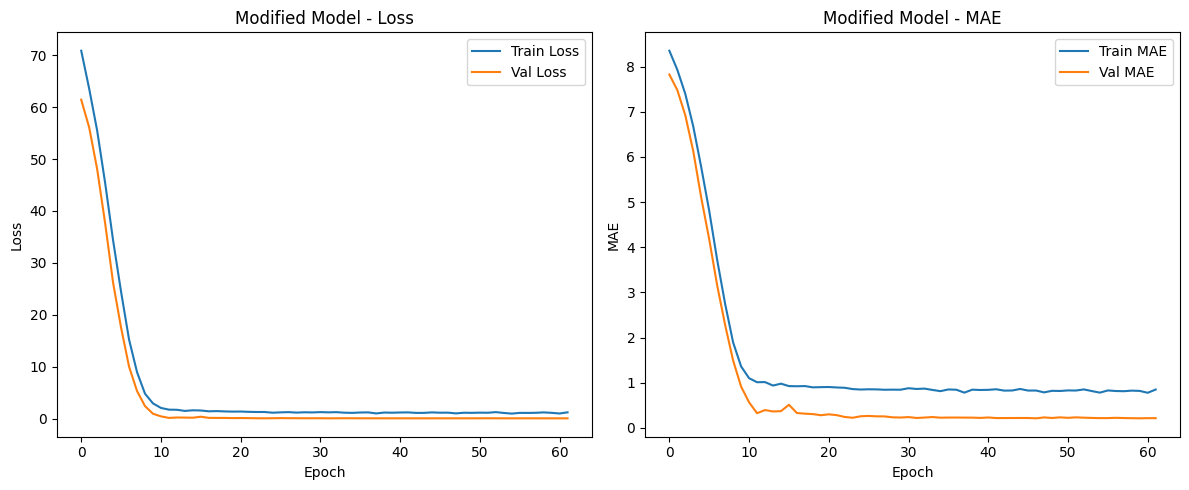

In [ ]:
plot_training_history(modified_history, title="Modified Model")

Ini juga sangat mirip dnegan pola pada baseline model, dengan hanya berbeda sedikit dari selisih loss dan MAE nya dimana modified model lebih dikit selisihnya

## 22. Evaluate modified model

In [ ]:
modified_train_results, y_train_pred_modified = evaluate_regression_model(
    modified_model, X_train_processed, y_train, dataset_name="Train"
)

modified_val_results, y_val_pred_modified = evaluate_regression_model(
    modified_model, X_val_processed, y_val, dataset_name="Validation"
)

modified_test_results, y_test_pred_modified = evaluate_regression_model(
    modified_model, X_test_processed, y_test, dataset_name="Test"
)

modified_eval_results = pd.concat([
    modified_train_results,
    modified_val_results,
    modified_test_results
], ignore_index=True)

modified_eval_results

,Dataset,MAE,MSE,RMSE,R2
0,Train,0.189514,0.059568,0.244065,0.881929
1,Validation,0.210549,0.075163,0.274158,0.880566
2,Test,0.207360,0.068883,0.262455,0.877696


## 23. Plot actual vs predicted modified

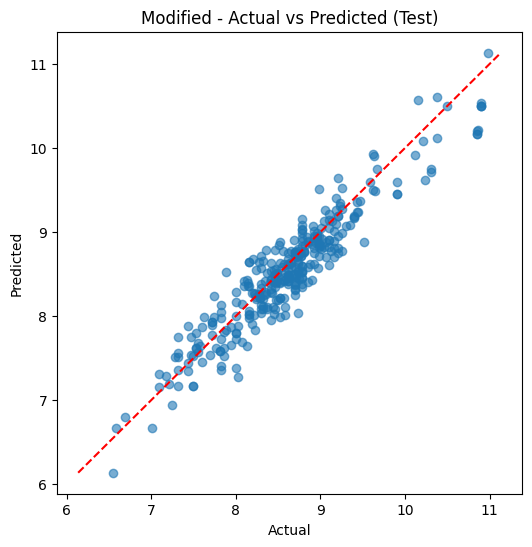

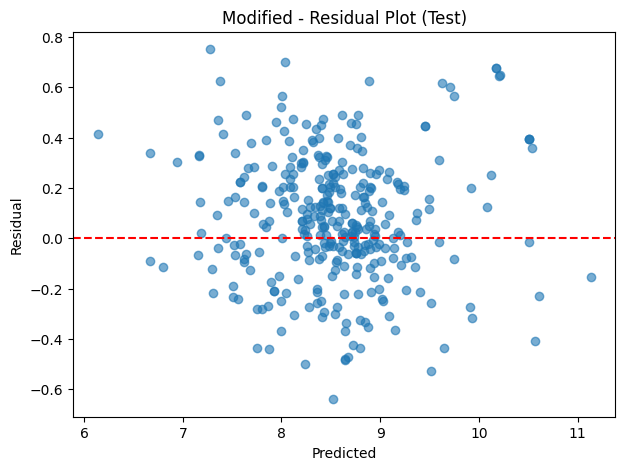

In [ ]:
plot_actual_vs_predicted(y_test, y_test_pred_modified, title="Modified - Actual vs Predicted (Test)")
plot_residuals(y_test, y_test_pred_modified, title="Modified - Residual Plot (Test)")

Ini juga kurang lebih sama dengan baseline model karena perbedaan hasil yang tipis diunggulkan oleh modified model

## 24. Perbandingan 2 model

In [ ]:

# COMPARE MODELS


baseline_test = baseline_eval_results[baseline_eval_results['Dataset'] == 'Test'].copy()
baseline_test['Model'] = 'Baseline'

modified_test = modified_eval_results[modified_eval_results['Dataset'] == 'Test'].copy()
modified_test['Model'] = 'Modified'

comparison_results = pd.concat([baseline_test, modified_test], ignore_index=True)
comparison_results = comparison_results[['Model', 'MAE', 'MSE', 'RMSE', 'R2']]

comparison_results

,Model,MAE,MSE,RMSE,R2
0,Baseline,0.237316,0.089123,0.298535,0.841760
1,Modified,0.207360,0.068883,0.262455,0.877696


## Perbandingan Performa Baseline Model dan Modified Model

Berdasarkan hasil evaluasi, terlihat bahwa modified model memiliki performa yang lebih baik dibandingkan baseline model. Pada baseline model diperoleh MAE sebesar 0.237316, MSE sebesar 0.089123, RMSE sebesar 0.298535, dan R² sebesar 0.841760. Sementara itu, pada modified model diperoleh MAE sebesar 0.207360, MSE sebesar 0.068883, dan RMSE sebesar 0.262455. Nilai error pada modified model lebih rendah secara konsisten, yang menunjukkan bahwa model mampu melakukan prediksi dengan tingkat kesalahan yang lebih kecil dibandingkan baseline.

Perbedaan performa ini dapat dijelaskan dari perbedaan arsitektur dan tingkat regularisasi antara kedua model. Pada baseline model, kedua hidden layer menggunakan jumlah neuron yang sama besar (min_hidden_units), serta dilengkapi dengan L2 regularization dan dropout sebesar 0.30. Kombinasi ini membuat model memiliki regularisasi yang cukup kuat. Meskipun hal ini dapat membantu mencegah overfitting, pada kasus ini justru menyebabkan model menjadi terlalu “dibatasi” dalam proses pembelajaran, sehingga berpotensi mengalami underfitting. Akibatnya, model tidak mampu menangkap seluruh pola kompleks dalam data secara optimal, yang tercermin dari nilai error yang lebih tinggi.

Sebaliknya, pada modified model dilakukan beberapa penyesuaian yang membuat model lebih fleksibel dalam belajar. Hidden layer kedua diperkecil menjadi min_hidden_units // 2, sehingga model memiliki struktur yang lebih bertahap dari kompleks ke sederhana. Selain itu, dropout diturunkan menjadi 0.10 dan L2 regularization dihilangkan. Perubahan ini mengurangi kekuatan regularisasi, sehingga model tidak lagi terlalu dibatasi dan dapat belajar pola data dengan lebih efektif. Dengan kata lain, modified model memiliki keseimbangan yang lebih baik antara kapasitas model dan regularisasi.

Penurunan nilai MAE dari 0.237316 menjadi 0.207360 menunjukkan bahwa secara rata-rata kesalahan prediksi model berkurang secara signifikan. Hal ini berarti prediksi harga kendaraan yang dihasilkan oleh modified model lebih mendekati nilai aktual. Penurunan MSE dan RMSE juga memperkuat bahwa model tidak hanya lebih akurat secara rata-rata, tetapi juga lebih baik dalam mengurangi error besar (outlier prediction).

Secara keseluruhan, hasil ini menunjukkan bahwa peningkatan performa bukan berasal dari penambahan kompleksitas model, melainkan dari penyesuaian arsitektur dan regularisasi yang lebih sesuai dengan karakteristik data. Modified model berhasil memberikan keseimbangan yang lebih baik antara kemampuan belajar dan generalisasi, sehingga menghasilkan performa yang lebih optimal dibandingkan baseline model.

# #Dari pengalaman ini saya mendapatkan inisght baru dalam deep learning bahwa Model yang terlalu kompleks dengan regularisasi tinggi tidak selalu lebih baik, karena dapat menghambat proses pembelajaran. Penyesuaian yang tepat justru menghasilkan performa yang lebih optimal.